# European and American Option Pricing: Binomial Trees, Brownian Motion, Monte Carlo and the Variational PDE

One notebook produces every figure, table and number in `report/main.tex`. Conventions used throughout:

* time is in years, volatility and rates are annualised and continuously compounded, `dt = T/N` is the step of a tree or grid;
* the **hand-written classes** (`BrownianMotion`, `symmetric_random_walk`, `CRRBinomialModel`, `CRRTree`, `gbm_euler_maruyama`, `gbm_exact`, `hedgingformula`, `plotsmart`) are kept as they were written; every extension is a new function, a subclass, or a new cell that *uses* them. Cells that contain extensions start with the tag **[EXT]**;
* numbers quoted in the report are exported to `report/macros.tex` (cell *Export*), so the report never contains a hand-typed result;
* run *Restart & Run All* from the `notebooks/` folder (about 10 minutes).

| Part | content |
|---|---|
| I | Brownian motion as the limit of a scaled random walk (Donsker), exact Kolmogorov distance, reflection principle |
| II | European call on NVDA: CRR tree vs. GBM Monte Carlo vs. Black-Scholes; convergence, variance reduction, Greeks, implied volatility, hedging |
| III | American put: variational PDE, perpetual put, CRR tree, exercise boundary, hedging, P&L, validators (PDE/PSOR, Longstaff-Schwartz, Barone-Adesi-Whaley), dividends |
| IV | Desk summary and export |

In [1]:
# ---- imports, folders, reproducibility ------------------------------------------------------------
import math, random, os, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm, binom, qmc
from scipy.optimize import brentq
from scipy.sparse import diags
from scipy.sparse.linalg import splu

# all hand-written code writes to "figures/..." and "tables/..." relative to the report folder
REPORT_DIR = Path("..") / "report" if Path("../report").exists() else Path("report")
os.chdir(REPORT_DIR)
for d in ("figures", "tables"): Path(d).mkdir(exist_ok=True)

SEED = 314159
random.seed(SEED)                                   # used by the hand-written classes (random module)
def rng_for(k):                                     # independent reproducible numpy stream per experiment
    return np.random.default_rng([SEED, k])

plt.rcParams.update({
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "legend.fontsize": 10,
    "figure.dpi": 100, "savefig.bbox": "tight", "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]   # colour-blind safe
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=PALETTE)

# ---- helpers that export numbers / tables / figures to LaTeX --------------------------------------
MACROS = {}
def macro(name, text):
    # \newcommand{\name}{text}; the name may contain letters only
    assert name.isalpha(), name
    MACROS[name] = str(text)

def save_fig(fig, name, show=True):
    fig.savefig(f"figures/{name}.pdf")
    if show: plt.show()
    else: plt.close(fig)

def write_table(name, header, rows, align):
    # writes only the tabular environment (booktabs); caption and label live in main.tex
    lines = [r"\begin{tabular}{" + align + "}", r"\toprule", " & ".join(header) + r" \\", r"\midrule"]
    lines += [" & ".join(str(c) for c in row) + r" \\" for row in rows]
    lines += [r"\bottomrule", r"\end{tabular}"]
    Path(f"tables/{name}.tex").write_text("\n".join(lines) + "\n")

def timeit(f, *a, **k):
    # one timed call; calls that finish in under 50 ms are repeated five more times and the fastest run is reported
    # (the first call of a function pays import and cache overheads that say nothing about the method)
    t0 = time.perf_counter(); out = f(*a, **k); secs = time.perf_counter() - t0
    if secs < 0.05:
        for _ in range(5):
            t0 = time.perf_counter(); f(*a, **k); secs = min(secs, time.perf_counter() - t0)
    return out, secs

print("numpy", np.__version__, "| matplotlib", matplotlib.__version__, "| cwd", Path.cwd())

numpy 2.5.3 | matplotlib 3.11.2 | cwd /home/user/OptionPricingEuAndAmerican/report


# Part I. Brownian motion as the limit of a scaled random walk

**Definition.** $W=\{W_t\}_{t\ge0}$ is a Brownian motion on $(\Omega,\mathcal F,\{\mathcal F_t\},\mathbb P)$ if (1) $W$ is adapted and $W_0=0$; (2) $W_t-W_s\sim N(0,t-s)$ for $0\le s\le t$; (3) $W_t-W_s$ is independent of $\mathcal F_s$; (4) $t\mapsto W_t(\omega)$ is continuous.

**Scaled walk.** With $\xi_i=\pm1$ with probability $\tfrac12$ each, $W^{(N)}_{t_k}=\sqrt{T/N}\sum_{i\le k}\xi_i$, $t_k=kT/N$. Then $\mathbb E W^{(N)}_{t_k}=0$ and $\operatorname{Var}W^{(N)}_{t_k}=t_k$, so mean and variance match Brownian motion for every $N$. Donsker's theorem says the whole path converges in law to $W$.

In [2]:
# Brownian motion simulated step by step (hand-written class)
class BrownianMotion():
    def __init__(self, N1 = 10_000, time_horizon = [0,1]):
        self.position = 0
        self.path = [0, ]
        self.N1 = N1
        self.time_horizon = time_horizon

    # Run BrownianMotion for one step
    # (independent from previous moves)
    def run(self, step, dim):
        self.position += random.gauss(mu = 0, sigma = step) # only support 1D for now
        self.path.append(self.position)

    def simulate(self):
        steps = self.N1
        interval = self.time_horizon

        dt = (interval[1] - interval[0]) / steps
        for _ in range(steps):
            self.run(step = math.sqrt(dt), dim = 1)
        return self.path # List[]

path_counts = several = 5
simulated_paths = []

for _ in range(path_counts):
   simulated_paths.append(BrownianMotion(N1 = 10_000, time_horizon = [0,1]).simulate())

print([len(p) for p in simulated_paths], [round(p[-1], 3) for p in simulated_paths])   # lengths are 10001, endpoints are N(0,1) draws

[10001, 10001, 10001, 10001, 10001] [1.868, 0.349, -0.751, 1.01, 0.483]


In [3]:
# Symmetric random walk: the same object with +-sqrt(dt) steps (hand-written subclass)
class symmetric_random_walk(BrownianMotion):
    def __init__(self, N2 = 10, time_horizon = [0,1]):
        super().__init__(N1 = N2, time_horizon = time_horizon)
        self.N2 = N2

    def run(self, step, dim):
        self.position += random.choice([step, -step]) # proba 1/2
        self.path.append(self.position)

    def simulate(self):
        steps = self.N2
        interval = self.time_horizon
        dt = (interval[1] - interval[0]) / steps
        for _ in range(steps):
            self.run(step = math.sqrt(dt), dim = 2)
        return self.path # List[]

path_counts = several = 5
simulated_paths = []
for _ in range(path_counts):
   simulated_paths.append(symmetric_random_walk(N2 = 10, time_horizon = [0,1]).simulate())

print(simulated_paths[0])      # 11 points, increments are +-sqrt(1/10) = +-0.3162

simulated_paths = []
for steps in [50, 200, 1000]:
    simulated_paths.append(symmetric_random_walk(N2 = steps, time_horizon = [0,1]).simulate())

print([len(p) for p in simulated_paths])       # [51, 201, 1001]

[0, 0.31622776601683794, 0.6324555320336759, 0.31622776601683794, 0.6324555320336759, 0.31622776601683794, 0.6324555320336759, 0.31622776601683794, 0.0, 0.31622776601683794, 0.0]
[51, 201, 1001]


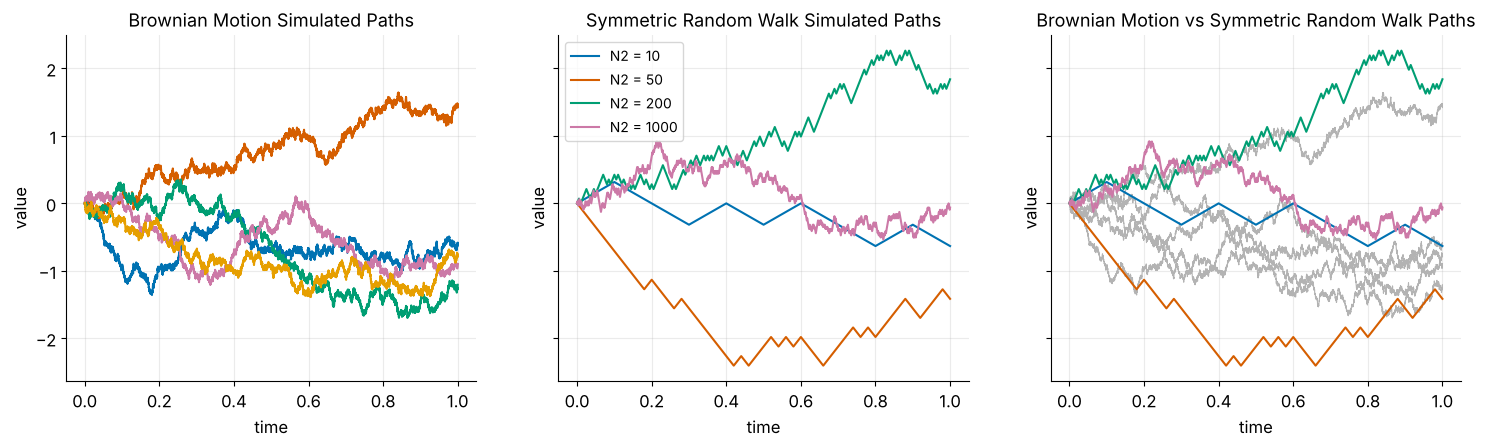

In [4]:
simulated_paths_brownian = []

# Several simulated
for steps in [10_000, 10_000, 10_000, 10_000, 10_000]:
    simulated_paths_brownian.append(BrownianMotion(N1 = steps, time_horizon = [0,1]).simulate())

simulated_paths_symm_RW = []

for steps in [10, 50, 200, 1000]:
    simulated_paths_symm_RW.append(symmetric_random_walk(N2 = steps, time_horizon = [0,1]).simulate())

fig, axes = plt.subplots(1, 3, figsize = (18, 4.5), sharey = True) # 1 row, 3 columns
# paths of different lengths are compared on the common time axis [0,1]
t = lambda path: np.linspace(0, 1, len(path))
# individual plots
axes[0].set_title("Brownian Motion Simulated Paths")
axes[0].set_xlabel("time")
axes[0].set_ylabel("value")
for path in simulated_paths_brownian:
    axes[0].plot(t(path), path)
axes[1].set_title("Symmetric Random Walk Simulated Paths")
axes[1].set_xlabel("time")
axes[1].set_ylabel("value")
for path in simulated_paths_symm_RW:
    axes[1].plot(t(path), path, label = f"N2 = {len(path) - 1}")
axes[1].legend()
# combined plot
axes[2].set_title("Brownian Motion vs Symmetric Random Walk Paths")
axes[2].set_xlabel("time")
axes[2].set_ylabel("value")
for path in simulated_paths_brownian:
    axes[2].plot(t(path), path, color = "0.7", lw = 0.8)
for path in simulated_paths_symm_RW:
    axes[2].plot(t(path), path)

plt.savefig("figures/part1_paths.pdf", bbox_inches = "tight")
plt.show()

# Compare: Brownian paths are continuous but nowhere differentiable. The walk becomes Brownian as N2 grows.

### [EXT] I.A Quadratic and total variation: why both objects are "rough"
For a partition of $[0,1]$ into $N$ steps, the quadratic variation $\sum_k(\Delta W_k)^2\to1$ (for the walk it equals $1$ exactly), while the total variation $\sum_k|\Delta W_k|\sim\sqrt{2N/\pi}\to\infty$. Infinite total variation is what rules out ordinary calculus and forces It\^o calculus, and it is the reason a hedger who rebalances more often never removes the hedging error entirely in the wrong-volatility case (Part II).

In [5]:
# [EXT] quadratic and total variation of the grid paths (vectorised, many paths)
def brownian_grid_paths(N, n_paths, T=1.0, rng=None):
    dW = math.sqrt(T / N) * rng.standard_normal((n_paths, N))
    return np.concatenate([np.zeros((n_paths, 1)), np.cumsum(dW, axis=1)], axis=1)

def scaled_walk_grid_paths(N, n_paths, T=1.0, rng=None):
    xi = rng.choice([-1.0, 1.0], size=(n_paths, N))
    return np.concatenate([np.zeros((n_paths, 1)), math.sqrt(T / N) * np.cumsum(xi, axis=1)], axis=1)

Ns_var = [10, 50, 200, 1000, 10_000]
rows, qv_bm, tv_bm, qv_rw, tv_rw = [], [], [], [], []
for i, N in enumerate(Ns_var):
    Wb = brownian_grid_paths(N, 2000, rng=rng_for(1 + i)); Wr = scaled_walk_grid_paths(N, 2000, rng=rng_for(11 + i))
    qb, tb = (np.diff(Wb, axis=1) ** 2).sum(1), np.abs(np.diff(Wb, axis=1)).sum(1)
    qr, tr = (np.diff(Wr, axis=1) ** 2).sum(1), np.abs(np.diff(Wr, axis=1)).sum(1)
    qv_bm.append(qb.mean()); tv_bm.append(tb.mean()); qv_rw.append(qr.mean()); tv_rw.append(tr.mean())
    rows.append([f"{N:,}", f"{qb.mean():.4f} ({qb.std():.3f})", f"{qr.mean():.4f}", f"{tb.mean():.2f}", f"{tr.mean():.2f}", f"{math.sqrt(2*N/math.pi):.2f}"])
    print(f"N={N:>6}: QV BM {qb.mean():.4f} (sd {qb.std():.4f}), QV walk {qr.mean():.4f}; TV BM {tb.mean():.2f}, TV walk {tr.mean():.2f}, sqrt(2N/pi) = {math.sqrt(2*N/math.pi):.2f}")
write_table("variation", [r"$N$", r"QV Brownian (sd)", r"QV walk", r"TV Brownian", r"TV walk", r"$\sqrt{2N/\pi}$"], rows, "rccccc")
macro("QVBMtenk", f"{qv_bm[-1]:.4f}"); macro("TVBMtenk", f"{tv_bm[-1]:.1f}"); macro("TVtheorytenk", f"{math.sqrt(2*Ns_var[-1]/math.pi):.1f}")

N=    10: QV BM 1.0092 (sd 0.4443), QV walk 1.0000; TV BM 2.54, TV walk 3.16, sqrt(2N/pi) = 2.52
N=    50: QV BM 1.0074 (sd 0.2012), QV walk 1.0000; TV BM 5.66, TV walk 7.07, sqrt(2N/pi) = 5.64
N=   200: QV BM 1.0028 (sd 0.1018), QV walk 1.0000; TV BM 11.30, TV walk 14.14, sqrt(2N/pi) = 11.28
N=  1000: QV BM 0.9974 (sd 0.0439), QV walk 1.0000; TV BM 25.20, TV walk 31.62, sqrt(2N/pi) = 25.23


N= 10000: QV BM 1.0000 (sd 0.0145), QV walk 1.0000; TV BM 79.79, TV walk 100.00, sqrt(2N/pi) = 79.79


### [EXT] I.B Distance between the terminal laws (exact Kolmogorov distance)
Visual agreement is not a proof. At $t=1$ the walk equals $(2B-N)/\sqrt N$ with $B\sim\mathrm{Bin}(N,\tfrac12)$, so its CDF is known exactly and the Kolmogorov distance $\sup_x|F_N(x)-\Phi(x)|$ can be computed without sampling error. By the Berry-Esseen theorem it is $O(N^{-1/2})$; for the symmetric walk the limit constant is $\varphi(0)=1/\sqrt{2\pi}\approx0.399$ (half the probability mass $2\varphi(0)/\sqrt N$ of the central lattice cell, because the CDF jumps by that mass at the mode).

N2 =      10: KS = 0.12305,  KS*sqrt(N) = 0.3891
N2 =      50: KS = 0.05614,  KS*sqrt(N) = 0.3970
N2 =     200: KS = 0.02817,  KS*sqrt(N) = 0.3984
N2 =    1000: KS = 0.01261,  KS*sqrt(N) = 0.3988
N2 =   10000: KS = 0.00399,  KS*sqrt(N) = 0.3989
N2 =  100000: KS = 0.00126,  KS*sqrt(N) = 0.3989


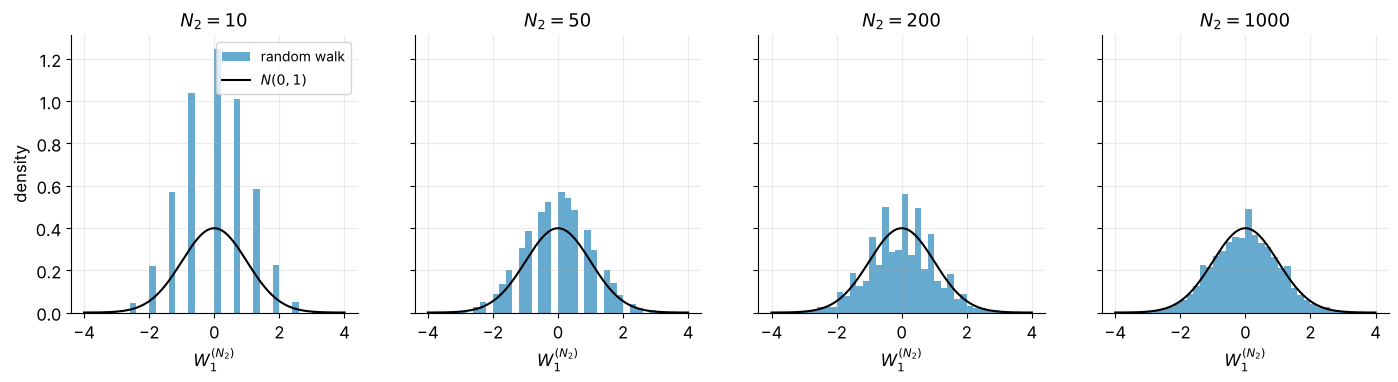

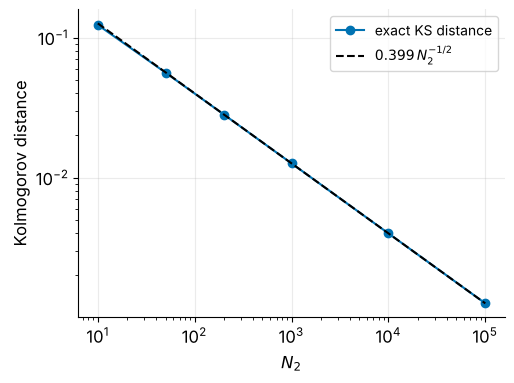

In [6]:
# [EXT] exact Kolmogorov distance of the scaled walk at t = 1 to N(0,1)
def ks_distance_to_normal(N):
    # sup_x |P(W^(N)_1 <= x) - Phi(x)| : the CDF is a step function, so check both sides of every jump
    k = np.arange(N + 1)
    x = (2 * k - N) / np.sqrt(N)
    right = binom.cdf(k, N, 0.5)
    left = np.concatenate([[0.0], right[:-1]])
    return max(np.abs(right - norm.cdf(x)).max(), np.abs(left - norm.cdf(x)).max())

N_ks = [10, 50, 200, 1000, 10_000, 100_000]
ks = {N: ks_distance_to_normal(N) for N in N_ks}
for N in N_ks: print(f"N2 = {N:>7}: KS = {ks[N]:.5f},  KS*sqrt(N) = {ks[N]*math.sqrt(N):.4f}")
write_table("ks_table", [r"$N_2$", r"$\sup_x|F_{N_2}(x)-\Phi(x)|$", r"$\times\sqrt{N_2}$"],
            [[f"{N:,}", f"{ks[N]:.5f}", f"{ks[N]*math.sqrt(N):.3f}"] for N in N_ks], "rcc")
macro("KSconst", f"{ks[100_000]*math.sqrt(100_000):.3f}")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
xs = np.linspace(-4, 4, 400)
N2_list = [10, 50, 200, 1000]
for k, (ax, N2) in enumerate(zip(axes, N2_list)):
    Wr = scaled_walk_grid_paths(N2, 20_000, rng=rng_for(30 + k))
    ax.hist(Wr[:, -1], bins=np.linspace(-4, 4, 41), density=True, alpha=0.6, label="random walk")
    ax.plot(xs, norm.pdf(xs), "k", lw=1.5, label=r"$N(0,1)$")
    ax.set(xlabel=r"$W^{(N_2)}_1$", title=fr"$N_2={N2}$")
axes[0].legend(); axes[0].set_ylabel("density")
save_fig(fig, "rw_terminal_hist")

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(N_ks, [ks[N] for N in N_ks], "o-", label="exact KS distance")
ax.loglog(N_ks, [0.3989 / math.sqrt(N) for N in N_ks], "k--", label=r"$0.399\,N_2^{-1/2}$")
ax.set(xlabel="$N_2$", ylabel="Kolmogorov distance"); ax.legend()
save_fig(fig, "ks_rate")

### [EXT] I.C Path functionals: the running maximum and the reflection principle
A functional of the whole path converges too (this is Donsker, not just the CLT). For Brownian motion, $\mathbb P(\max_{s\le1}W_s\ge a)=2\,\mathbb P(W_1\ge a)=2(1-\Phi(a))$. For the simple symmetric walk the reflection principle holds exactly on the lattice, $\mathbb P(\max_{n\le N}S_n\ge k)=\mathbb P(S_N\ge k)+\mathbb P(S_N>k)$. The running maximum is the quantity that drives barrier options, so this is the first place where discretisation bias matters in practice (a discretely monitored barrier is crossed less often than a continuously monitored one).

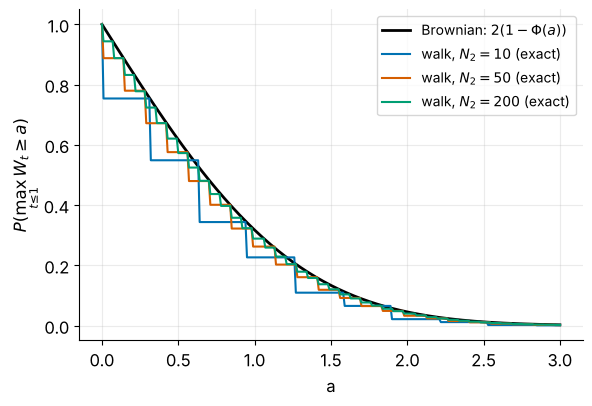

sup distance of running-max survival functions: {10: np.float64(0.2381), 50: np.float64(0.1043), 200: np.float64(0.0487), 1000: np.float64(0.0245)}


In [7]:
# [EXT] distribution of the running maximum: walk (exact) vs Brownian motion (reflection principle)
def walk_max_survival(N, a):
    # P(max_{n<=N} W^(N)_{t_n} >= a) for the scaled walk, exact via reflection on the lattice
    k = np.ceil(a * math.sqrt(N) - 1e-12).astype(int)           # smallest integer level >= a sqrt(N)
    SN = lambda j: binom.sf(np.ceil((N + j) / 2) - 1, N, 0.5)   # P(S_N >= j) with S_N = 2B - N
    return SN(k) + binom.sf(np.floor((N + k) / 2), N, 0.5)       # P(S_N >= k) + P(S_N > k)

a_grid = np.linspace(0, 3, 301)
fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.plot(a_grid, 2 * norm.sf(a_grid), "k", lw=2, label=r"Brownian: $2(1-\Phi(a))$")
for N in (10, 50, 200):
    ax.plot(a_grid, walk_max_survival(N, a_grid), label=f"walk, $N_2={N}$ (exact)")
ax.set(xlabel="a", ylabel=r"$P(\max_{t\leq 1}W_t\geq a)$"); ax.legend()
save_fig(fig, "running_max")
gap = {N: np.abs(walk_max_survival(N, a_grid) - 2 * norm.sf(a_grid)).max() for N in (10, 50, 200, 1000)}
print("sup distance of running-max survival functions:", {k: round(v, 4) for k, v in gap.items()})
macro("MaxGapTen", f"{gap[10]:.3f}"); macro("MaxGapTwoHundred", f"{gap[200]:.3f}")

# Part II. European call on NVDA: CRR binomial tree vs. GBM Monte Carlo vs. Black-Scholes

## II.1 Data and assumptions
The underlying is NVIDIA (NVDA), closing price \$238.90 on 2026-10-05 (yfinance). The option is a 1-year at-the-money European call, $K=S_0$. The risk-free rate is the Bank of Canada 1-year T-bill yield on the same date, $r=2.9\%$ (continuously compounded for convenience). The volatility is the annualised standard deviation of the last 250 daily log returns, $\sigma=37.7254\%$, assuming no regime change. Time is measured in trading years, $T=252/252=1$. NVDA's small dividend is ignored ($q=0$); a dividend yield is introduced in Part III.

| symbol | value | meaning |
|---|---|---|
| $S_0=K$ | 238.90 | spot and strike (at the money) |
| $r$ | 0.029 | risk-free rate |
| $\sigma$ | 0.377254 | historical volatility, 252-day annualisation |
| $T$ | 1 | maturity (252 trading days) |
| $\mu$ | 0.10 | real-world drift, only used for illustrating sample paths and for hedging experiments under $\mathbb P$ |

In [8]:
RUN_LIVE_DATA = False       # True: refresh S0 and sigma from yfinance (needs internet); False: use the frozen values below

if RUN_LIVE_DATA:
    import time, math
    import yfinance as yf
    from datetime import datetime, timedelta

    ticker = yf.Ticker("NVDA")
    hist = ticker.history(start="2026-10-05", end="2026-10-06")
    price = price_ex = price_close = float(hist["Close"].iloc[0])

    end_date = datetime(2026, 10, 5)
    start_date = end_date - timedelta(days=252)
    data = yf.download("NVDA", start=start_date.strftime("%Y-%m-%d"),
                       end=(end_date + timedelta(days=1)).strftime("%Y-%m-%d"), interval="1d", auto_adjust=True)
    closes = data["Close"].iloc[:, 0]                      # ensure it is a Series
    log_returns = np.log(closes / closes.shift(1)).dropna() # daily log returns
    daily_vol = log_returns.std()
    annualized_252_volatility = float(daily_vol * np.sqrt(252))
    print(f"{len(log_returns)} returns, daily vol {daily_vol:.6f}, annualised {annualized_252_volatility:.4%}")
else:
    price = price_ex = price_close = 238.90                # close on 2026-10-05 (yfinance)
    annualized_252_volatility = 0.377254                   # annualised vol of 250 daily log returns (252-day convention)
risk_free_CAD_rate = 0.029                                 # Bank of Canada 1-year T-bill, 2026-10-05

# parameter block of Part II (the American part defines its own block further below)
S0 = S = K = price
sigma = annualized_252_volatility
r = risk_free_CAD_rate
T = 1.0
mu = 0.10
print(f"S0 = K = {S0}, r = {r}, sigma = {sigma}, T = {T}")
macro("NvdaS", f"{S0:.2f}"); macro("NvdaR", f"{100*r:.1f}"); macro("NvdaSigma", f"{100*sigma:.2f}")

S0 = K = 238.9, r = 0.029, sigma = 0.377254, T = 1.0


## II.2 The CRR binomial model
With $\Delta t=T/N$: $u=e^{\sigma\sqrt{\Delta t}}$, $d=1/u$, $p=\dfrac{e^{r\Delta t}-d}{u-d}$. The stock tree is built forward, $S_{j,i}=S_0u^{2i-j}$ ($i$ up-moves after $j$ steps), and the option tree backward from the payoff, $V_{j,i}=e^{-r\Delta t}(pV_{j+1,i+1}+(1-p)V_{j+1,i})$. The class below is the hand-written all-in-one model (stock tree, option tree, pricing, simulation, plots). It must be run in the order `generate_stock_tree()`, `generate_option_tree()`, `pricing()`.

In [9]:
# This is the all-in-one CRRBinomialModel object, supporting generating stock tree, option tree, and pricing afterwards. (Must be ran in this sequence.) Also supports simulating paths.
class CRRBinomialModel():
    def __init__(self, initial_stock_value = 1, rate = risk_free_CAD_rate, volatility = annualized_252_volatility, steps = 100, days = 30, strike_price = 3):
        self.strike_price = strike_price
        self.initial_stock_value = initial_stock_value
        self.days = days
        self.rate = rate
        self.volatility = volatility
        self.steps = steps
        self.T = days / 252
        self.stepsize = self.T / steps
        self.u = math.exp(volatility * math.sqrt(self.stepsize)) # u = e^{sigma sqrt(dt)}
        self.d = 1 / self.u
        self.risk_neutral_p = (math.exp(rate * self.stepsize) - self.d) / (self.u - self.d) # p = (e^{r dt} - d)/(u - d)
        self.risk_neutral_q = 1 - self.risk_neutral_p
        self.stock_tree = []
        self.option_tree = []

    def clear_tree(self):
        self.stock_tree = []
        self.option_tree = []

    def generate_stock_tree(self):
        self.clear_tree()

        # O(N) with 2 base cases: (assume at least 1 period) every round compute two numbers and copy an existing list
        self.stock_tree.append([self.initial_stock_value]) # period0
        self.stock_tree.append([self.initial_stock_value * self.d, self.initial_stock_value * self.u]) # period1

        for day in range(self.steps - 1):
            self.stock_tree.append([self.stock_tree[-2][0] * (self.d ** 2)] + self.stock_tree[-2] + [self.stock_tree[-2][-1] * (self.u ** 2)])

        # Stock tree done, then generate option tree backward induction
        return self.stock_tree

    def generate_option_tree(self):
        import numpy as np
        import copy
        self.option_tree = copy.deepcopy(self.stock_tree)

        last_day_values = []
        for elem in self.option_tree[-1]:
            elem -= self.strike_price
            elem = max(elem, 0)
            last_day_values.append(elem)
        self.option_tree[-1] = last_day_values

        # across days
        for i in range(len(self.option_tree)-2, -1, -1):
            # across values in a day
            for j in range(len(self.option_tree[i])-1, -1, -1):

                deltai = (self.option_tree[i+1][j] - self.option_tree[i+1][j+1]) / (self.stock_tree[i+1][j] - self.stock_tree[i+1][j+1])

                xi = vi = math.exp(-self.rate * self.stepsize) * (self.risk_neutral_p * self.option_tree[i+1][j+1] + self.risk_neutral_q * self.option_tree[i+1][j])

                self.option_tree[i][j] = vi

        return self.option_tree

    # Need to have had a tree
    def pricing(self):
        return self.option_tree[0][0]

    def simulate_stock(self):
        value = self.initial_stock_value
        path = [value]

        j = 0
        for i in range(self.steps):
            j += 1 if random.random() < self.risk_neutral_p else 0
            value = self.stock_tree[i + 1][j]
            path.append(value)

        days_per_step = self.stepsize * 252
        x = [i * days_per_step for i in range(len(path))]

        plt.plot(x, path)
        plt.xlabel("Days")
        plt.ylabel("Stock Value")
        plt.title(f"Stock Simulation N={self.steps}")
        return path

    def simulate_option(self):
        value = self.option_tree[0][0]
        path = [value]

        j = 0
        for i in range(self.steps):
            j += 1 if random.random() < self.risk_neutral_p else 0
            value = self.option_tree[i + 1][j]
            path.append(value)

        days_per_step = self.stepsize * 252
        x = [i * days_per_step for i in range(len(path))]

        plt.plot(x, path)
        plt.xlabel("Days")
        plt.ylabel("Option Value")
        plt.title(f"Option Simulation N={self.steps}")
        return path

    def plot_stock_tree(self, fname = "binomial_stock_tree.png"):
        for i, level in enumerate(self.stock_tree):
            plt.scatter([i] * len(level), level, color = "C0", s = 12)
        plt.title(f"CRRBinomialStockTreeN{self.steps}")
        plt.xlabel("Days")
        plt.ylabel("Price")
        plt.savefig(fname, bbox_inches = "tight")
        plt.show()

    def plot_option_tree(self, fname = "binomial_stock_tree.png"):
        for i, level in enumerate(self.option_tree):
            plt.scatter([i] * len(level), level, color = "C0", s = 12)
        plt.title(f"CRRBinomialOptionTreeN{self.steps}")
        plt.xlabel("Days")
        plt.ylabel("Price")
        plt.savefig(fname, bbox_inches = "tight")
        plt.show()

### Black-Scholes benchmark and the first comparison
Under the risk-neutral measure the call is worth $S_0\Phi(d_1)-Ke^{-rT}\Phi(d_2)$ with $d_{1,2}=\dfrac{\ln(S_0/K)+(r\pm\sigma^2/2)T}{\sigma\sqrt T}$.

In [10]:
K = S = price # strike price == NVDA stock price

# Here we check our simulation with Black-Scholes' exact answers
from scipy.stats import norm
def black_scholes_call(S0, K, r, sigma, T):
    d1 = (math.log(S0 / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    return S0 * norm.cdf(d1) - K * math.exp(-r * T) * norm.cdf(d2)

BS = black_scholes_call(S0 = S, K = K, r = risk_free_CAD_rate, sigma = annualized_252_volatility, T = 1.0) # T = 1.0 means 1 year; multiplied by the rate
print(f"Black-Scholes call = {BS:.4f}")
macro("BSprice", f"{BS:.4f}")

Ns = [5, 10, 25, 50, 100, 200, 500]
for N in Ns:
    model = CRRBinomialModel(initial_stock_value = S, strike_price = K, steps = N, days = 252)
    model.generate_stock_tree()
    model.generate_option_tree()
    print(f"N = {N}\t: CRR price = {model.pricing():.4f} \t error against Black-Scholes = {model.pricing() - BS:+.4f}")

Black-Scholes call = 38.7493
N = 5	: CRR price = 40.4839 	 error against Black-Scholes = +1.7347
N = 10	: CRR price = 37.8785 	 error against Black-Scholes = -0.8708
N = 25	: CRR price = 39.0918 	 error against Black-Scholes = +0.3425
N = 50	: CRR price = 38.5731 	 error against Black-Scholes = -0.1762
N = 100	: CRR price = 38.6611 	 error against Black-Scholes = -0.0882
N = 200	: CRR price = 38.7051 	 error against Black-Scholes = -0.0441
N = 500	: CRR price = 38.7316 	 error against Black-Scholes = -0.0177


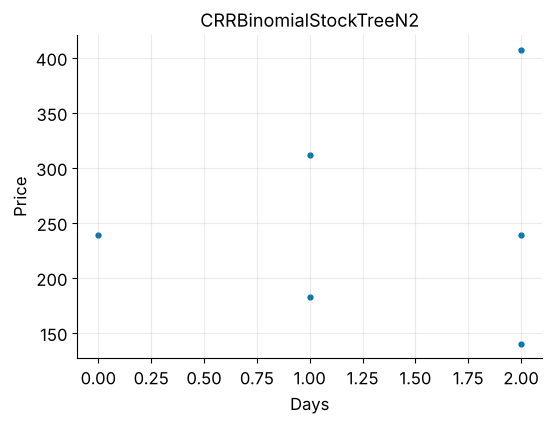

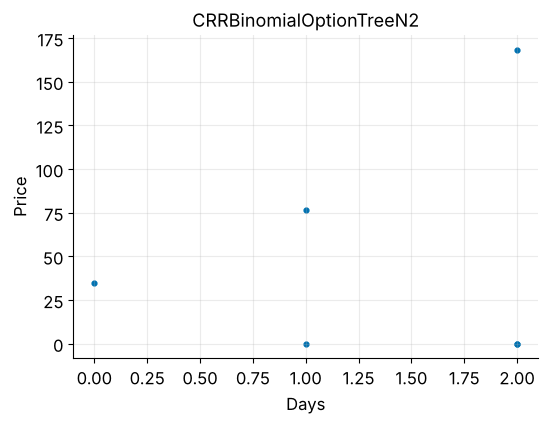

N = 2: price = 34.7300


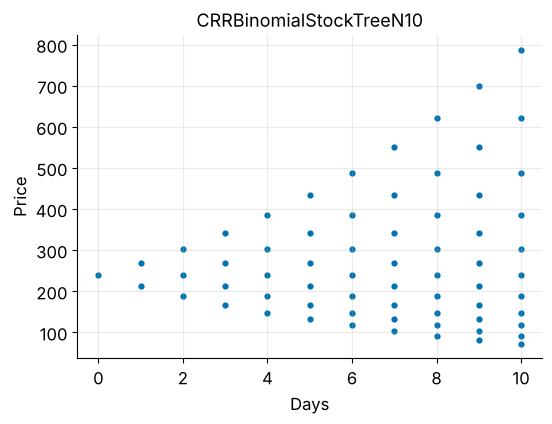

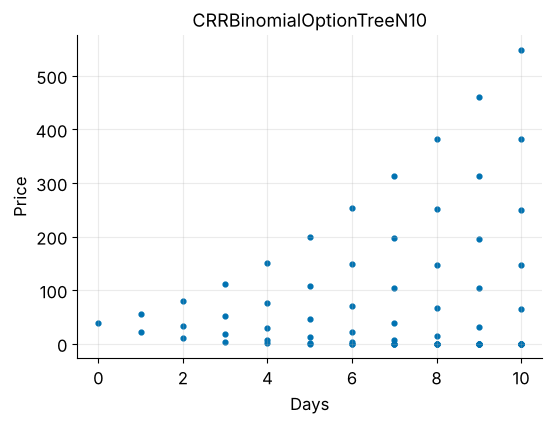

N = 10: price = 37.8785


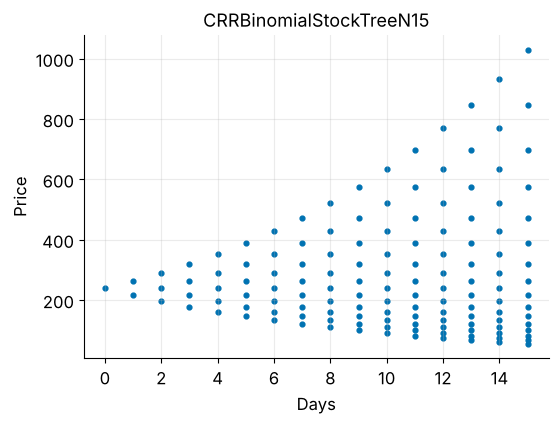

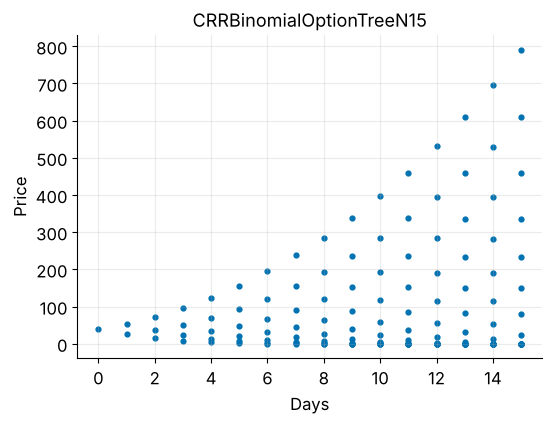

N = 15: price = 39.3216


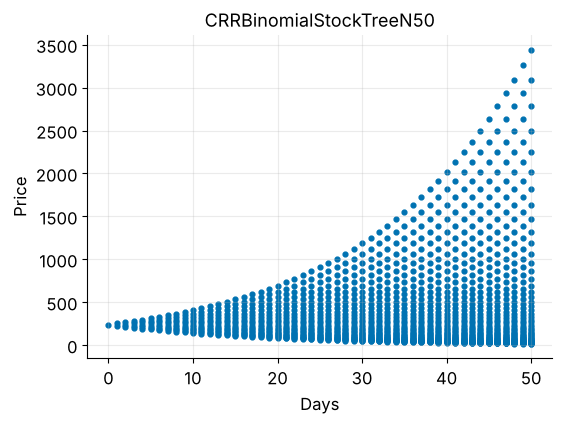

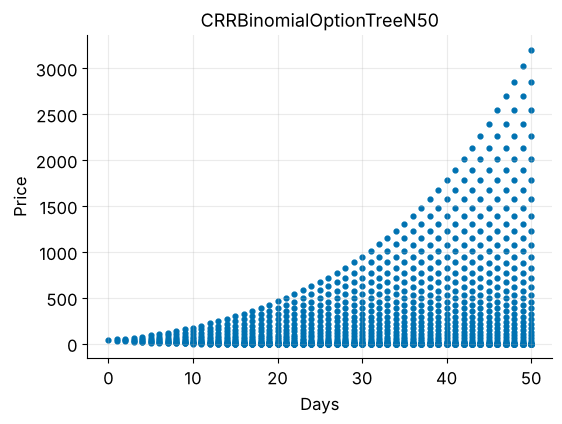

N = 50: price = 38.5731


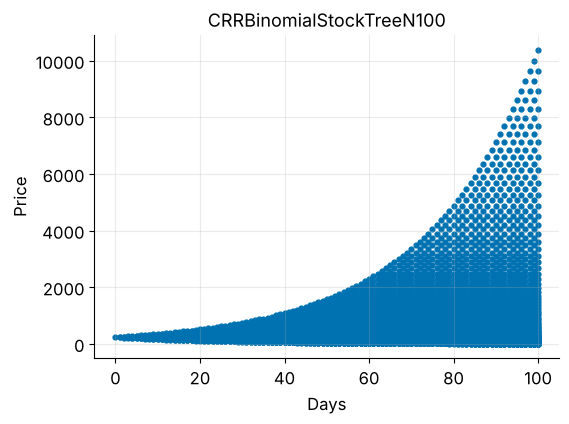

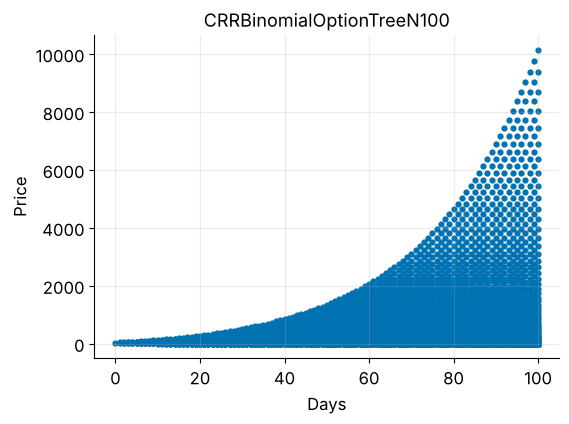

N = 100: price = 38.6611


In [11]:
# We also draw the trees themselves, only for small N (a tree with 100 steps is unreadable as a scatter, but is kept for the appendix)
for N in [2, 10, 15, 50, 100]:
    model = CRRBinomialModel(initial_stock_value = S, strike_price = K, rate = risk_free_CAD_rate, volatility = annualized_252_volatility, steps = N, days = 252)
    model.generate_stock_tree()
    model.generate_option_tree()
    plt.figure(figsize = (6, 4.2)); plt.grid(alpha = 0.25)
    model.plot_stock_tree(fname = f"figures/crr_stock_tree_N{N}.pdf")
    plt.figure(figsize = (6, 4.2)); plt.grid(alpha = 0.25)
    model.plot_option_tree(fname = f"figures/crr_option_tree_N{N}.pdf")
    plt.close("all")
    print(f"N = {N}: price = {model.pricing():.4f}")

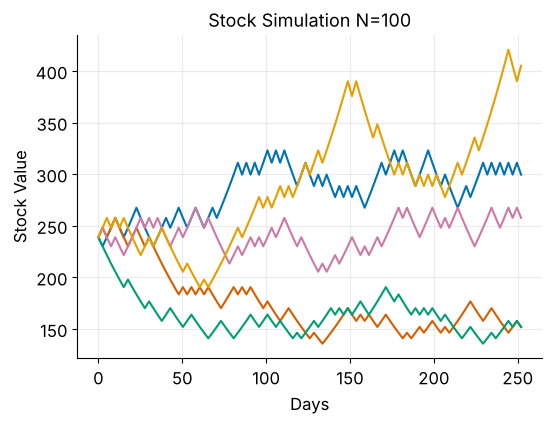

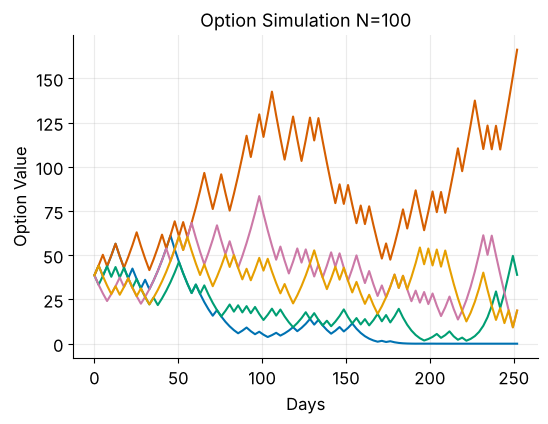

In [12]:
# sample paths in the tree: stock and option simulations are independently run (N = 100, 5 paths each, risk-neutral probabilities)
model = CRRBinomialModel(initial_stock_value = S, strike_price = K, rate = risk_free_CAD_rate, volatility = annualized_252_volatility, steps = 100, days = 252)
model.generate_stock_tree()
model.generate_option_tree()
plt.figure(figsize = (6, 4.2)); plt.grid(alpha = 0.25)
for _ in range(5):
    model.simulate_stock()
plt.savefig("figures/simulate_stocks.pdf", bbox_inches = "tight")
plt.show(); plt.close("all")

plt.figure(figsize = (6, 4.2)); plt.grid(alpha = 0.25)
for _ in range(5):
    model.simulate_option()
plt.savefig("figures/simulate_options.pdf", bbox_inches = "tight")
plt.show(); plt.close("all")

## II.3 Geometric Brownian motion
**Solution of the SDE.** For $dS_t=\mu S_t\,dt+\sigma S_t\,dW_t$, It\^o's formula for $f(S)=\ln S$ ($f'=1/S$, $f''=-1/S^2$) gives $d\ln S_t=\dfrac{dS_t}{S_t}-\dfrac12\dfrac{(dS_t)^2}{S_t^2}=(\mu-\tfrac12\sigma^2)dt+\sigma\,dW_t$, hence $S_t=S_0\exp\big((\mu-\tfrac12\sigma^2)t+\sigma W_t\big)$, a lognormal with $\mathbb E S_t=S_0e^{\mu t}$. Under the risk-neutral measure $\mu$ is replaced by $r$ (Girsanov).

**Simulation.** Euler-Maruyama: $S_{n+1}=S_n+\mu S_n\Delta t+\sigma S_n\Delta W_n$. Exact (log-Euler) step: $S_{n+1}=S_n\exp((\mu-\tfrac12\sigma^2)\Delta t+\sigma\sqrt{\Delta t}Z_n)$. Both are fed the same random numbers below, so any difference is discretisation error.

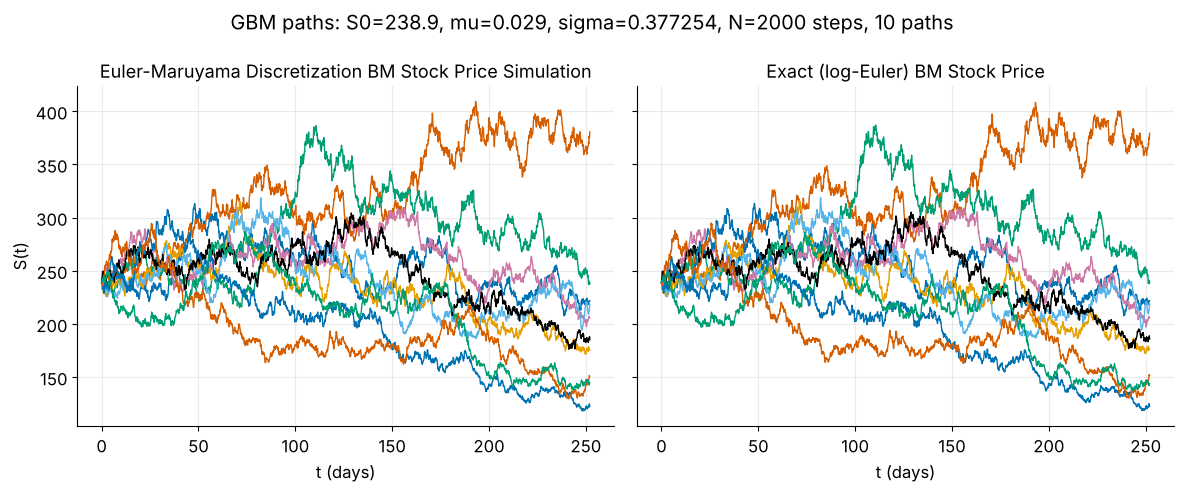

Final EM prices:    [221.63 380.6  238.83 205.72 175.48 218.49 185.3  122.73 150.87 144.55]
Final exact prices: [221.67 379.4  239.59 205.54 176.07 218.86 186.04 123.03 151.62 143.99]
max |EM - exact| over all paths and times: 1.2118948532200875


In [13]:
import numpy as np
import matplotlib.pyplot as plt

# euler_maruyama discretization
def gbm_euler_maruyama(S0, mu, sigma, T, N, n_paths=1, seed=None):
    # Euler-Maruyama simulation of GBM: S_{n+1} = S_n + mu*S_n*dt + sigma*S_n*dW_n
    rng = np.random.default_rng(seed)
    dt = T / N
    t = np.linspace(0, T, N + 1)

    Z = rng.standard_normal((n_paths, N))
    dW = np.sqrt(dt) * Z

    S = np.empty((n_paths, N + 1))
    S[:, 0] = S0

    for n in range(N):
        S[:, n + 1] = S[:, n] + mu * S[:, n] * dt + sigma * S[:, n] * dW[:, n]

    return t, S

# This is the closed form solution for GBM for checking against the simulation:
def gbm_exact(S0, mu, sigma, T, N, n_paths=1, seed=None):
    # Exact (log-Euler) simulation of GBM for comparison: S_{n+1} = S_n * exp((mu - 0.5*sigma^2)*dt + sigma*sqrt(dt)*Z_n)
    rng = np.random.default_rng(seed)
    dt = T / N
    t = np.linspace(0, T, N + 1)

    Z = rng.standard_normal((n_paths, N))
    increments = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    log_S = np.log(S0) + np.cumsum(increments, axis=1)

    S = np.empty((n_paths, N + 1))
    S[:, 0] = S0
    S[:, 1:] = np.exp(log_S)

    return t, S

S0, mu, sigma, T, N, n_paths = price, risk_free_CAD_rate, annualized_252_volatility, 1.0, 2_000, 10

seed = SEED # same seed for both schemes, so both see the same random numbers
t, S_em = gbm_euler_maruyama(S0, mu, sigma, T, N, n_paths, seed=seed)
_, S_exact = gbm_exact(S0, mu, sigma, T, N, n_paths, seed=seed)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

t_days = t * 252
axes[0].plot(t_days, S_em.T, lw=1)
axes[0].set_title("Euler-Maruyama Discretization BM Stock Price Simulation")
axes[0].set_xlabel("t (days)")
axes[0].set_ylabel("S(t)")

axes[1].plot(t_days, S_exact.T, lw=1)
axes[1].set_title("Exact (log-Euler) BM Stock Price")
axes[1].set_xlabel("t (days)")

fig.suptitle(f"GBM paths: S0={S0}, mu={mu}, sigma={sigma}, N={N} steps, {n_paths} paths")
fig.tight_layout()

fig.savefig("figures/gbm_paths.pdf")
plt.show()

print(f"Final EM prices:    {np.round(S_em[:, -1], 2)}")
print(f"Final exact prices: {np.round(S_exact[:, -1], 2)}")
print("max |EM - exact| over all paths and times:", np.abs(S_em - S_exact).max())
S0, mu = price, 0.10          # back to the Part II parameter block (the cell above reused mu for the risk-neutral illustration)

## II.4 [EXT] Black-Scholes toolbox: all prices, Greeks, parity and implied volatility
The closed forms are the yardstick for everything else. With $\varphi$ the standard normal density and continuous dividend yield $q$ (zero for the NVDA case):
$$\Delta_c=e^{-qT}\Phi(d_1),\quad \Gamma=\frac{e^{-qT}\varphi(d_1)}{S\sigma\sqrt T},\quad \mathcal V=Se^{-qT}\varphi(d_1)\sqrt T,\quad \rho_c=KTe^{-rT}\Phi(d_2),$$
$$\Theta_c=-\frac{Se^{-qT}\varphi(d_1)\sigma}{2\sqrt T}-rKe^{-rT}\Phi(d_2)+qSe^{-qT}\Phi(d_1),$$
and for the put $\Delta_p=\Delta_c-e^{-qT}$, $\rho_p=-KTe^{-rT}\Phi(-d_2)$, with $\Gamma$ and $\mathcal V$ unchanged. Put-call parity $C-P=Se^{-qT}-Ke^{-rT}$ is used as a unit test.

call 38.7493  put 31.9207  parity residual 1.42e-14
{'delta': 0.60469, 'gamma': 0.00427, 'vega': 92.00674, 'theta': -20.42056, 'rho': 105.7105}
implied vol recovered from the BS call price: 0.37725399999998666


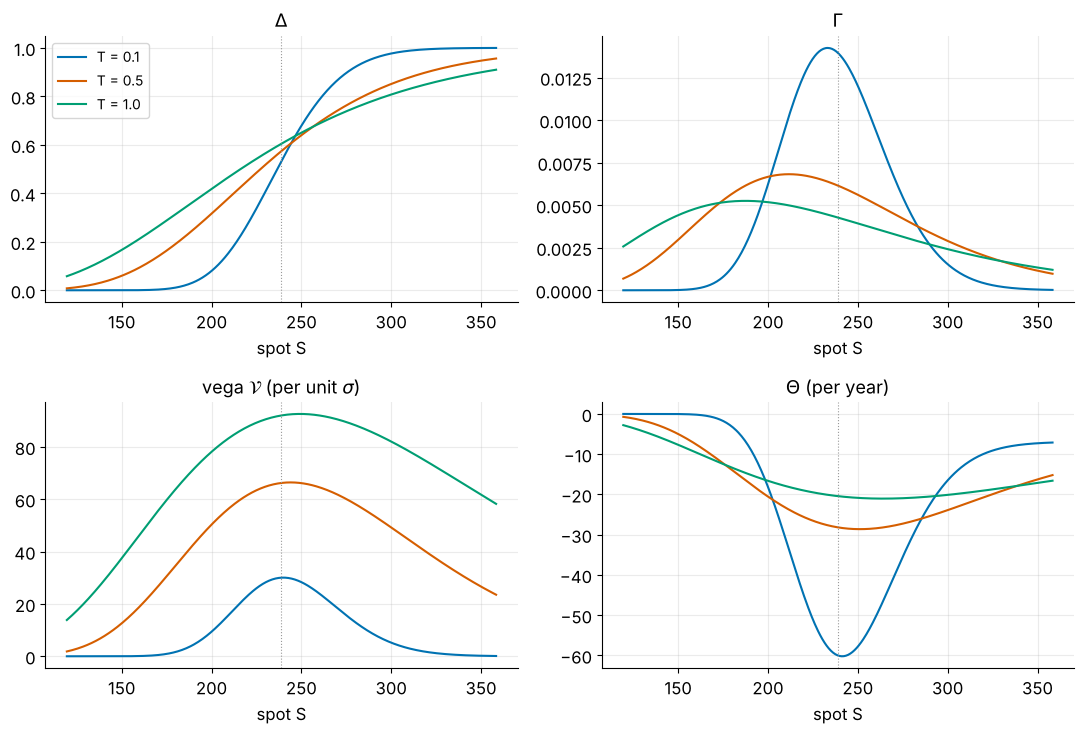

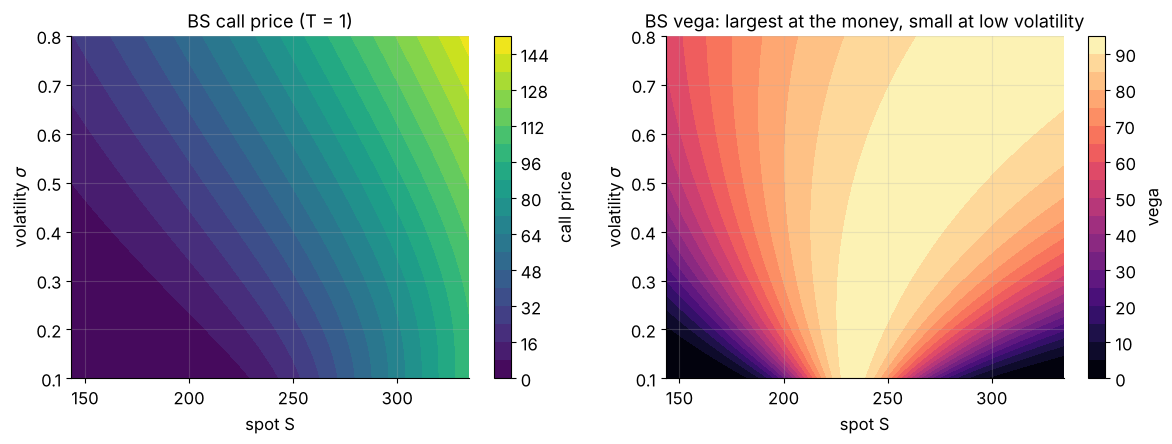

In [14]:
# [EXT] closed-form price, Greeks and implied volatility (they use, and are checked against, black_scholes_call above)
def bs_d1d2(S, K, r, sigma, T, q=0.0):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return d1, d1 - sigma * np.sqrt(T)

def bs_price(S, K, r, sigma, T, kind="call", q=0.0):
    d1, d2 = bs_d1d2(S, K, r, sigma, T, q)
    if kind == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)

def bs_greeks(S, K, r, sigma, T, kind="call", q=0.0):
    d1, d2 = bs_d1d2(S, K, r, sigma, T, q)
    pdf, eq, er = norm.pdf(d1), np.exp(-q * T), np.exp(-r * T)
    gamma = eq * pdf / (S * sigma * np.sqrt(T)); vega = S * eq * pdf * np.sqrt(T)
    if kind == "call":
        delta = eq * norm.cdf(d1); rho = K * T * er * norm.cdf(d2)
        theta = -S * eq * pdf * sigma / (2 * np.sqrt(T)) - r * K * er * norm.cdf(d2) + q * S * eq * norm.cdf(d1)
    else:
        delta = eq * (norm.cdf(d1) - 1); rho = -K * T * er * norm.cdf(-d2)
        theta = -S * eq * pdf * sigma / (2 * np.sqrt(T)) + r * K * er * norm.cdf(-d2) - q * S * eq * norm.cdf(-d1)
    return dict(delta=delta, gamma=gamma, vega=vega, theta=theta, rho=rho)

def implied_vol(price_obs, S, K, r, T, kind="call", q=0.0, lo=1e-4, hi=5.0):
    # Brent root of bs_price(sigma) - price (bs_price is strictly increasing in sigma, so the root is unique)
    f = lambda s: bs_price(S, K, r, s, T, kind, q) - price_obs
    if f(lo) > 0 or f(hi) < 0: return np.nan
    return brentq(f, lo, hi, xtol=1e-12)

assert abs(bs_price(S0, K, r, sigma, T) - black_scholes_call(S0, K, r, sigma, T)) < 1e-12
parity = bs_price(S0, K, r, sigma, T, "call") - bs_price(S0, K, r, sigma, T, "put") - (S0 - K * math.exp(-r * T))
G = bs_greeks(S0, K, r, sigma, T)
BSput = bs_price(S0, K, r, sigma, T, "put")
print(f"call {BS:.4f}  put {BSput:.4f}  parity residual {parity:.2e}")
print({k: round(float(v), 5) for k, v in G.items()})
print("implied vol recovered from the BS call price:", implied_vol(BS, S0, K, r, T))
macro("BSput", f"{BSput:.4f}"); macro("BSdelta", f"{G['delta']:.4f}"); macro("BSgamma", f"{G['gamma']:.5f}")
macro("BSvega", f"{G['vega']:.2f}"); macro("BSvegaPct", f"{G['vega']/100:.3f}"); macro("BStheta", f"{G['theta']:.2f}")
macro("BSthetaDay", f"{G['theta']/365:.3f}"); macro("BSrho", f"{G['rho']:.2f}"); macro("BSrhoPct", f"{G['rho']/100:.3f}")
d1_, d2_ = bs_d1d2(S0, K, r, sigma, T); macro("BSdOne", f"{d1_:.4f}"); macro("BSdTwo", f"{d2_:.4f}")

# Greeks against spot for several maturities, and the price surface in (S, sigma)
Sg = np.linspace(0.5 * K, 1.5 * K, 400)
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for Tm, c in zip([0.1, 0.5, 1.0], PALETTE):
    g = bs_greeks(Sg, K, r, sigma, Tm)
    for ax, key in zip(axes.ravel(), ["delta", "gamma", "vega", "theta"]):
        ax.plot(Sg, g[key], color=c, label=f"T = {Tm}")
for ax, key in zip(axes.ravel(), [r"$\Delta$", r"$\Gamma$", r"vega $\mathcal{V}$ (per unit $\sigma$)", r"$\Theta$ (per year)"]):
    ax.set_title(key); ax.set_xlabel("spot S"); ax.axvline(K, color="0.6", lw=0.8, ls=":")
axes[0, 0].legend()
fig.tight_layout(); save_fig(fig, "bs_greeks")

sg_grid = np.linspace(0.1, 0.8, 120); Sg2 = np.linspace(0.6 * K, 1.4 * K, 120)
SS, VV = np.meshgrid(Sg2, sg_grid)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
cs = axes[0].contourf(SS, VV, bs_price(SS, K, r, VV, T), 20, cmap="viridis"); fig.colorbar(cs, ax=axes[0], label="call price")
axes[0].set(xlabel="spot S", ylabel=r"volatility $\sigma$", title="BS call price (T = 1)")
cs = axes[1].contourf(SS, VV, bs_greeks(SS, K, r, VV, T)["vega"], 20, cmap="magma"); fig.colorbar(cs, ax=axes[1], label="vega")
axes[1].set(xlabel="spot S", ylabel=r"volatility $\sigma$", title="BS vega: largest at the money, small at low volatility")
fig.tight_layout(); save_fig(fig, "bs_surface")

## II.5 [EXT] Fast tree engine and the quality of the binomial price
The hand-written class stores every node in Python lists, which is ideal for drawing and for sample paths but needs $O(N^2)$ memory (the $N=10^4$ tree has $5\cdot10^7$ nodes). For large $N$ and for the extensions we add a vectorised pricer with $O(N)$ memory that reproduces the class **exactly** (checked below) and supports other tree parametrisations:

| tree | $u$ | $d$ | $p$ |
|---|---|---|---|
| CRR | $e^{\sigma\sqrt{\Delta t}}$ | $1/u$ | $(e^{r\Delta t}-d)/(u-d)$ |
| Jarrow-Rudd | $e^{(r-\sigma^2/2)\Delta t+\sigma\sqrt{\Delta t}}$ | $e^{(r-\sigma^2/2)\Delta t-\sigma\sqrt{\Delta t}}$ | $1/2$ |
| Tian | $\tfrac{a\nu}{2}(\nu+1+\sqrt{\nu^2+2\nu-3})$ | $\tfrac{a\nu}{2}(\nu+1-\sqrt{\nu^2+2\nu-3})$ | $(a-d)/(u-d)$, $a=e^{r\Delta t}$, $\nu=e^{\sigma^2\Delta t}$ |
| Leisen-Reimer | $e^{r\Delta t}p^*/p$ | $(e^{r\Delta t}-pu)/(1-p)$ | $p=h(d_2)$, $p^*=h(d_1)$, $N$ odd |

where $h$ is the Peizer-Pratt inversion $h(z)=\tfrac12+\operatorname{sign}(z)\sqrt{\tfrac14-\tfrac14\exp\!\big[-(\tfrac{z}{N+1/3+0.1/(N+1)})^2(N+\tfrac16)\big]}$.

**Why CRR saw-tooths.** The payoff $(S-K)^+$ has a kink at $K$, and with $K=S_0$ the position of the kink relative to the terminal nodes alternates with the parity of $N$ (for even $N$ a node sits exactly at $K$, for odd $N$ the kink falls half-way between two nodes). The error is therefore $\approx(-1)^N c/N$ rather than a monotone $c/N$. Four remedies are compared: averaging $N$ and $N+1$; Broadie-Detemple smoothing (replace the last layer by the Black-Scholes value of the one-step-ahead claim); Richardson extrapolation $2V_{2N}-V_N$; and the Leisen-Reimer tree, which centres the tree on the strike and converges at order $1/N^2$.

In [15]:
# [EXT] vectorised tree pricer: European or American, call or put, continuous dividend yield q, several parametrisations
def _h_pp(z, n):
    # Peizer-Pratt inversion method 2
    return 0.5 + np.sign(z) * np.sqrt(0.25 - 0.25 * np.exp(-(z / (n + 1/3 + 0.1/(n + 1)))**2 * (n + 1/6)))

def tree_params(S0, K, r, sigma, T, N, method="crr", q=0.0):
    dt = T / N; a = math.exp((r - q) * dt)
    if method == "crr":
        u = math.exp(sigma * math.sqrt(dt)); d = 1 / u; p = (a - d) / (u - d)
    elif method == "jr":
        u = math.exp((r - q - 0.5 * sigma**2) * dt + sigma * math.sqrt(dt)); d = math.exp((r - q - 0.5 * sigma**2) * dt - sigma * math.sqrt(dt)); p = 0.5
    elif method == "tian":
        nu = math.exp(sigma**2 * dt); w = math.sqrt(nu**2 + 2 * nu - 3)
        u = a * nu / 2 * (nu + 1 + w); d = a * nu / 2 * (nu + 1 - w); p = (a - d) / (u - d)
    elif method == "lr":
        assert N % 2 == 1, "Leisen-Reimer needs an odd number of steps"
        d1, d2 = bs_d1d2(S0, K, r, sigma, T, q)
        p = float(_h_pp(d2, N)); ps = float(_h_pp(d1, N)); u = a * ps / p; d = (a - p * u) / (1 - p)
    else:
        raise ValueError(method)
    return u, d, p

def tree_price(S0, K, r, sigma, T, N, kind="call", american=False, method="crr", q=0.0, smooth=False, nodes=False,
               root_flag=False, ex_every=None):
    # backward induction on the recombining lattice S_{j,i} = S0 u^i d^(j-i); O(N) memory.
    # american: exercise allowed at every layer (or only when j is a multiple of ex_every: Bermudan);
    # root_flag: also return whether exercise is strictly optimal at the root (used to find b(0;T)).
    u, d, p = tree_params(S0, K, r, sigma, T, N, method, q); dt = T / N; disc = math.exp(-r * dt)
    pay = (lambda s: np.maximum(s - K, 0.0)) if kind == "call" else (lambda s: np.maximum(K - s, 0.0))
    node = lambda j: S0 * u ** np.arange(j + 1) * d ** (j - np.arange(j + 1))
    if smooth and not american:                        # Broadie-Detemple: last layer = BS value over one step
        Sj = node(N - 1); V = bs_price(Sj, K, r, sigma, dt, kind, q); start = N - 2
    else:
        V = pay(node(N)); start = N - 1
    keep, ex0 = {}, False
    for j in range(start, -1, -1):
        cont = disc * (p * V[1:] + (1 - p) * V[:-1])
        if american and (ex_every is None or j % ex_every == 0):
            pj = pay(node(j))
            if j == 0: ex0 = bool(pj[0] > cont[0] + 1e-12)
            V = np.maximum(pj, cont)
        else:
            V = cont
        if nodes and j <= 2: keep[j] = (node(j).copy(), V.copy())
    if nodes: return float(V[0]), keep
    if root_flag: return float(V[0]), ex0
    return float(V[0])

# the vectorised pricer reproduces the hand-written class exactly
for N in (5, 50, 500):
    m = CRRBinomialModel(initial_stock_value=S0, strike_price=K, steps=N, days=252); m.generate_stock_tree(); m.generate_option_tree()
    assert abs(m.pricing() - tree_price(S0, K, r, sigma, T, N)) < 1e-9, N
print("tree_price == CRRBinomialModel for N = 5, 50, 500")

tree_price == CRRBinomialModel for N = 5, 50, 500


N=5, 	 bin_option_price=40.4839, 	 abs_differ_with_BS=1.7347
N=10, 	 bin_option_price=37.8785, 	 abs_differ_with_BS=0.8708
N=25, 	 bin_option_price=39.0918, 	 abs_differ_with_BS=0.3425
N=50, 	 bin_option_price=38.5731, 	 abs_differ_with_BS=0.1762
N=100, 	 bin_option_price=38.6611, 	 abs_differ_with_BS=0.0882
N=200, 	 bin_option_price=38.7051, 	 abs_differ_with_BS=0.0441
N=500, 	 bin_option_price=38.7316, 	 abs_differ_with_BS=0.0177
N=1000, 	 bin_option_price=38.7404, 	 abs_differ_with_BS=0.0088
N=10000, 	 bin_option_price=38.7484, 	 abs_differ_with_BS=0.0009
error constant: even N  N*err ~ -8.807,  odd N  N*err ~ 8.542


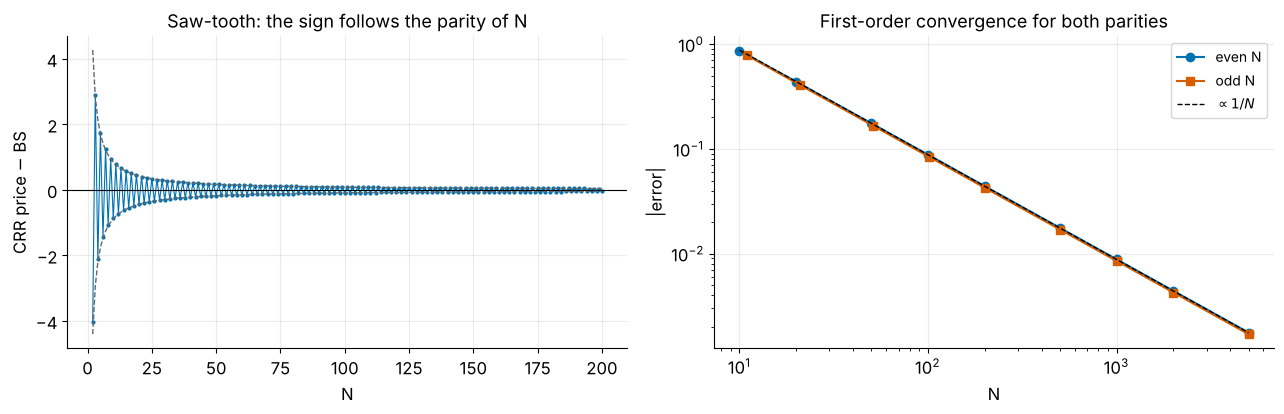

In [16]:
# [EXT] the full headline table of the report: N = 5 ... 10,000 (class for N <= 1000, vectorised pricer beyond)
N_table = [5, 10, 25, 50, 100, 200, 500, 1000, 10_000]
binomial_option_prices = []
for N in N_table:
    if N <= 1000:
        model = CRRBinomialModel(initial_stock_value = S, strike_price = K, steps = N, days = 252)
        model.generate_stock_tree(); model.generate_option_tree(); binomial_option_prices.append([N, model.pricing()])
    else:
        binomial_option_prices.append([N, tree_price(S0, K, r, sigma, T, N)])
for N, bin_option_price in binomial_option_prices:
    print(f"N={N}, \t bin_option_price={bin_option_price:.4f}, \t abs_differ_with_BS={abs(bin_option_price - BS):.4f}")
write_table("binomial_convergence", [r"$N$", "CRR price", r"$|\mathrm{CRR}-\mathrm{BS}|$", r"$N\times|\mathrm{error}|$"],
            [[f"{N:,}", f"{c:.4f}", f"{abs(c-BS):.4f}", f"{N*abs(c-BS):.3f}"] for N, c in binomial_option_prices], "rccc")
macro("CRRtenk", f"{binomial_option_prices[-1][1]:.4f}"); macro("CRRtenkErr", f"{abs(binomial_option_prices[-1][1]-BS):.4f}")
macro("CRRhundredErr", f"{abs(dict(binomial_option_prices)[100]-BS):.4f}"); macro("CRRthousandErr", f"{abs(dict(binomial_option_prices)[1000]-BS):.4f}")

# saw-tooth: signed error for every N, and the error constant for even/odd N
Nall = np.arange(2, 201); err_all = np.array([tree_price(S0, K, r, sigma, T, int(N)) - BS for N in Nall])
Ns_big = np.array([10, 20, 50, 100, 200, 500, 1000, 2000, 5000]); Nodd = Ns_big + 1
err_even = np.array([tree_price(S0, K, r, sigma, T, int(N)) - BS for N in Ns_big])
err_odd = np.array([tree_price(S0, K, r, sigma, T, int(N)) - BS for N in Nodd])
c_even = float(np.mean(err_even * Ns_big)); c_odd = float(np.mean(err_odd * Nodd))
print(f"error constant: even N  N*err ~ {c_even:.3f},  odd N  N*err ~ {c_odd:.3f}")
macro("SawEven", f"{c_even:.2f}"); macro("SawOdd", f"{c_odd:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(Nall, err_all, ".-", lw=0.8, ms=4); axes[0].axhline(0, color="k", lw=0.8)
axes[0].plot(Nall, c_even / Nall, "--", color="0.4", lw=1); axes[0].plot(Nall, c_odd / Nall, "--", color="0.4", lw=1)
axes[0].set(xlabel="N", ylabel="CRR price $-$ BS", title="Saw-tooth: the sign follows the parity of N")
axes[1].loglog(Ns_big, np.abs(err_even), "o-", label="even N"); axes[1].loglog(Nodd, np.abs(err_odd), "s-", label="odd N")
axes[1].loglog(Ns_big, 1 / Ns_big * abs(c_even), "k--", lw=1, label=r"$\propto 1/N$"); axes[1].legend()
axes[1].set(xlabel="N", ylabel="|error|", title="First-order convergence for both parities")
fig.tight_layout(); save_fig(fig, "crr_sawtooth")

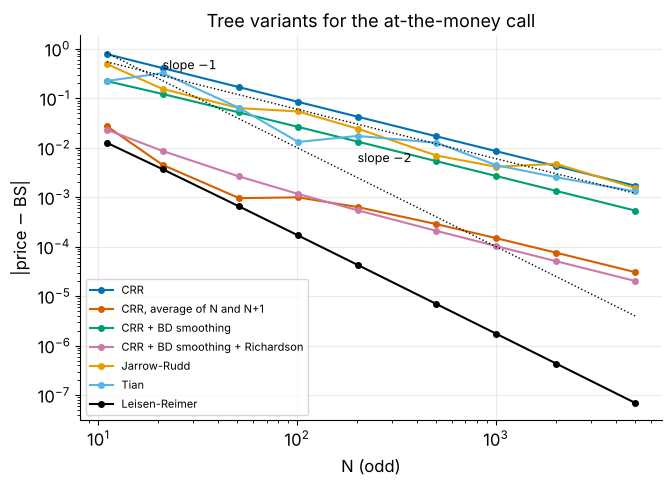

CRR                                 7.82e-01  4.08e-01  1.68e-01  8.45e-02  4.24e-02  1.70e-02  8.52e-03  4.26e-03  1.70e-03
CRR, average of N and N+1           2.74e-02  4.51e-03  9.57e-04  9.95e-04  6.32e-04  2.86e-04  1.49e-04  7.57e-05  3.06e-05
CRR + BD smoothing                  2.23e-01  1.22e-01  5.17e-02  2.64e-02  1.33e-02  5.35e-03  2.68e-03  1.34e-03  5.37e-04
CRR + BD smoothing + Richardson     2.32e-02  8.61e-03  2.62e-03  1.16e-03  5.44e-04  2.09e-04  1.03e-04  5.10e-05  2.03e-05
Jarrow-Rudd                         4.93e-01  1.54e-01  6.33e-02  5.41e-02  2.43e-02  6.96e-03  4.13e-03  4.73e-03  1.54e-03
Tian                                2.24e-01  3.22e-01  6.39e-02  1.31e-02  1.73e-02  1.26e-02  4.44e-03  2.54e-03  1.31e-03
Leisen-Reimer                       1.26e-02  3.68e-03  6.51e-04  1.68e-04  4.29e-05  6.93e-06  1.74e-06  4.35e-07  6.96e-08


In [17]:
# [EXT] comparison of tree variants: error vs N (odd N, so that Leisen-Reimer is admissible)
N_cmp = [11, 21, 51, 101, 201, 501, 1001, 2001, 5001]
variants = {
    "CRR": lambda N: tree_price(S0, K, r, sigma, T, N),
    "CRR, average of N and N+1": lambda N: 0.5 * (tree_price(S0, K, r, sigma, T, N) + tree_price(S0, K, r, sigma, T, N + 1)),
    "CRR + BD smoothing": lambda N: tree_price(S0, K, r, sigma, T, N, smooth=True),
    "CRR + BD smoothing + Richardson": lambda N: 2 * tree_price(S0, K, r, sigma, T, 2 * N, smooth=True) - tree_price(S0, K, r, sigma, T, N, smooth=True),
    "Jarrow-Rudd": lambda N: tree_price(S0, K, r, sigma, T, N, method="jr"),
    "Tian": lambda N: tree_price(S0, K, r, sigma, T, N, method="tian"),
    "Leisen-Reimer": lambda N: tree_price(S0, K, r, sigma, T, N, method="lr"),
}
var_err = {k: np.array([abs(f(N) - BS) for N in N_cmp]) for k, f in variants.items()}
fig, ax = plt.subplots(figsize=(7.5, 5))
for (k, e), c in zip(var_err.items(), PALETTE + ["#999999"]):
    ax.loglog(N_cmp, np.maximum(e, 1e-12), "o-", ms=4, color=c, label=k)
ax.loglog(N_cmp, 6 / np.array(N_cmp), "k:", lw=1); ax.loglog(N_cmp, 100 / np.array(N_cmp) ** 2, "k:", lw=1)
ax.text(N_cmp[1], 6 / N_cmp[1] * 1.3, "slope $-1$", fontsize=9); ax.text(N_cmp[4], 100 / N_cmp[4]**2 * 2, "slope $-2$", fontsize=9)
ax.set(xlabel="N (odd)", ylabel="|price $-$ BS|", title="Tree variants for the at-the-money call"); ax.legend(fontsize=8)
save_fig(fig, "tree_variants")
rows = [[k] + [f"{e[i]:.1e}" for i in (1, 3, 5, 7)] for k, e in var_err.items()]
write_table("tree_variants", ["Tree / acceleration"] + [f"$N={N_cmp[i]}$" for i in (1, 3, 5, 7)], rows, "lcccc")
macro("LRerrHundred", f"{var_err['Leisen-Reimer'][3]:.1e}"); macro("CRRerrHundredOdd", f"{var_err['CRR'][3]:.1e}")
macro("LRerrThousand", f"{var_err['Leisen-Reimer'][6]:.1e}")
for k, e in var_err.items(): print(f"{k:34s}", " ".join(f"{x:9.2e}" for x in e))

## II.6 [EXT] Monte Carlo pricing: the original experiment, then variance reduction
Under $\mathbb Q$ the call is $e^{-rT}\mathbb E[(S_T-K)^+]$, estimated by $\hat C=\frac{e^{-rT}}{M}\sum_i(S_T^{(i)}-K)^+$ with standard error $\mathrm{s.e.}=e^{-rT}\,\mathrm{sd}((S_T-K)^+)/\sqrt M$ and 95\% interval $\hat C\pm1.96\,\mathrm{s.e.}$ The error of the Euler scheme has two parts, a statistical part $O(M^{-1/2})$ and a discretisation bias $O(N^{-1})$ (weak order one). The hand-written `gbm_euler_maruyama` stores the whole path matrix, which for $5\cdot10^5$ paths and $300$ steps is more than a gigabyte, so for the price table we use a terminal-value-only version (same recursion, $O(M)$ memory).

In [18]:
# [EXT] Euler-Maruyama terminal values only (same recursion as gbm_euler_maruyama, O(M) memory)
def gbm_euler_terminal(S0, mu, sigma, T, N, M, rng, Z=None):
    # Z (M x N) may be supplied so that the noise is identical to a run of gbm_euler_maruyama
    dt = T / N; S = np.full(M, S0, dtype=float)
    for n in range(N):
        S += mu * S * dt + sigma * S * math.sqrt(dt) * (rng.standard_normal(M) if Z is None else Z[:, n])
    return S

# the hand-written function and the terminal-only version agree when they see the same noise
t_chk, P_chk = gbm_euler_maruyama(S0, r, sigma, T, 100, 5000, seed=7)
Z_chk = np.random.default_rng(7).standard_normal((5000, 100))          # the same matrix that gbm_euler_maruyama draws for seed 7
ST_chk = gbm_euler_terminal(S0, r, sigma, T, 100, 5000, None, Z=Z_chk)
print("max |difference| between the two Euler implementations:", float(np.abs(P_chk[:, -1] - ST_chk).max()))

steps_list = [100, 200, 300]; paths_list = [1000, 10_000, 100_000, 250_000, 500_000]
rows, mc_tab = [], {}
for si, steps in enumerate(steps_list):
    for pi, n_path in enumerate(paths_list):
        ST = gbm_euler_terminal(S0, r, sigma, T, steps, n_path, rng_for(100 + 10 * si + pi))
        disc_pay = math.exp(-r * T) * np.maximum(ST - K, 0); est, se = disc_pay.mean(), disc_pay.std(ddof=1) / math.sqrt(n_path)
        mc_tab[(steps, n_path)] = (est, se)
for n_path in paths_list:
    rows.append([f"{n_path:,}"] + [f"{mc_tab[(s, n_path)][0]:.4f} ({mc_tab[(s, n_path)][1]:.3f})" for s in steps_list])
    print(n_path, [f"{mc_tab[(s, n_path)][0]:.4f} (se {mc_tab[(s, n_path)][1]:.3f}, err {mc_tab[(s, n_path)][0]-BS:+.4f})" for s in steps_list])
write_table("mc_euler_table", ["Paths"] + [f"$N={s}$" for s in steps_list], rows, "rccc")
best = mc_tab[(300, 500_000)]
macro("MCbest", f"{best[0]:.4f}"); macro("MCbestSE", f"{best[1]:.3f}"); macro("MCbestErr", f"{abs(best[0]-BS):.4f}")

max |difference| between the two Euler implementations: 1.5916157281026244e-12


1000 ['41.4717 (se 2.325, err +2.7224)', '38.7524 (se 2.097, err +0.0031)', '41.2796 (se 2.218, err +2.5303)']
10000 ['38.5516 (se 0.681, err -0.1977)', '39.3903 (se 0.695, err +0.6410)', '39.8024 (se 0.698, err +1.0531)']
100000 ['38.8126 (se 0.215, err +0.0634)', '38.6919 (se 0.216, err -0.0573)', '38.7307 (se 0.216, err -0.0186)']
250000 ['38.8783 (se 0.136, err +0.1290)', '38.9348 (se 0.137, err +0.1855)', '38.6022 (se 0.136, err -0.1471)']
500000 ['38.7540 (se 0.096, err +0.0047)', '38.7559 (se 0.096, err +0.0066)', '38.7236 (se 0.096, err -0.0257)']


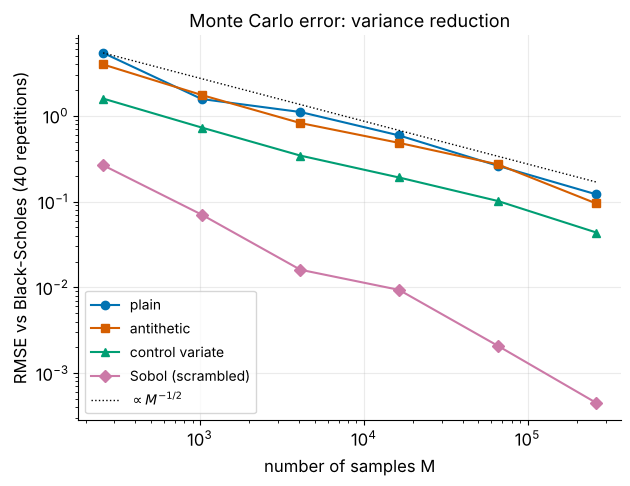

['plain', '38.7455', '0.1228', '0.1213', '1.0']
['antithetic', '38.7763', '0.0921', '0.0949', '1.8']
['control variate', '38.7491', '0.0441', '0.0436', '7.7']
['Sobol (scrambled)', '38.7494', '0.0004', '0.0005', '76726.6']
coverage of the 95% interval over 400 runs of M = 10^4: 0.953


pitfall: simulating with drift mu = 10% instead of r gives 49.96 instead of 38.75


In [19]:
# [EXT] 1 / sqrt(M) law, antithetic variates, control variate and scrambled Sobol (quasi-Monte Carlo); all with the exact terminal sampler
def terminal_exact(Z, S0=S0, r=r, sigma=sigma, T=T):
    return S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * math.sqrt(T) * Z)

def mc_estimators(M, rng, K=K):
    # returns {method: (estimate, standard error)} for the discounted call payoff, sampling cost M payoffs (antithetic: M/2 pairs)
    e = math.exp(-r * T); out = {}
    Z = rng.standard_normal(M); Y = e * np.maximum(terminal_exact(Z) - K, 0)
    out["plain"] = (Y.mean(), Y.std(ddof=1) / math.sqrt(M))
    Zh = Z[: M // 2]; Ya = 0.5 * (e * np.maximum(terminal_exact(Zh) - K, 0) + e * np.maximum(terminal_exact(-Zh) - K, 0))
    out["antithetic"] = (Ya.mean(), Ya.std(ddof=1) / math.sqrt(M // 2))
    X = e * terminal_exact(Z); b = np.cov(Y, X)[0, 1] / X.var(ddof=1)            # control variate: discounted S_T, E = S0
    Yc = Y - b * (X - S0); out["control variate"] = (Yc.mean(), Yc.std(ddof=1) / math.sqrt(M))
    return out

R_rep = 40; Ms = [2**k for k in range(8, 19, 2)]
res = {}
for M in Ms:
    est = {k: [] for k in ["plain", "antithetic", "control variate", "Sobol (scrambled)"]}; ses = {k: [] for k in est}
    for i in range(R_rep):
        o = mc_estimators(M, rng_for(200 + i + 100 * int(math.log2(M))))
        for k, (a, s) in o.items(): est[k].append(a); ses[k].append(s)
        sob = qmc.Sobol(d=1, scramble=True, seed=int(rng_for(900 + i).integers(1 << 30))).random_base2(int(math.log2(M)))
        est["Sobol (scrambled)"].append((math.exp(-r * T) * np.maximum(terminal_exact(norm.ppf(sob[:, 0])) - K, 0)).mean())
    res[M] = {k: (np.mean(v), np.std(v, ddof=1), np.sqrt(np.mean((np.array(v) - BS) ** 2))) for k, v in est.items()}
    res[M]["mean_se"] = {k: np.mean(v) for k, v in ses.items() if len(v)}
vr_res = res; vr_Ms = list(Ms)             # kept under their own names: later cells reuse the short names
fig, ax = plt.subplots(figsize=(7, 5))
for k, mk in zip(["plain", "antithetic", "control variate", "Sobol (scrambled)"], ["o", "s", "^", "D"]):
    ax.loglog(Ms, [res[M][k][2] for M in Ms], mk + "-", label=k)
ax.loglog(Ms, [res[Ms[0]]["plain"][2] * math.sqrt(Ms[0] / M) for M in Ms], "k:", lw=1, label=r"$\propto M^{-1/2}$")
ax.set(xlabel="number of samples M", ylabel=f"RMSE vs Black-Scholes ({R_rep} repetitions)", title="Monte Carlo error: variance reduction")
ax.legend(); save_fig(fig, "mc_variance_reduction")
Mref = Ms[-1]
rows = [[k, f"{res[Mref][k][0]:.4f}", f"{res[Mref][k][1]:.4f}", f"{res[Mref][k][2]:.4f}", f"{(res[Mref]['plain'][1]/res[Mref][k][1])**2:.1f}"]
        for k in ["plain", "antithetic", "control variate", "Sobol (scrambled)"]]
write_table("mc_variance_reduction", ["Method", "mean estimate", "sd of estimates", "RMSE", "variance ratio vs plain"], rows, "lcccc")
for r_ in rows: print(r_)
vr = {k: (res[Mref]['plain'][1] / res[Mref][k][1]) ** 2 for k in ["antithetic", "control variate", "Sobol (scrambled)"]}
macro("VRanti", f"{vr['antithetic']:.1f}"); macro("VRcv", f"{vr['control variate']:.1f}"); macro("VRsobol", f"{vr['Sobol (scrambled)']:.0f}"); macro("VRM", f"{Mref:,}".replace(",", r"\,"))

# coverage of the 95% confidence interval (should be about 95%) and the effect of using mu instead of r (a classical error)
cov = 0; Rc = 400
for i in range(Rc):
    est, se = mc_estimators(10_000, rng_for(5000 + i))["plain"]; cov += (est - 1.96 * se <= BS <= est + 1.96 * se)
print(f"coverage of the 95% interval over {Rc} runs of M = 10^4: {cov/Rc:.3f}")
macro("MCcoverage", f"{100*cov/Rc:.1f}")
ST_P = terminal_exact(rng_for(77).standard_normal(1_000_000), r=0.10 )   # simulating with drift mu = 10% instead of r
wrong = math.exp(-r * T) * np.maximum(ST_P - K, 0).mean()
print(f"pitfall: simulating with drift mu = 10% instead of r gives {wrong:.2f} instead of {BS:.2f}")
macro("WrongMuPrice", f"{wrong:.2f}")

strong slope -0.49, weak slope -0.96 ; weak bias at N=256: +0.0066 (s.e. 0.0022)


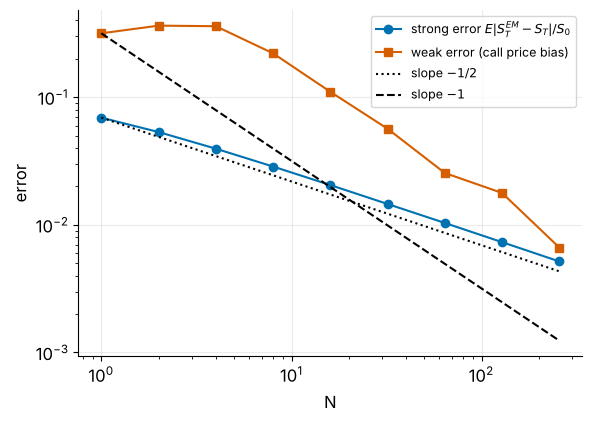

In [20]:
# [EXT] Euler-Maruyama error: strong order 1/2 and weak order 1, with common random numbers (exact solution driven by the same noise)
def euler_and_exact_terminal(S0, mu, sigma, T, N, M, rng):
    dt = T / N; Sx = np.full(M, float(S0)); sumZ = np.zeros(M)
    for _ in range(N):
        Z = rng.standard_normal(M); sumZ += Z; Sx *= 1.0 + mu * dt + sigma * math.sqrt(dt) * Z
    return Sx, S0 * np.exp((mu - 0.5 * sigma**2) * T + sigma * math.sqrt(dt) * sumZ)

M_err = 400_000; N_em = [1, 2, 4, 8, 16, 32, 64, 128, 256]
strong, weak, weak_se = [], [], []
for i, N in enumerate(N_em):
    Se, Sx = euler_and_exact_terminal(S0, r, sigma, T, N, M_err, rng_for(60 + i))
    strong.append(np.abs(Se - Sx).mean() / S0)
    dif = math.exp(-r * T) * (np.maximum(Se - K, 0) - np.maximum(Sx - K, 0)); weak.append(dif.mean()); weak_se.append(dif.std(ddof=1) / math.sqrt(M_err))
write_table("em_error", [r"$N$", r"$\mathbb E|S_T^{\rm EM}-S_T|/S_0$", "price bias", "(s.e.)"],
            [[str(N), f"{a:.4f}", f"{b:+.4f}", f"({c:.4f})"] for N, a, b, c in zip(N_em, strong, weak, weak_se)], "rccc")
slope_strong = np.polyfit(np.log(N_em[2:]), np.log(strong[2:]), 1)[0]; slope_weak = np.polyfit(np.log(N_em[2:7]), np.log(np.abs(weak[2:7])), 1)[0]      # N = 4..64: asymptotic range, above the Monte Carlo noise floor
print(f"strong slope {slope_strong:.2f}, weak slope {slope_weak:.2f} ; weak bias at N=256: {weak[-1]:+.4f} (s.e. {weak_se[-1]:.4f})")
macro("EMstrongSlope", f"{slope_strong:.2f}"); macro("EMweakSlope", f"{slope_weak:.2f}")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.loglog(N_em, strong, "o-", label=r"strong error $E|S^{EM}_T-S_T|/S_0$"); ax.loglog(N_em, np.abs(weak), "s-", label="weak error (call price bias)")
ax.loglog(N_em, strong[0] * np.array(N_em, float) ** -0.5, "k:", label="slope $-1/2$"); ax.loglog(N_em, abs(weak[0]) * np.array(N_em, float) ** -1.0, "k--", label="slope $-1$")
ax.set(xlabel="N", ylabel="error"); ax.legend(fontsize=9); save_fig(fig, "em_order")

## II.7 [EXT] Greeks by three routes: closed form, tree, Monte Carlo
Prices are rarely the end product: a desk needs sensitivities. We compute $\Delta,\Gamma,\mathcal V,\Theta,\rho$ three ways. **Tree:** $\Delta=\frac{V_u-V_d}{S_u-S_d}$ from the first layer and $\Gamma=\frac{\Delta_{up}-\Delta_{down}}{(S_{uu}-S_{dd})/2}$ from the second layer, $\Theta=\frac{V_{ud}-V_0}{2\Delta t}$ (since $S_{ud}=S_0$ in the CRR tree), $\mathcal V$ and $\rho$ by central bumps with the same $N$. **Monte Carlo:** (i) *pathwise* (differentiate the payoff, valid for $\Delta$ and $\mathcal V$ because the payoff is Lipschitz), $\Delta=e^{-rT}\mathbf 1_{S_T>K}S_T/S_0$, $\mathcal V=e^{-rT}\mathbf 1_{S_T>K}S_T(\sqrt TZ-\sigma T)$; (ii) *likelihood ratio* (differentiate the density, needed for $\Gamma$ because the payoff's second derivative is a delta function), $\Gamma=e^{-rT}\mathbf 1_{S_T>K}\frac{S_T}{S_0^2}\big(\frac{Z}{\sigma\sqrt T}-1\big)$ (pathwise times LR); (iii) *bump and revalue* with common random numbers, $\frac{C(S_0+h)-C(S_0-h)}{2h}$.

In [21]:
# [EXT] Greeks from the tree (CRR, N steps; bumps for vega and rho)
def tree_greeks(S0, K, r, sigma, T, N, kind="call", american=False, q=0.0, method="crr"):
    V0, nd = tree_price(S0, K, r, sigma, T, N, kind, american, method, q, nodes=True)
    (S1, V1), (S2, V2) = nd[1], nd[2]; dt = T / N
    d_up = (V2[2] - V2[1]) / (S2[2] - S2[1]); d_dn = (V2[1] - V2[0]) / (S2[1] - S2[0])
    delta = (V1[1] - V1[0]) / (S1[1] - S1[0]); gamma = (d_up - d_dn) / (0.5 * (S2[2] - S2[0]))
    theta = (V2[1] - V0) / (2 * dt)
    hv, hr = 1e-4, 1e-5
    vega = (tree_price(S0, K, r, sigma + hv, T, N, kind, american, method, q) - tree_price(S0, K, r, sigma - hv, T, N, kind, american, method, q)) / (2 * hv)
    rho = (tree_price(S0, K, r + hr, sigma, T, N, kind, american, method, q) - tree_price(S0, K, r - hr, sigma, T, N, kind, american, method, q)) / (2 * hr)
    return dict(price=V0, delta=delta, gamma=gamma, vega=vega, theta=theta, rho=rho)

def mc_greeks(S0, K, r, sigma, T, M, rng):
    Z = rng.standard_normal(M); ST = terminal_exact(Z, S0, r, sigma, T); e = math.exp(-r * T); ind = ST > K; out = {}
    se = lambda y: (y.mean(), y.std(ddof=1) / math.sqrt(M))
    out["delta pathwise"] = se(e * ind * ST / S0)
    out["delta LR"] = se(e * np.maximum(ST - K, 0) * Z / (S0 * sigma * math.sqrt(T)))
    h = 0.01 * S0; up = e * np.maximum(terminal_exact(Z, S0 + h, r, sigma, T) - K, 0); dn = e * np.maximum(terminal_exact(Z, S0 - h, r, sigma, T) - K, 0)
    out["delta bump (CRN)"] = se((up - dn) / (2 * h))
    out["gamma LR x pathwise"] = se(e * ind * ST / S0**2 * (Z / (sigma * math.sqrt(T)) - 1))
    out["gamma bump (CRN)"] = se((up - 2 * e * np.maximum(ST - K, 0) + dn) / h**2)
    out["vega pathwise"] = se(e * ind * ST * (math.sqrt(T) * Z - sigma * T))
    out["vega LR"] = se(e * np.maximum(ST - K, 0) * ((Z**2 - 1) / sigma - math.sqrt(T) * Z))
    return out

tg = tree_greeks(S0, K, r, sigma, T, 1000)
mg = mc_greeks(S0, K, r, sigma, T, 1_000_000, rng_for(300))
rows = []
for name, bs_val, tr_val, keys in [("$\\Delta$", G["delta"], tg["delta"], ["delta pathwise", "delta LR", "delta bump (CRN)"]),
                                   ("$\\Gamma$", G["gamma"], tg["gamma"], ["gamma LR x pathwise", "gamma bump (CRN)"]),
                                   ("vega", G["vega"], tg["vega"], ["vega pathwise", "vega LR"])]:
    for k in keys:
        est, se_ = mg[k]; rows.append([name, f"{bs_val:.5f}", f"{tr_val:.5f}", k.split(" ", 1)[1] if " " in k else k, f"{est:.5f}", f"{se_:.5f}"])
        print(name, k, f"BS {bs_val:.5f}  tree {tr_val:.5f}  MC {est:.5f} +- {se_:.5f}")
rows.append([r"$\Theta$ (per year)", f"{G['theta']:.4f}", f"{tg['theta']:.4f}", "--", "--", "--"])
rows.append([r"$\rho$", f"{G['rho']:.3f}", f"{tg['rho']:.3f}", "--", "--", "--"])
write_table("greeks_three_routes", ["Greek", "Black-Scholes", "Tree ($N=1000$)", "MC estimator", "MC value", "s.e."], rows, "lccccc")
macro("TreeDelta", f"{tg['delta']:.4f}"); macro("TreeGamma", f"{tg['gamma']:.5f}"); macro("TreeVega", f"{tg['vega']:.2f}")
macro("MCdeltaPW", f"{mg['delta pathwise'][0]:.4f}"); macro("MCgammaLR", f"{mg['gamma LR x pathwise'][0]:.5f}")
macro("MCgammaBumpSE", f"{mg['gamma bump (CRN)'][1]:.5f}"); macro("MCgammaLRSE", f"{mg['gamma LR x pathwise'][1]:.5f}")

$\Delta$ delta pathwise BS 0.60469  tree 0.60466  MC 0.60476 +- 0.00070
$\Delta$ delta LR BS 0.60469  tree 0.60466  MC 0.60653 +- 0.00163
$\Delta$ delta bump (CRN) BS 0.60469  tree 0.60466  MC 0.60474 +- 0.00070
$\Gamma$ gamma LR x pathwise BS 0.00427  tree 0.00428  MC 0.00428 +- 0.00001
$\Gamma$ gamma bump (CRN) BS 0.00427  tree 0.00428  MC 0.00424 +- 0.00003
vega vega pathwise BS 92.00674  tree 91.98375  MC 92.22585 +- 0.22333
vega vega LR BS 92.00674  tree 91.98375  MC 93.04232 +- 0.72616


## II.8 [EXT] Implied volatility: reading a price as a volatility
Traders quote options in implied volatility because it is comparable across strikes and maturities. Given an observed price, $\hat\sigma$ solves $C_{BS}(\hat\sigma)=C_{obs}$; the root is unique because $\partial C/\partial\sigma=\mathcal V>0$. Two diagnostics for the numerical methods of this report: (i) the implied volatility of a tree price with $N$ steps measures the *model error in volatility points*, and (ii) the standard error of a Monte Carlo price converts to a volatility error through vega, $\mathrm{s.e.}_{\hat\sigma}\approx\mathrm{s.e.}_C/\mathcal V$.

10 37.87846208474339 0.36779291961751787
25 39.09175229805218 0.38097697106299633
50 38.573083357658376 0.37533927379255533
100 38.66105934744151 0.376295356829432
250 38.7139553691268 0.3768702411615338
1000 38.74043373695299 0.37715802299355755
10000 38.74838114592173 0.37724440118553115


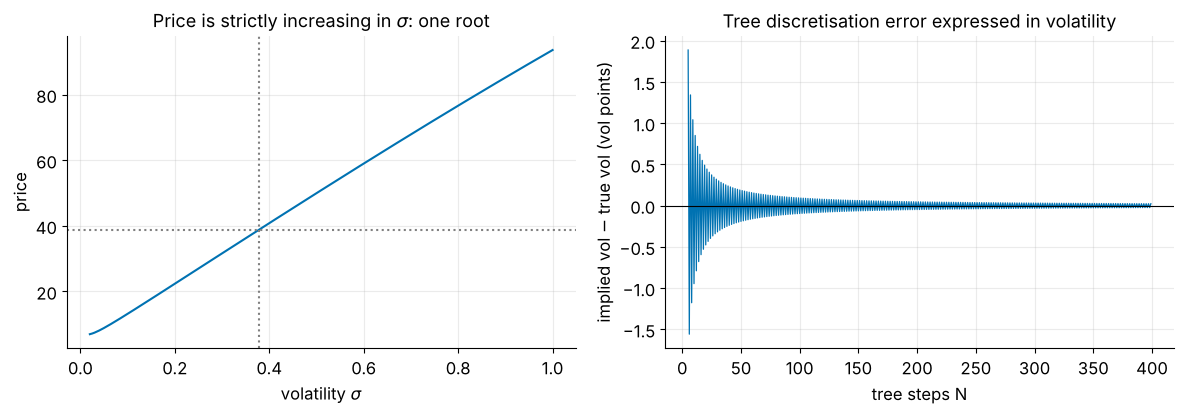

In [22]:
# [EXT] implied volatility of the numerical prices, and of the American put against the European one (see Part III for the American side)
iv_rows = []
for N in [10, 25, 50, 100, 250, 1000, 10_000]:
    c = tree_price(S0, K, r, sigma, T, N); iv = implied_vol(c, S0, K, r, T)
    iv_rows.append([f"{N:,}", f"{c:.4f}", f"{100*iv:.3f}", f"{100*(iv-sigma):+.3f}"])
    print(N, c, iv)
est, se_ = mc_exact_best = (mc_tab[(300, 500_000)][0], mc_tab[(300, 500_000)][1])
iv_mc = implied_vol(est, S0, K, r, T); iv_lo = implied_vol(est - 1.96 * se_, S0, K, r, T); iv_hi = implied_vol(est + 1.96 * se_, S0, K, r, T)
iv_rows.append(["MC $5\\cdot10^5$ (Euler, $N=300$)", f"{est:.4f}", f"{100*iv_mc:.3f}", f"{100*(iv_mc-sigma):+.3f}"])
write_table("implied_vol_numerics", ["Method / $N$", "price", r"implied vol (\%)", r"error (vol points)"], iv_rows, "lccc")
macro("IVmcLo", f"{100*iv_lo:.2f}"); macro("IVmcHi", f"{100*iv_hi:.2f}"); macro("IVcrrHundred", f"{100*(implied_vol(tree_price(S0,K,r,sigma,T,100),S0,K,r,T)-sigma):+.2f}")

sg = np.linspace(0.02, 1.0, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(sg, bs_price(S0, K, r, sg, T), label="Black-Scholes call")
axes[0].axhline(BS, color="0.5", ls=":"); axes[0].axvline(sigma, color="0.5", ls=":"); axes[0].set(xlabel=r"volatility $\sigma$", ylabel="price", title="Price is strictly increasing in $\\sigma$: one root")
Nv = np.arange(5, 400, 1); ivs = np.array([implied_vol(tree_price(S0, K, r, sigma, T, int(N)), S0, K, r, T) for N in Nv])
axes[1].plot(Nv, 100 * (ivs - sigma), lw=0.9); axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="tree steps N", ylabel="implied vol $-$ true vol (vol points)", title="Tree discretisation error expressed in volatility")
fig.tight_layout(); save_fig(fig, "implied_vol")

## II.9 [EXT] Delta hedging a short call in discrete time
Black-Scholes pricing is also a hedging argument. A seller who receives $C_0$ for the call and holds $\Delta_k=\Phi(d_1(S_{t_k},T-t_k))$ shares at the dates $t_k=kT/n$, financing at rate $r$, ends with the discounted profit
$$\varepsilon=C_0+\sum_{k=0}^{n-1}\Delta_k\big(e^{-rt_{k+1}}S_{t_{k+1}}-e^{-rt_k}S_{t_k}\big)-e^{-rT}(S_T-K)^+ .$$
It is zero in continuous time. With $n$ rebalances its standard deviation decays like $n^{-1/2}$ (a sum of $n$ gamma-weighted squared-return surprises of size $1/n$). If the stock actually has volatility $\sigma_{real}$ and the hedge uses $\sigma_{h}$, then to leading order $\varepsilon\approx\int_0^Te^{-rt}\tfrac12\Gamma_tS_t^2(\sigma_h^2-\sigma_{real}^2)\,dt$: the seller loses when realised variance exceeds the variance used to price and hedge, and the loss is largest at the money near maturity where $\Gamma$ is large. This is the continuous-time analogue of the mis-specified volatility experiment of Part III.

n=  4: sd(error) Q 14.187  P(mu=0.1) 14.692   mean Q -0.0987   as % of premium 36.6%
n=  8: sd(error) Q 10.302  P(mu=0.1) 10.521   mean Q +0.0732   as % of premium 26.6%
n= 16: sd(error) Q 7.391  P(mu=0.1) 7.303   mean Q +0.0272   as % of premium 19.1%
n= 32: sd(error) Q 5.286  P(mu=0.1) 5.270   mean Q +0.0403   as % of premium 13.6%


n= 52: sd(error) Q 4.152  P(mu=0.1) 4.194   mean Q -0.0612   as % of premium 10.7%


n= 64: sd(error) Q 3.778  P(mu=0.1) 3.750   mean Q +0.0218   as % of premium 9.7%


n=126: sd(error) Q 2.653  P(mu=0.1) 2.711   mean Q +0.0280   as % of premium 6.8%


n=252: sd(error) Q 1.908  P(mu=0.1) 1.925   mean Q -0.0043   as % of premium 4.9%
slope of log sd vs log n: -0.48631674227206395


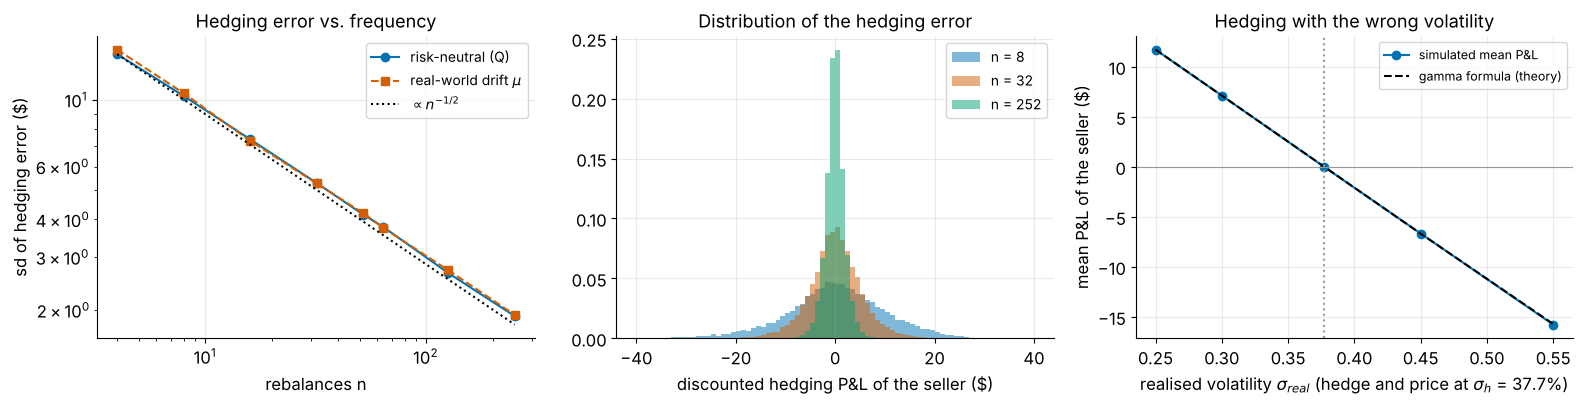

sigma_real=0.250: mean +11.704  theory +11.714
sigma_real=0.300: mean +7.109  theory +7.116
sigma_real=0.377: mean -0.013  theory +0.000
sigma_real=0.450: mean -6.672  theory -6.685
sigma_real=0.550: mean -15.781  theory -15.716


In [23]:
# [EXT] hedging experiment (exact GBM paths, BS delta at the hedging volatility)
def hedge_experiment(S0, K, r, sig_real, sig_hedge, T, n, M, rng, drift=None):
    drift = r if drift is None else drift; dt = T / n
    Z = rng.standard_normal((M, n)); logS = np.cumsum((drift - 0.5 * sig_real**2) * dt + sig_real * math.sqrt(dt) * Z, axis=1)
    Sp = S0 * np.concatenate([np.ones((M, 1)), np.exp(logS)], axis=1)
    tk = np.arange(n + 1) * dt; D = np.exp(-r * tk)
    tau = T - tk[:-1]; d1 = (np.log(Sp[:, :-1] / K) + (r + 0.5 * sig_hedge**2) * tau) / (sig_hedge * np.sqrt(tau))
    delta = norm.cdf(d1); gains = (delta * (D[1:] * Sp[:, 1:] - D[:-1] * Sp[:, :-1])).sum(axis=1)
    C0 = float(bs_price(S0, K, r, sig_hedge, T)); eps = C0 + gains - D[-1] * np.maximum(Sp[:, -1] - K, 0)
    gamma_term = (D[:-1] * norm.pdf(d1) / (sig_hedge * np.sqrt(tau)) * Sp[:, :-1]).sum(axis=1) * dt   # integral of D * Gamma * S^2 dt, for the theory line
    return eps, 0.5 * (sig_hedge**2 - sig_real**2) * gamma_term

M_h = 20_000; ns = [4, 8, 16, 32, 52, 64, 126, 252]
sd_q, sd_p, mean_q = [], [], []
for i, n in enumerate(ns):
    e_q, _ = hedge_experiment(S0, K, r, sigma, sigma, T, n, M_h, rng_for(400 + i)); e_p, _ = hedge_experiment(S0, K, r, sigma, sigma, T, n, M_h, rng_for(450 + i), drift=mu)
    sd_q.append(e_q.std()); sd_p.append(e_p.std()); mean_q.append(e_q.mean())
    print(f"n={n:>3}: sd(error) Q {e_q.std():.3f}  P(mu={mu}) {e_p.std():.3f}   mean Q {e_q.mean():+.4f}   as % of premium {100*e_q.std()/BS:.1f}%")
slope_h = np.polyfit(np.log(ns), np.log(sd_q), 1)[0]; print("slope of log sd vs log n:", slope_h)
write_table("hedging_frequency", ["rebalances $n$", "sd of hedging error (\\$)", "as \\% of premium", "mean error (\\$)", "sd under real-world drift"],
            [[str(n), f"{a:.3f}", f"{100*a/BS:.1f}", f"{m_:+.3f}", f"{b:.3f}"] for n, a, m_, b in zip(ns, sd_q, mean_q, sd_p)], "rcccc")
sdq = dict(zip(ns, sd_q))
macro("HedgeSlope", f"{slope_h:.2f}"); macro("HedgeSDdaily", f"{sdq[252]:.2f}"); macro("HedgeSDdailyPct", f"{100*sdq[252]/BS:.1f}")
macro("HedgeSDweekly", f"{sdq[52]:.2f}"); macro("HedgeSDweeklyPct", f"{100*sdq[52]/BS:.1f}"); macro("HedgeSDfour", f"{sdq[4]:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].loglog(ns, sd_q, "o-", label="risk-neutral (Q)"); axes[0].loglog(ns, sd_p, "s--", label=r"real-world drift $\mu$")
axes[0].loglog(ns, sd_q[0] * np.sqrt(ns[0] / np.array(ns)), "k:", label=r"$\propto n^{-1/2}$"); axes[0].set(xlabel="rebalances n", ylabel="sd of hedging error ($)", title="Hedging error vs. frequency"); axes[0].legend()
for n, c in zip([8, 32, 252], PALETTE):
    e, _ = hedge_experiment(S0, K, r, sigma, sigma, T, n, M_h, rng_for(480 + n)); axes[1].hist(e, bins=80, range=(-40, 40), alpha=0.5, color=c, label=f"n = {n}", density=True)
axes[1].set(xlabel="discounted hedging P&L of the seller ($)", title="Distribution of the hedging error"); axes[1].legend()

sig_r_list = [0.25, 0.30, 0.377254, 0.45, 0.55]; mean_wrong, theory_wrong, sd_wrong = [], [], []
for i, sr in enumerate(sig_r_list):
    e, th = hedge_experiment(S0, K, r, sr, sigma, T, 252, 10_000, rng_for(500 + i)); mean_wrong.append(e.mean()); theory_wrong.append(th.mean()); sd_wrong.append(e.std())
axes[2].plot(sig_r_list, mean_wrong, "o-", label="simulated mean P&L"); axes[2].plot(sig_r_list, theory_wrong, "k--", label="gamma formula (theory)")
axes[2].axhline(0, color="0.6", lw=0.8); axes[2].axvline(sigma, color="0.6", ls=":")
axes[2].set(xlabel=r"realised volatility $\sigma_{real}$ (hedge and price at $\sigma_h$ = 37.7%)", ylabel="mean P&L of the seller ($)", title="Hedging with the wrong volatility"); axes[2].legend(fontsize=9)
fig.tight_layout(); save_fig(fig, "hedging_error")
write_table("hedging_wrong_vol", [r"realised $\sigma$", "simulated mean P\\&L", "gamma formula", "sd of P\\&L"],
            [[f"{100*s:.1f}\\%", f"{m_:+.3f}", f"{t_:+.3f}", f"{d_:.3f}"] for s, m_, t_, d_ in zip(sig_r_list, mean_wrong, theory_wrong, sd_wrong)], "rccc")
for s, m_, t_ in zip(sig_r_list, mean_wrong, theory_wrong): print(f"sigma_real={s:.3f}: mean {m_:+.3f}  theory {t_:+.3f}")
macro("WrongVolLoss", f"{mean_wrong[-1]:+.2f}"); macro("WrongVolTheory", f"{theory_wrong[-1]:+.2f}")

# Part III. American put: optimal stopping, variational PDE, CRR tree

**Baseline** (used throughout this part, unless stated): $S_0=K=10$, $\sigma=20\%$, $r=2\%$, $T=1$, real-world drift $\mu=5\%$. The value of an American put under $dS_t=rS_tdt+\sigma S_tdW_t$ (risk-neutral measure $\mathbb Q$) is the optimal stopping problem
$$V(t,x)=\sup_{\tau\in[t,T]}\mathbb E\big[e^{-r(\tau-t)}(K-S_\tau)^+\mid S_t=x\big].$$
Two immediate facts: $V\ge(K-x)^+$ (exercise now) and $V\ge V^{Eur}$ (the choice $\tau=T$). The state space splits into a continuation region $C=\{V>(K-x)^+\}$ and a stopping region $D=\{V=(K-x)^+\}=\{x\le b(t)\}$; the free boundary $b(t)$ is part of the unknown and the optimal rule is $\tau^*=\inf\{t:S_t\le b(t)\}$.

## III.1 Variational PDE and hedging
**Why a recursion.** At each date the holder compares exercising with waiting and being optimal afterwards. The discounted value $e^{-rt}V(t,S_t)$ is the smallest $\mathbb Q$-supermartingale dominating the discounted payoff (the Snell envelope); it is a martingale up to $\tau^*$.

**European warm-up (four steps).** Let $g(t,S_t)=e^{-rt}P(t,S_t)$ be a martingale. (1) Assume $g\in C^{1,2}$. (2) Take $\partial_t,\partial_x,\partial_{xx}$. (3) Apply It\^o's formula with $dS=rS\,dt+\sigma S\,dW$:
$$d\big(e^{-rt}P\big)=e^{-rt}\big(\underbrace{\partial_tP+rx\partial_xP+\tfrac12\sigma^2x^2\partial_{xx}P-rP}_{(\mathcal L-r)P}\big)dt+e^{-rt}\sigma x\,\partial_xP\,dW.$$
(4) A martingale has zero drift, so $(\mathcal L-r)P=0$, $P(T,x)=h(x)$: the Black-Scholes PDE.

**American case.** $e^{-rt}V$ is only a supermartingale, so the drift is $\le0$; it must dominate the obstacle; and in the continuation region the drift is exactly $0$:
$$(\mathcal L-r)V\le0,\qquad V\ge(K-x)^+,\qquad\big(V-(K-x)^+\big)(\mathcal L-r)V=0,\qquad V(T,x)=(K-x)^+ .$$
Equivalently $\min\{-(\mathcal L-r)V,\;V-(K-x)^+\}=0$ (a linear complementarity problem). In the stopping region $(\mathcal L-r)(K-x)=-rx-r(K-x)=-rK<0$: waiting loses money, which is why one exercises.

**Smooth fit.** On the free boundary $\partial_xV(t,b(t))=-1$. If $\partial_xV$ jumped, moving the boundary would improve the stopping rule. The tree never uses smooth fit explicitly: the $\max$ in the recursion solves the obstacle problem directly.

**Hedging.** The market is complete, so by FTAP II the claim exercised at $\tau^*$ is replicable: hold $\Delta_t=\partial_xV(t,S_t)$ shares and the rest in the bond. It is the European Delta-hedge formula with the American value function; $\Delta=-1$ in the stopping region. Replication is exact up to $\tau^*$; if the holder exercises suboptimally the seller keeps the surplus (super-replication).

In [24]:
# parameter block of Part III (the NVDA block of Part II is overwritten: run the parts in order)
S0, K, mu, vol, r, T = 10, 10, 0.05, 0.2, 0.02, 1
os.makedirs("figures", exist_ok=True); os.makedirs("figures/scenarios", exist_ok=True)

def plotsmart(x=None, ys=(), labels=None, xlabel="", ylabel="", title="", fname=None,
              xscale="linear", single_points=None, kind="line"):
    # To save space, this is an all-in-one helper for every figure, which is written after all the plotting commands are written (collecting all needs), and always saves to figures/<fname>.png.
    labels = labels or [None] * len(ys)
    if kind == "hist":                      # one histogram panel per dataset
        fig, axs = plt.subplots(1, len(ys), figsize=(5 * len(ys), 4))
        for ax, y, lab in zip(axs, ys, labels):
            y = np.asarray(y)
            if np.unique(y).size <= 2:      # 0/1 indicator (early exercise)
                ax.hist(y, bins=[-0.5, 0.5, 1.5], rwidth=0.6); ax.set_xticks([0, 1])
            else:
                ax.hist(y, bins=40)
            ax.set_xlabel(lab); ax.set_ylabel("count")
        fig.suptitle(title)
    else:
        fig, ax = plt.subplots(figsize=(7, 4.5))
        per_curve_x = isinstance(x, list) and len(x) > 0 and isinstance(x[0], np.ndarray)
        for k, (y, lab) in enumerate(zip(ys, labels)):
            ax.plot(x[k] if per_curve_x else x, y, label=lab)
        for (px, py, lab) in (single_points or []):
            ax.plot([px], [py], "k*", ms=12, label=lab)
        ax.set_xscale(xscale); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
        if any(labels) or single_points: ax.legend()
        ax.grid(alpha=0.3)
    fig.tight_layout()
    if fname: fig.savefig(f"figures/{fname}.png", dpi=200)
    plt.show()

## III.2 The perpetual put ($T=\infty$)
With $T=\infty$ nothing depends on $t$ and $b(t)\equiv S^*$. The system becomes the ODE $\tfrac12\sigma^2x^2V''+rxV'-rV=0$ for $x>S^*$, $V=K-x$ for $x\le S^*$, $V\ge(K-x)^+$, with $V$ and $V'$ continuous at $S^*$.

**Solution.** Try $V=Ax^{-\beta}$, $\beta>0$: $\tfrac12\sigma^2\beta(\beta+1)-r\beta-r=(\beta+1)(\tfrac12\sigma^2\beta-r)=0$, so $\beta=2r/\sigma^2$. With $\kappa=r/\sigma^2$: $\Delta=\sqrt{(\kappa-\frac12)^2+2\kappa}=\kappa+\frac12$ and $\beta=\kappa-\frac12+\Delta=2\kappa$. Matching value and slope at $S^*$ ($A(S^*)^{-\beta}=K-S^*$, $-\beta A(S^*)^{-\beta-1}=-1$):
$$S^*=\frac{\beta K}{\beta+1},\qquad V_\infty(x)=\frac{K}{\beta+1}\Big(\frac{S^*}{x}\Big)^{\beta}\ (x>S^*).$$
**Second derivation (no smooth fit).** Exercising at the first time the price falls to a threshold $b$ is worth $V_b(x)=(K-b)(b/x)^\beta$ because $\mathbb E[e^{-r\tau_b}]=(b/x)^\beta$. Maximising $(K-b)b^\beta$ over $b$ gives $b=\beta K/(\beta+1)=S^*$: smooth fit is the first-order condition of the stopping problem.

Baseline: $\kappa=0.5$, $\beta=1$, $S^*=5$, $V_\infty(10)=2.5$. A larger $r$ raises $\beta$ and moves $S^*/K=\beta/(\beta+1)$ towards 1 (exercise earlier: the strike earns interest); a larger $\sigma$ lowers both (waiting is worth more).

In [25]:
def perp_params(r, vol, K=K):
    kappa = r / vol**2
    Delta = math.sqrt((kappa - 1/2)**2 + 2*kappa)
    beta = (kappa - 1/2) + Delta          # = 2 r / vol^2
    return beta, K * beta / (beta + 1)    # beta, S*

def Vinf(x, r=r, vol=vol, K=K):
    beta, Sstar = perp_params(r, vol, K)
    x = np.asarray(x, float)
    return np.where(x <= Sstar, K - x, K / (beta + 1) * (Sstar / x) ** beta)

beta, Sstar = perp_params(r, vol)
print(f"beta = {beta:.4f}, S* = {Sstar:.4f}, Vinf(S0) = {float(Vinf(S0)):.4f}")

# (i) numerical verification of the variational ODE  min{ -(L V - rV), V-(K-x)^+ } = 0
x = np.linspace(Sstar, 30, 2001)[1:-1]; h = 1e-3
V = lambda z: Vinf(z)
V1 = (V(x + h) - V(x - h)) / (2 * h); V2 = (V(x + h) - 2 * V(x) + V(x - h)) / h**2
res_cont = 0.5 * vol**2 * x**2 * V2 + r * x * V1 - r * V(x)           # should be 0 for x > S*
xs = np.linspace(1, Sstar - 1e-3, 200)
res_exer = 0.5 * vol**2 * xs**2 * 0 + r * xs * (-1) - r * (K - xs)   # = -rK <= 0 for x < S*
print("max |ODE residual|, x>S*      :", np.abs(res_cont).max())
print("generator on x<S* (= -rK)     :", res_exer.min(), res_exer.max(), " (<=0)")
print("V - (K-x)^+ >= 0 on grid      :", (V(x) - np.maximum(K - x, 0)).min() >= -1e-12)
print("smooth fit V'(S*-), V'(S*+)   :", -1.0, float((V(Sstar + h) - V(Sstar)) / h))
print("value match at S*             :", float(V(Sstar)), K - Sstar)
macro("PerpBeta", f"{beta:.0f}"); macro("PerpSstar", f"{Sstar:.0f}"); macro("PerpV", f"{float(Vinf(S0)):.1f}"); macro("PerpResidual", f"{np.abs(res_cont).max():.0e}")

beta = 1.0000, S* = 5.0000, Vinf(S0) = 2.5000
max |ODE residual|, x>S*      : 8.029217180016701e-09
generator on x<S* (= -rK)     : -0.2 -0.19999999999999998  (<=0)
V - (K-x)^+ >= 0 on grid      : True
smooth fit V'(S*-), V'(S*+)   : -1.0 -0.9998000399917828
value match at S*             : 5.0 5.0


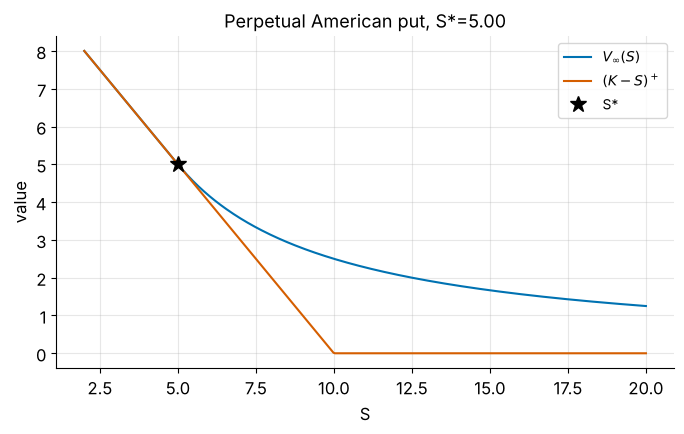

In [26]:
# (ii) V_inf and S* for baseline parameters
S = np.linspace(2, 20, 400)
plotsmart(S, [Vinf(S), np.maximum(K - S, 0)], labels=[r"$V_\infty(S)$", r"$(K-S)^+$"],
          xlabel="S", ylabel="value", title=f"Perpetual American put, S*={Sstar:.2f}",
          single_points=[(Sstar, float(Vinf(Sstar)), "S*")], fname="1c_Vinf")

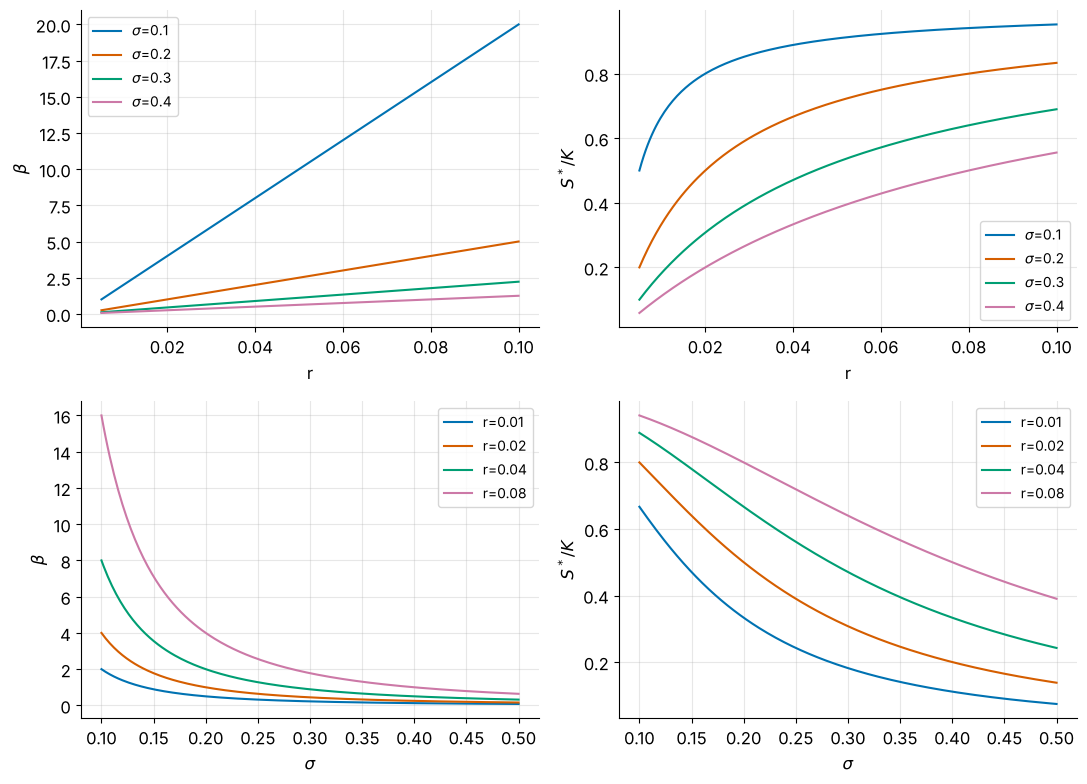

In [27]:
# (iii) dependence of beta and S*/K on r and sigma
r_grid = np.linspace(0.005, 0.10, 200); sig_grid = np.linspace(0.10, 0.50, 200)
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for sg in [0.1, 0.2, 0.3, 0.4]:
    b = np.array([perp_params(rr, sg)[0] for rr in r_grid])
    axs[0, 0].plot(r_grid, b, label=f"$\\sigma$={sg}"); axs[0, 1].plot(r_grid, b / (b + 1), label=f"$\\sigma$={sg}")
for rr in [0.01, 0.02, 0.04, 0.08]:
    b = np.array([perp_params(rr, sg)[0] for sg in sig_grid])
    axs[1, 0].plot(sig_grid, b, label=f"r={rr}"); axs[1, 1].plot(sig_grid, b / (b + 1), label=f"r={rr}")
for ax, (xl, yl) in zip(axs.ravel(), [("r", r"$\beta$"), ("r", "$S^*/K$"), (r"$\sigma$", r"$\beta$"), (r"$\sigma$", "$S^*/K$")]):
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/1c_beta_Sstar.png", dpi=200); plt.show()

## III.3 The CRR tree for the American put
With $\Delta t=T/M_{bin}$, $u=e^{\sigma\sqrt{\Delta t}}$, $d=1/u$, $p=\frac{e^{r\Delta t}-d}{u-d}$, $S_{j,i}=S_0u^{2i-j}$ and $V_{M,i}=(K-S_{M,i})^+$:
$$V_{j,i}=\max\Big\{(K-S_{j,i})^+,\;e^{-r\Delta t}\big(pV_{j+1,i+1}+(1-p)V_{j+1,i}\big)\Big\}.$$
The exercise boundary $b(t_j)$ is the largest node at which exercising is strictly better; the hedge is $\Delta_{j,i}=\frac{V_{j+1,i+1}-V_{j+1,i}}{S_{j+1,i+1}-S_{j+1,i}}$; the stopping time of a path is the first date it lies in the exercise region. Nodes alternate between two grids on odd and even layers, so boundaries are drawn on even layers only.

**Derivation of $p$.** No arbitrage requires the discounted stock to be a martingale under the pricing probability: $S=e^{-r\Delta t}(puS+(1-p)dS)$, i.e. $pu+(1-p)d=e^{r\Delta t}$, which is the formula for $p$. In one step, find $(\Delta,B)$ with $\Delta uS+Be^{r\Delta t}=V_u$ and $\Delta dS+Be^{r\Delta t}=V_d$; subtracting, $\Delta=\frac{V_u-V_d}{(u-d)S}$, and the cost $\Delta S+B$ equals $e^{-r\Delta t}(pV_u+(1-p)V_d)$.

`CRRTree` below **extends** the `CRRBinomialModel` of Part II (it only adds the American recursion, a vectorised simulation and the stopping rule). The base class counts maturity in trading days ($T=\text{days}/252$), so the subclass passes `days=round(252*T)`.

In [28]:
class CRRTree(CRRBinomialModel):
    def __init__(self, S0=10, K=10, mu=0.05, vol=0.2, r=0.02, T=1, steps=100, seed=SEED):
        # the base class counts maturity in trading days (T = days/252), so days = round(252 T)
        super().__init__(initial_stock_value=S0, rate=r, volatility=vol, steps=steps,
                         days=round(252 * T), strike_price=K)
        self.S0, self.K, self.mu, self.vol, self.r = S0, K, mu, vol, r
        self.dt, self.p, self.q = self.stepsize, self.risk_neutral_p, self.risk_neutral_q
        self.rng = np.random.default_rng(seed)
        self.tree = []
        self.build_stock_tree()
        self.decision_bound = 0
        self.hedgings = []

    def build_stock_tree(self):
        return self.generate_stock_tree()

    def S(self, j, i):
        return self.stock_tree[j][i]

    def build_option_tree(self):
        # same backward induction as generate_option_tree, with the early-exercise max (American put)
        M, disc = self.steps, math.exp(-self.rate * self.stepsize)
        Sj = [np.array(layer) for layer in self.stock_tree]
        V = [None] * (M + 1); ex = [None] * (M + 1)
        V[M] = np.maximum(self.strike_price - Sj[M], 0); ex[M] = V[M] > 0
        for j in range(M - 1, -1, -1):
            a = np.maximum(self.strike_price - Sj[j], 0)
            changes = self.risk_neutral_p * V[j + 1][1:] + self.risk_neutral_q * V[j + 1][:-1]
            b = disc * changes
            ex[j] = a > b + 1e-12               # strictly better to exercise (ties continue)
            V[j] = np.maximum(a, b)
        self.option_tree, self.exercise = V, ex
        self.exercise_grid = np.zeros((M + 1, M + 1), bool)
        for j in range(M + 1): self.exercise_grid[j, :j + 1] = ex[j]
        # exercise boundary b(t_j): largest stock node in the exercise region (nan if none)
        self.decision_bound = np.array([Sj[j][ex[j]].max() if ex[j].any() else np.nan for j in range(M + 1)])
        self.hedgings = hedgingformula(self.option_tree, Sj)
        return self

    def simulate(self):
        # returns the prices and the node index j (= number of up moves) at each step
        ups = np.concatenate(([0], np.cumsum(self.rng.random(self.steps) < self.risk_neutral_p)))
        return self.S0 * self.u ** (2 * ups - np.arange(self.steps + 1)), ups     # = stock_tree[i][ups[i]]

    def stopping_index(self, ups):
        # optimal stopping: first step where the path is in the exercise region (M = held to maturity)
        flags = self.exercise_grid[np.arange(self.steps + 1), ups]
        return int(np.argmax(flags)) if flags.any() else self.steps


def hedgingformula(option_tree, stock_tree):
    # delta at node (j,i) = (V_up - V_down) / (S_up - S_down)   (same ratio as deltai in the European model)
    hedgings = []
    for j in range(len(option_tree) - 1):
        hedgings.append((option_tree[j + 1][1:] - option_tree[j + 1][:-1]) /
                        (stock_tree[j + 1][1:] - stock_tree[j + 1][:-1]))
    return hedgings

m = CRRTree(steps=800).build_option_tree()
print("V_bin(0,S0), M=800:", m.pricing())

V_bin(0,S0), M=800: 0.7109407356272751


### Worked example, two steps ($S_0=K=10$, $r=2\%$, $\sigma=20\%$, $T=1$, $M=2$)
$\Delta t=0.5$, $u=e^{0.2\sqrt{0.5}}=1.15191$, $d=0.86812$, $p=0.50012$, $e^{-r\Delta t}=0.99005$. At the lower node of layer 1 ($S=8.68$) exercising pays $1.3188$ while waiting is worth $0.99005(0.50012\cdot0+0.49988\cdot2.4636)=1.2193$, so exercise early; this lifts the price from the European $0.6034$ to the American $0.6527$ and gives the root hedge $\Delta_{0,0}=\frac{0-1.3188}{11.5191-8.6812}=-0.4647$. The cell reproduces these numbers with the class.

In [29]:
ex2 = CRRTree(steps=2).build_option_tree()
print(f"u={ex2.u:.5f} d={ex2.d:.5f} p={ex2.p:.5f} disc={math.exp(-r*ex2.dt):.5f}")
print("stock layers:", [np.round(l, 4).tolist() for l in ex2.stock_tree])
print("American V layers:", [np.round(l, 4).tolist() for l in ex2.option_tree])
print("exercise flags (layer 1):", ex2.exercise[1].tolist(), "| root delta:", round(float(ex2.hedgings[0][0]), 4))
eu2 = CRRBinomialModel(initial_stock_value=10, strike_price=10, rate=0.02, volatility=0.2, steps=2, days=252)
eu2.generate_stock_tree()
pe = 0.99005 ** 2 * (ex2.p**2 * 0 + 2 * ex2.p * ex2.q * 0 + ex2.q**2 * (10 - eu2.stock_tree[2][0]))
print("European put (two steps):", round(pe, 4), " American:", round(float(ex2.option_tree[0][0]), 4))
macro("TwoStepAm", f"{float(ex2.option_tree[0][0]):.4f}"); macro("TwoStepEu", f"{pe:.4f}"); macro("TwoStepDelta", f"{float(ex2.hedgings[0][0]):.4f}")

u=1.15191 d=0.86812 p=0.50012 disc=0.99005
stock layers: [[10], [8.6812, 11.5191], [7.5364, 10.0, 13.269]]
American V layers: [[0.6527], [1.3188, 0.0], [2.4636, 0.0, 0.0]]
exercise flags (layer 1): [True, False] | root delta: -0.4647
European put (two steps): 0.6034  American: 0.6527


### III.4 Convergence in $M_{bin}$ and the exercise boundary $b(t;1)$

 Mbin  V_bin(0,S0)   change    ratio  b(0.5;1)
   50     0.708774      NaN      NaN  7.974994
  100     0.709947 0.001173      NaN  7.866279
  200     0.710513 0.000566 2.072420  7.752587
  400     0.710800 0.000287 1.972060  7.866279
  800     0.710941 0.000141 2.040933  7.863005
 1600     0.711011 0.000070 1.999264  7.866279


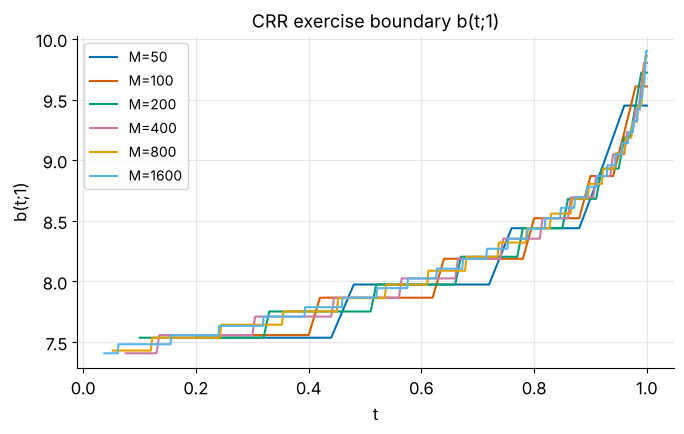

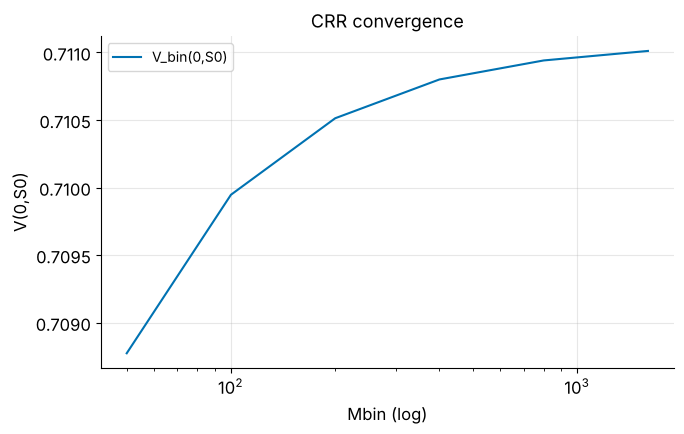

In [30]:
Mbins = [50, 100, 200, 400, 800, 1600]
V0s, bounds = [], {}

def CRRDiscretize_run(steps):
    model = CRRTree(steps=steps)
    model.build_option_tree()
    V0s.append(model.option_tree[0][0]); bounds[steps] = model
    return model

for Mbin in Mbins:
    CRRDiscretize_run(steps=Mbin)

tab = pd.DataFrame({"Mbin": Mbins, "V_bin(0,S0)": V0s})
tab["change"] = tab["V_bin(0,S0)"].diff()
tab["ratio"] = tab["change"].shift(1) / tab["change"]
tab["b(0.5;1)"] = [bounds[M].decision_bound[2 * round(M / 4)] for M in Mbins]   # even layers only
print(tab.to_string(index=False))

# CRR nodes alternate between two grids on odd/even layers, so the boundary is plotted on even layers only
plotsmart([np.arange(M + 1)[::2] / M for M in Mbins], [bounds[M].decision_bound[::2] for M in Mbins],
          labels=[f"M={M}" for M in Mbins], xlabel="t", ylabel="b(t;1)",
          title="CRR exercise boundary b(t;1)", fname="2b_boundary")
plotsmart(np.array(Mbins), [np.array(V0s)], labels=["V_bin(0,S0)"], xlabel="Mbin (log)", ylabel="V(0,S0)",
          xscale="log", title="CRR convergence", fname="2b_convergence")
write_table("am_convergence", [r"$M_{bin}$", r"$V^{bin}(0,S_0)$", "change", "ratio", r"$b(0.5;1)$"],
            [[str(M), f"{v:.5f}", "--" if np.isnan(c) else f"{c:.5f}", "--" if np.isnan(q_) else f"{q_:.2f}", f"{b_:.2f}"]
             for M, v, c, q_, b_ in zip(Mbins, tab["V_bin(0,S0)"], tab["change"], tab["ratio"], tab["b(0.5;1)"])], "rcccc")
macro("AmV", f"{V0s[Mbins.index(1600)]:.4f}"); macro("AmVeight", f"{V0s[Mbins.index(800)]:.4f}"); macro("AmBhalf", f"{tab['b(0.5;1)'].iloc[-1]:.2f}")
macro("AmBearly", f"{np.nanmin(bounds[1600].decision_bound[:60]):.1f}")

### III.5 Two simulated paths and the delta-hedging strategy

path 1 exercised at t = 0.485 ; path 2 stopping index = 800 (= maturity)


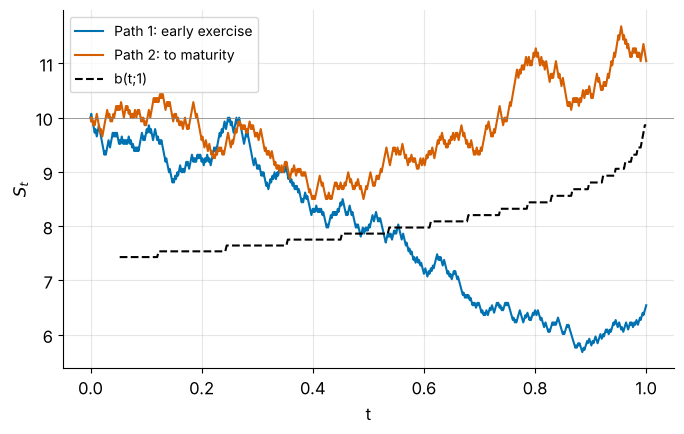

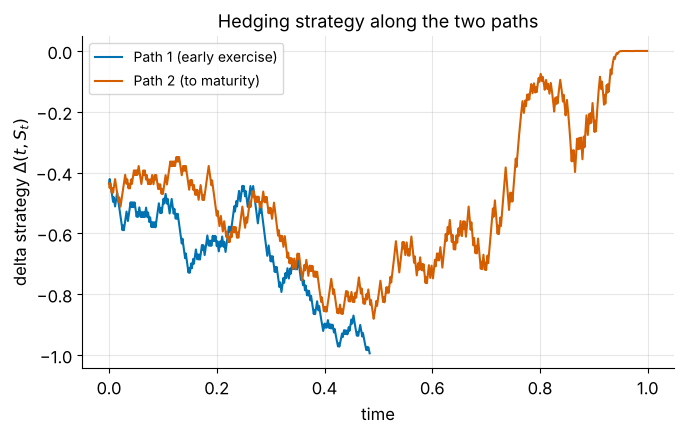

In [31]:
def try_paths(model, prompt=("early exercise occurs", "the option is not exercised until maturity."), steps=100):
    M = model.steps; p1 = p2 = None
    while p1 is None or p2 is None:
        prices, ups = model.simulate(); tau = model.stopping_index(ups)
        if p1 is None and tau < M and abs(tau * model.dt - 0.5) < 0.1: p1 = (prices, ups, tau)
        if p2 is None and tau == M: p2 = (prices, ups, tau)
    return p1, p2

model = CRRTree(steps=800).build_option_tree()
path1, path2 = try_paths(model)
time_grid = np.linspace(0, T, model.steps + 1)
delta = []
for prices, ups, tau in (path1, path2):
    delta.append(np.array([model.hedgings[j][ups[j]] for j in range(tau)]))   # delta held before exercise
print("path 1 exercised at t =", path1[2] * model.dt, "; path 2 stopping index =", path2[2], "(= maturity)")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(time_grid, path1[0], label="Path 1: early exercise"); ax.plot(time_grid, path2[0], label="Path 2: to maturity")
ax.plot(time_grid[::2], model.decision_bound[::2], "k--", label="b(t;1)"); ax.axhline(K, color="gray", lw=0.5)
ax.set_xlabel("t"); ax.set_ylabel("$S_t$"); ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig("figures/2c_paths.png", dpi=200); plt.show()

plotsmart([time_grid[:len(delta[0])], time_grid[:len(delta[1])]], delta,
          labels=["Path 1 (early exercise)", "Path 2 (to maturity)"], xlabel="time",
          ylabel=r"delta strategy $\Delta(t,S_t)$", title="Hedging strategy along the two paths", fname="2d_delta")
macro("PathOneTau", f"{path1[2]*model.dt:.2f}"); macro("DeltaStart", f"{float(delta[0][0]):.2f}"); macro("DeltaPathOneEnd", f"{float(delta[0][-1]):.2f}")

### III.6 Dependence on $\sigma$ and $r$

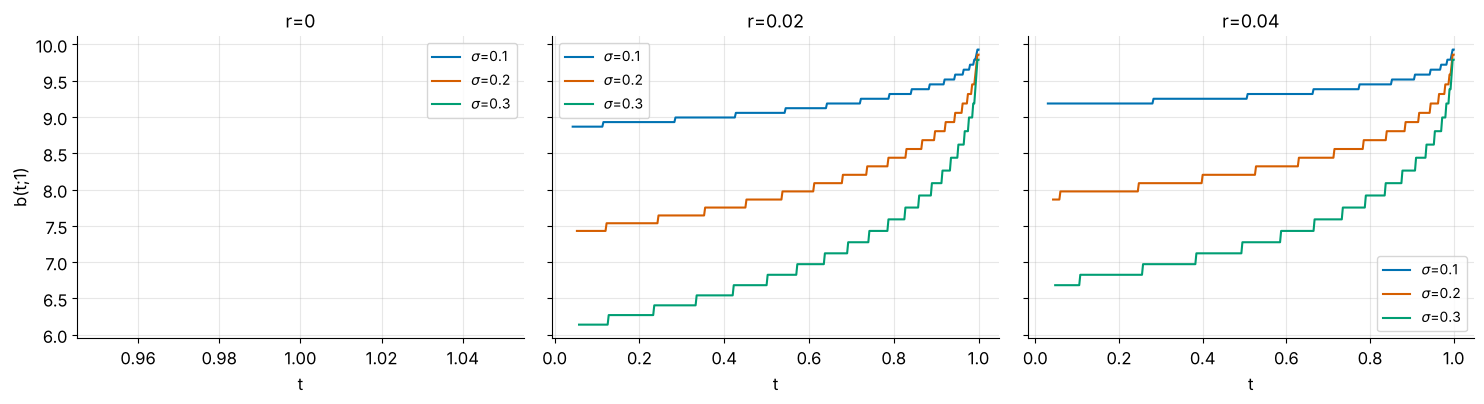

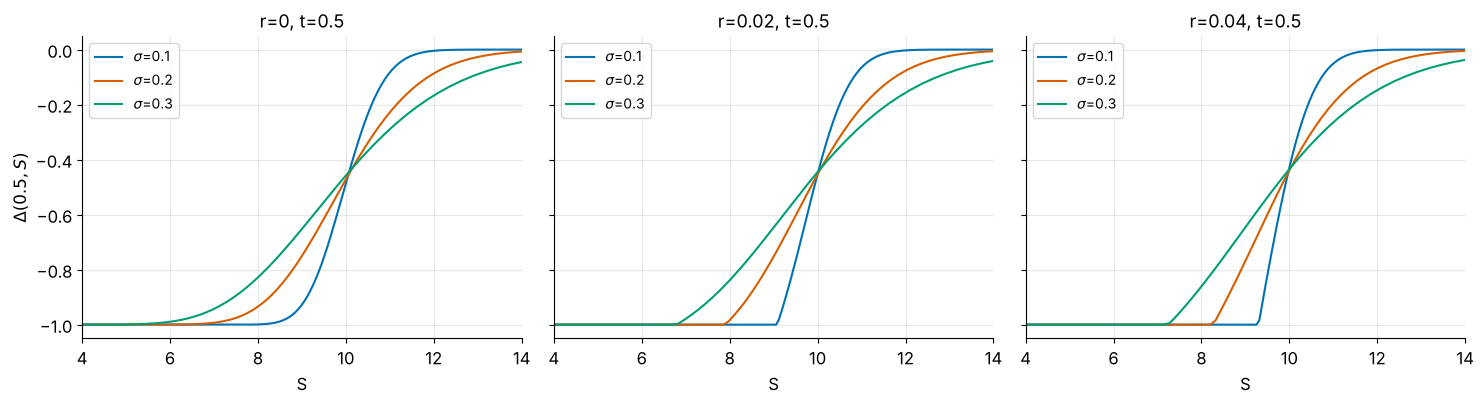

 sigma    r  V(0,S0)  b(0.5)  b(0.9)  Delta(0,S0)
   0.1 0.00   0.3987     NaN     NaN      -0.4801
   0.1 0.02   0.3224  9.0575  9.4500      -0.4359
   0.1 0.04   0.2665  9.2517  9.5171      -0.4093
   0.2 0.00   0.7963     NaN     NaN      -0.4602
   0.2 0.02   0.7109  7.8630  8.8049      -0.4357
   0.2 0.04   0.6403  8.2038  8.9303      -0.4183
   0.3 0.00   1.1920     NaN     NaN      -0.4404
   0.3 0.02   1.1011  6.6828  8.0886      -0.4237
   0.3 0.04   1.0227  7.2746  8.2620      -0.4111


In [32]:
vols = [0.1, 0.2, 0.3]
rs = [0, 0.02, 0.04]

results_of_param_variation = {}
for vol_ in vols:
    for r_ in rs:
        model = CRRTree(vol=vol_, r=r_, steps=800)
        model.build_option_tree()
        hedgings = model.hedgings
        results_of_param_variation[(vol_, r_)] = {'decision boundary': model.decision_bound, 'hedging': hedgings,
                                                  'V0': model.option_tree[0][0], 'model': model}

tt = np.linspace(0, T, 801)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, r_ in zip(axs, rs):
    for vol_ in vols:
        ax.plot(tt[::2], results_of_param_variation[(vol_, r_)]['decision boundary'][::2], label=f"$\\sigma$={vol_}")
    ax.set_title(f"r={r_}"); ax.set_xlabel("t"); ax.grid(alpha=0.3); ax.legend()
axs[0].set_ylabel("b(t;1)"); fig.tight_layout(); fig.savefig("figures/2e_boundary.png", dpi=200); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, r_ in zip(axs, rs):
    for vol_ in vols:
        mdl = results_of_param_variation[(vol_, r_)]['model']; j = 400   # t = 0.5
        ax.plot(mdl.stock_tree[j], results_of_param_variation[(vol_, r_)]['hedging'][j], label=f"$\\sigma$={vol_}")
    ax.set_xlim(4, 14); ax.set_title(f"r={r_}, t=0.5"); ax.set_xlabel("S"); ax.grid(alpha=0.3); ax.legend()
axs[0].set_ylabel(r"$\Delta(0.5,S)$"); fig.tight_layout(); fig.savefig("figures/2e_hedging.png", dpi=200); plt.show()

rows = []
for (v_, r_), res in results_of_param_variation.items():
    rows.append({"sigma": v_, "r": r_, "V(0,S0)": res['V0'], "b(0.5)": res['decision boundary'][400],
                 "b(0.9)": res['decision boundary'][720], "Delta(0,S0)": res['hedging'][0][0]})
sr_table = pd.DataFrame(rows).round(4); print(sr_table.to_string(index=False))
fmt = lambda v: "--" if np.isnan(v) else f"{v:.2f}"
write_table("am_sigma_r", [r"$\sigma$", "$r$", r"$V(0,S_0)$", r"$b(0.5)$", r"$b(0.9)$", r"$\Delta(0,S_0)$"],
            [[f"{a:g}", f"{b:g}", f"{c:.4f}", fmt(d), fmt(e), f"{f:.3f}"] for a, b, c, d, e, f in sr_table.values], "ccccccc"[:6])
b_ = lambda v, r_: results_of_param_variation[(v, r_)]['decision boundary'][400]
macro("BhalfLow", f"{b_(0.1, 0.02):.2f}"); macro("BhalfMid", f"{b_(0.2, 0.02):.2f}"); macro("BhalfHigh", f"{b_(0.3, 0.02):.2f}"); macro("BhalfRhigh", f"{b_(0.2, 0.04):.2f}")
macro("DeltaRangeLo", f"{sr_table['Delta(0,S0)'].min():.2f}"); macro("DeltaRangeHi", f"{sr_table['Delta(0,S0)'].max():.2f}")

### III.7 Long maturities and the perpetual limit

   T  V(0,S0)  b(0;T)  |V-Vinf|
  10   1.7207     5.8    0.7793
  20   2.0601     5.4    0.4399
  50   2.3766     5.2    0.1234
 100   2.4746     5.1    0.0254
1000   2.4847     5.5    0.0153
Vinf(S0) = 2.500000000000001  S* = 5.0


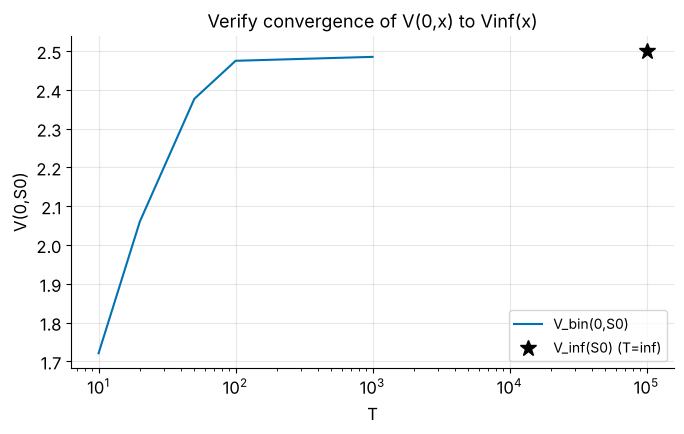

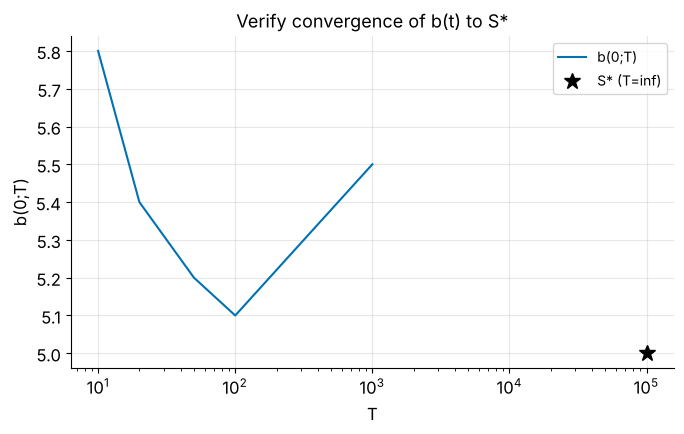

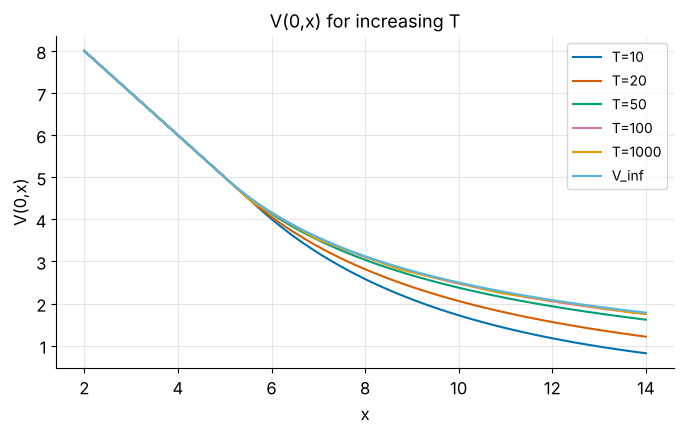

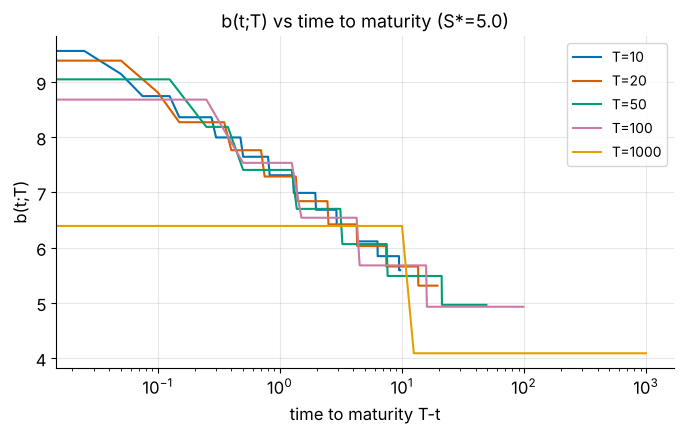

In [33]:
M_bin = 800

Ts = [10, 20, 50, 100, 1000]
xgrid = np.round(np.arange(2.0, 14.01, 0.1), 10)

initial_option_worths = []
exercise_boundaries = []
exercise_boundaries_t0 = []
Vcurves = {}
for T_ in Ts:
    model = CRRTree(T=T_, steps=M_bin).build_option_tree()
    initial_option_worths.append(model.option_tree[0][0])
    exercise_boundaries.append(model.decision_bound)           # b(t;T) path in t
    # V(0,x) and b(0;T): rebuild with S0 = x (node (0,0) is then the date-0 decision)
    Vx, exx = [], []
    for x_ in xgrid:
        mm = CRRTree(S0=x_, T=T_, steps=M_bin).build_option_tree()
        Vx.append(mm.option_tree[0][0]); exx.append(mm.exercise[0][0])
    Vcurves[T_] = np.array(Vx)
    exercise_boundaries_t0.append(xgrid[np.array(exx)].max())

Vinfx = float(Vinf(S0)); Sstar_ = perp_params(r, vol)[1]
print(pd.DataFrame({"T": Ts, "V(0,S0)": initial_option_worths, "b(0;T)": exercise_boundaries_t0,
                    "|V-Vinf|": np.abs(np.array(initial_option_worths) - Vinfx)}).round(4).to_string(index=False))
print("Vinf(S0) =", Vinfx, " S* =", Sstar_)

plotsmart(np.array(Ts), [np.array(initial_option_worths)], labels=["V_bin(0,S0)"], xscale="log",
          single_points=[(100_000, Vinfx, "V_inf(S0) (T=inf)")], xlabel="T", ylabel="V(0,S0)",
          title="Verify convergence of V(0,x) to Vinf(x)", fname="2f_V0_vs_T")
plotsmart(np.array(Ts), [np.array(exercise_boundaries_t0)], labels=["b(0;T)"], xscale="log",
          single_points=[(100_000, Sstar_, "S* (T=inf)")], xlabel="T", ylabel="b(0;T)",
          title="Verify convergence of b(t) to S*", fname="2f_b_vs_T")
plotsmart(xgrid, [Vcurves[T_] for T_ in Ts] + [Vinf(xgrid)], labels=[f"T={T_}" for T_ in Ts] + ["V_inf"],
          xlabel="x", ylabel="V(0,x)", title="V(0,x) for increasing T", fname="2f_Vx")
plotsmart([(T_ - np.arange(M_bin + 1) * (T_ / M_bin))[::2] for T_ in Ts], [b_[::2] for b_ in exercise_boundaries],
          labels=[f"T={T_}" for T_ in Ts], xscale="log", xlabel="time to maturity T-t", ylabel="b(t;T)",
          title=f"b(t;T) vs time to maturity (S*={Sstar_:.1f})", fname="2f_boundary")
long_T_table = (list(Ts), list(initial_option_worths), list(exercise_boundaries_t0))
write_table("am_long_T_coarse", ["$T$", r"$V^{bin}(0,S_0)$", r"$b(0;T)$", r"$|V^{bin}-V_\infty|$"],
            [[str(T_), f"{v_:.4f}", f"{b_:.1f}", f"{abs(v_-Vinfx):.4f}"] for T_, v_, b_ in zip(Ts, initial_option_worths, exercise_boundaries_t0)] + [[r"$\infty$", f"{Vinfx:.4f}", f"{Sstar_:.1f}", "0"]], "rccc")

### III.8 Profit and loss of the buyer, and the optimal-stopping check
The buyer pays the fair value $V(0,S_0)$, simulates the tree with the pricing weights $(p,1-p)$, and exercises at the first date the path enters the exercise region. P&L $=e^{-r\tau}(K-S_\tau)^+-V(0,S_0)$ has mean $0$ under $\mathbb Q$ by the definition of $V$.

V(0,S0)=0.7109  mean P&L=-0.0043  std=0.8306  mean tau=0.8770  p_ex=0.5160


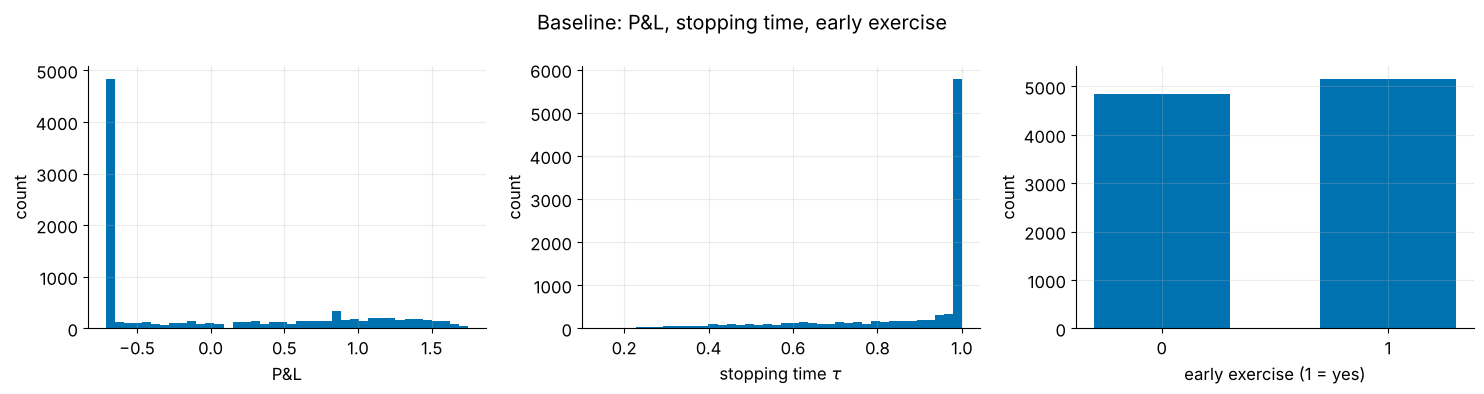

In [34]:
Mbin_sim = 800
oldmodel = CRRTree(steps=Mbin_sim).build_option_tree()
V0_S_0 = fair_value = oldmodel.option_tree[0][0]

def simulate_10000_paths(vol=0.2, r=0.02, n=10000):
    pnls, stopping_times, early_exercise_probas = [], [], []
    model = CRRTree(vol=vol, r=r, steps=Mbin_sim).build_option_tree()
    V0 = model.option_tree[0][0]                  # fair value under (vol, r)
    for i in range(n):
        simulated_stock_prices, ups = model.simulate()
        tau = model.stopping_index(ups)           # optimal stopping index
        Stau = simulated_stock_prices[tau]
        pnls.append(math.exp(-r * tau * model.dt) * max(K - Stau, 0) - V0)
        stopping_times.append(tau * model.dt)
        early_exercise_probas.append(int(tau < model.steps))
    return np.array(pnls), np.array(stopping_times), np.array(early_exercise_probas)

pnls, stopping_times, early_exercise_probas = simulate_10000_paths()
print(f"V(0,S0)={V0_S_0:.4f}  mean P&L={pnls.mean():.4f}  std={pnls.std():.4f}  "
      f"mean tau={stopping_times.mean():.4f}  p_ex={early_exercise_probas.mean():.4f}")
plotsmart(None, [pnls, stopping_times, early_exercise_probas],
          labels=["P&L", "stopping time $\\tau$", "early exercise (1 = yes)"], kind="hist",
          title="Baseline: P&L, stopping time, early exercise", fname="3a_baseline")
base_pnl = dict(mean=pnls.mean(), sd=pnls.std(), se=pnls.std() / math.sqrt(len(pnls)), tau=stopping_times.mean(), pex=early_exercise_probas.mean())
macro("PnLmean", f"{base_pnl['mean']:.3f}"); macro("PnLsd", f"{base_pnl['sd']:.2f}"); macro("PnLse", f"{base_pnl['se']:.3f}")
macro("PnLtau", f"{base_pnl['tau']:.3f}"); macro("PnLpex", f"{base_pnl['pex']:.2f}"); macro("AmVzero", f"{V0_S_0:.4f}")

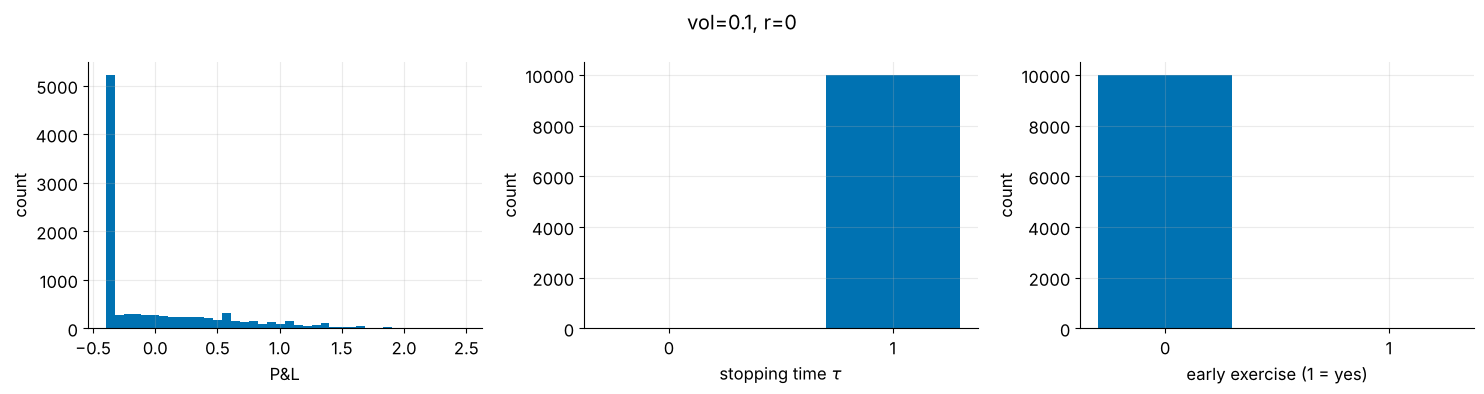

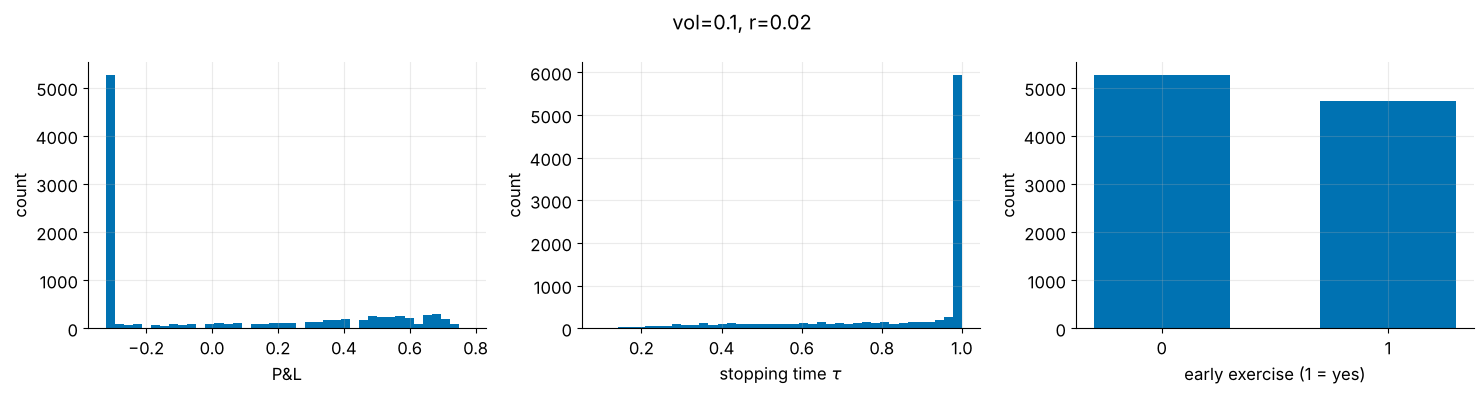

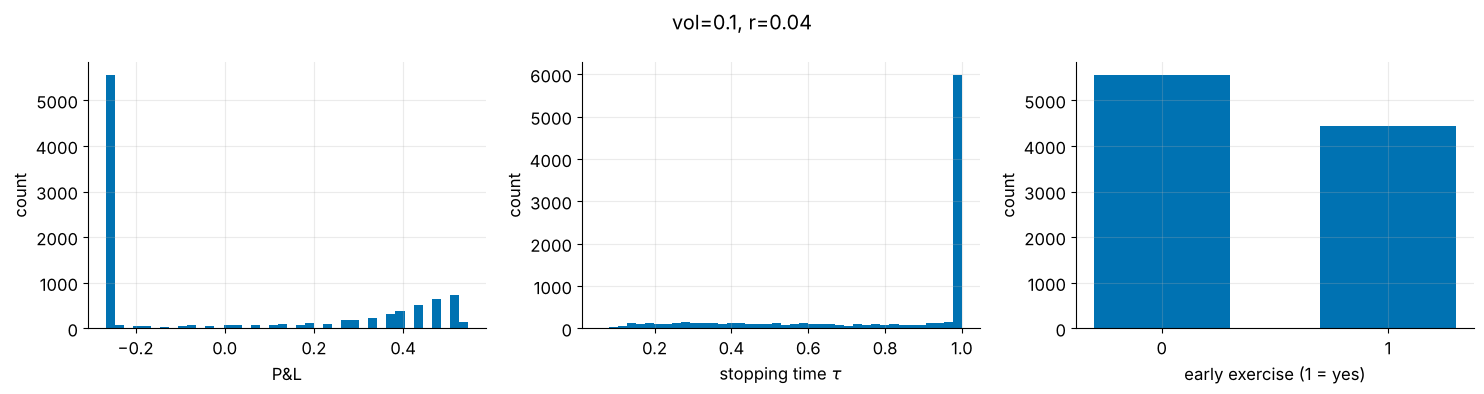

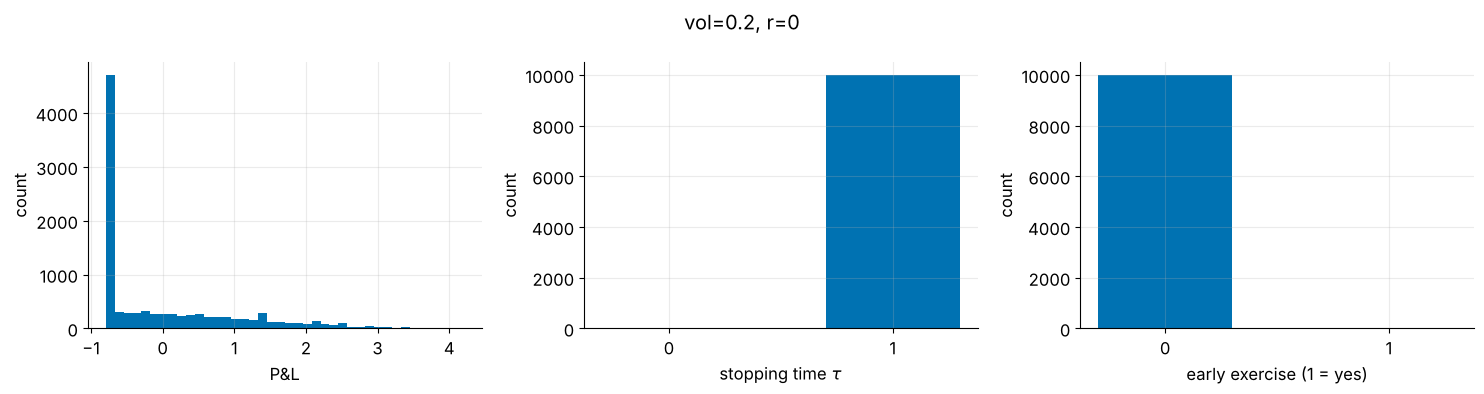

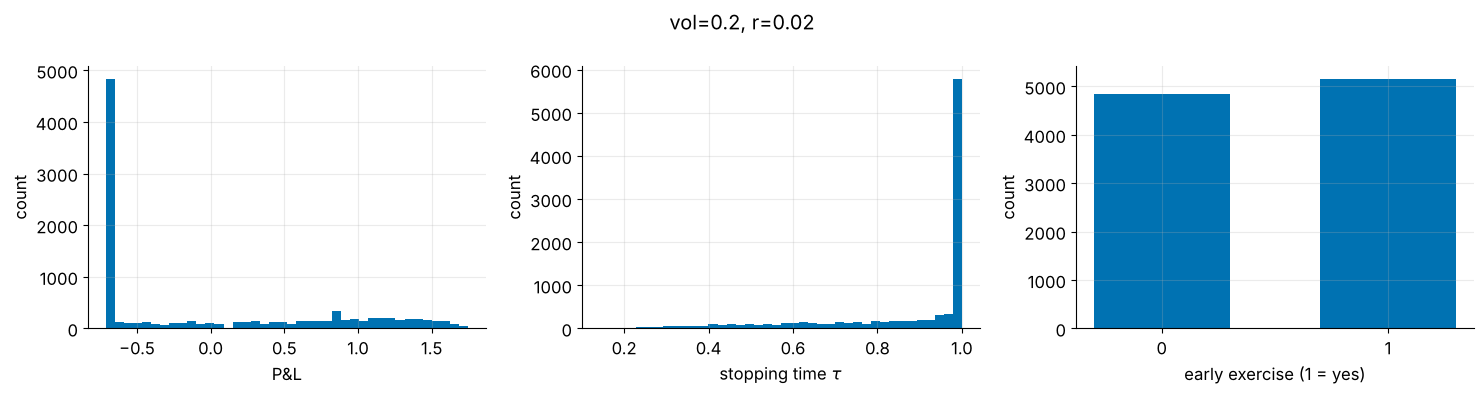

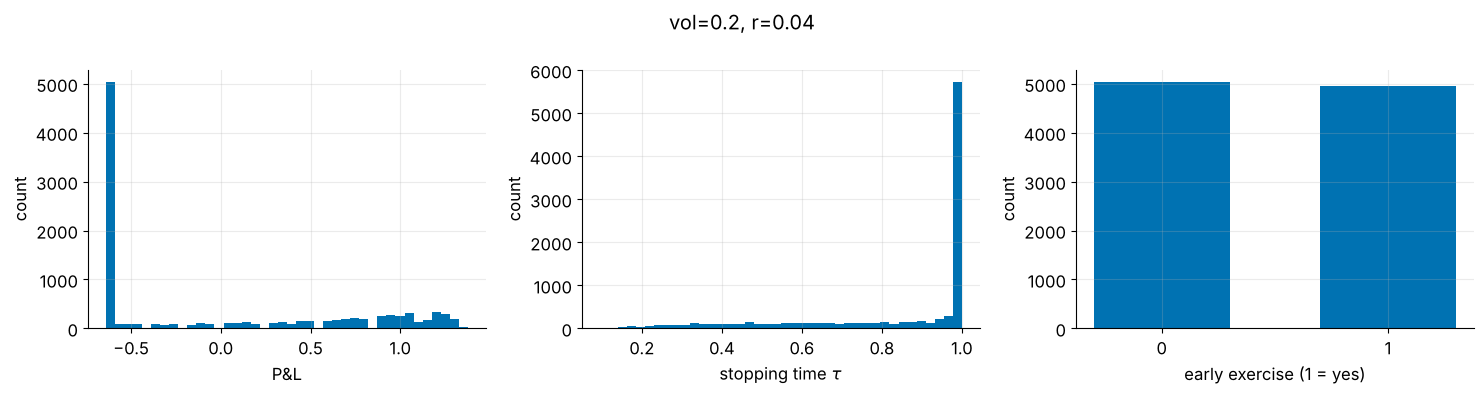

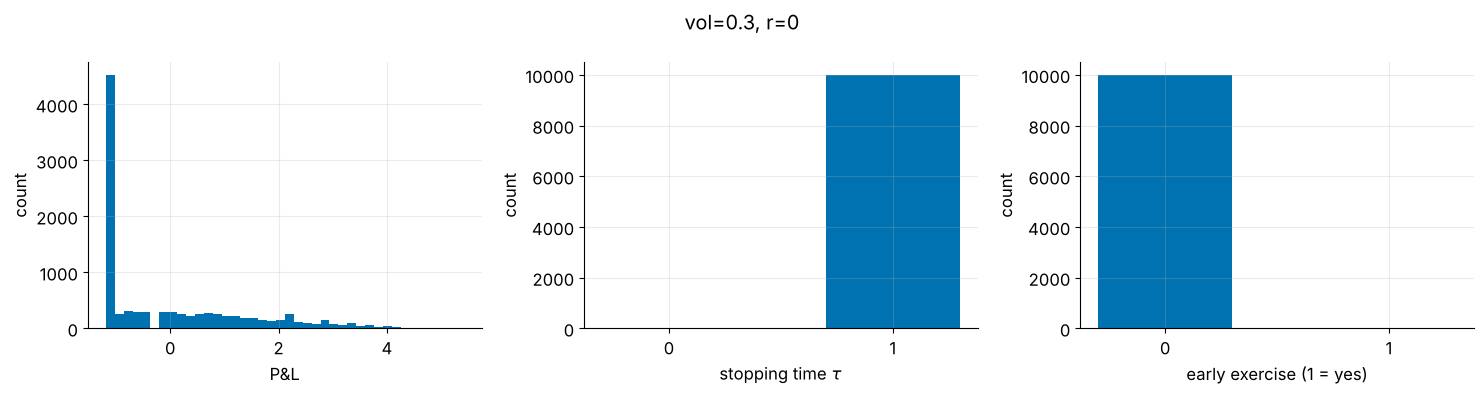

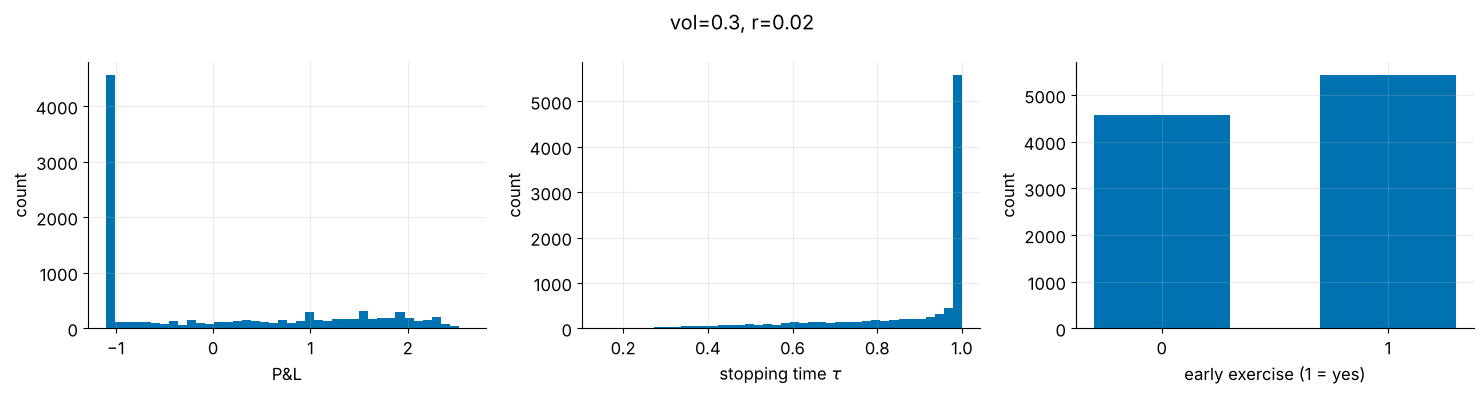

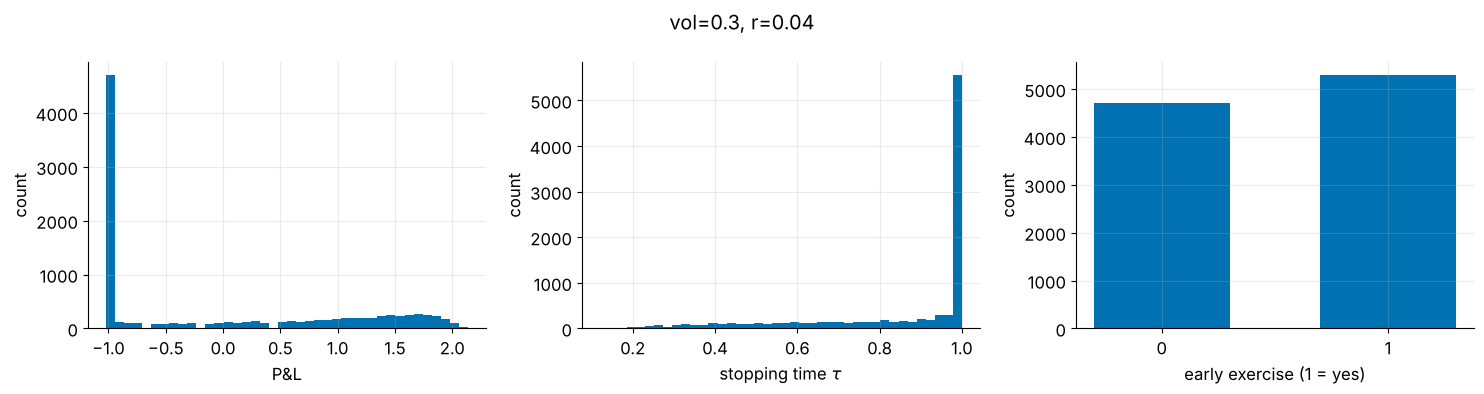

 sigma    r  mean P&L  std P&L  mean tau   p_ex
   0.1 0.00   -0.0053   0.5457    1.0000 0.0000
   0.1 0.02   -0.0023   0.3911    0.8538 0.4731
   0.1 0.04   -0.0025   0.3237    0.8081 0.4443
   0.2 0.00   -0.0087   1.0308    1.0000 0.0000
   0.2 0.02   -0.0043   0.8306    0.8770 0.5160
   0.2 0.04   -0.0037   0.7418    0.8431 0.4962
   0.3 0.00   -0.0118   1.4614    1.0000 0.0000
   0.3 0.02   -0.0009   1.2357    0.8835 0.5435
   0.3 0.04   -0.0068   1.1353    0.8548 0.5295


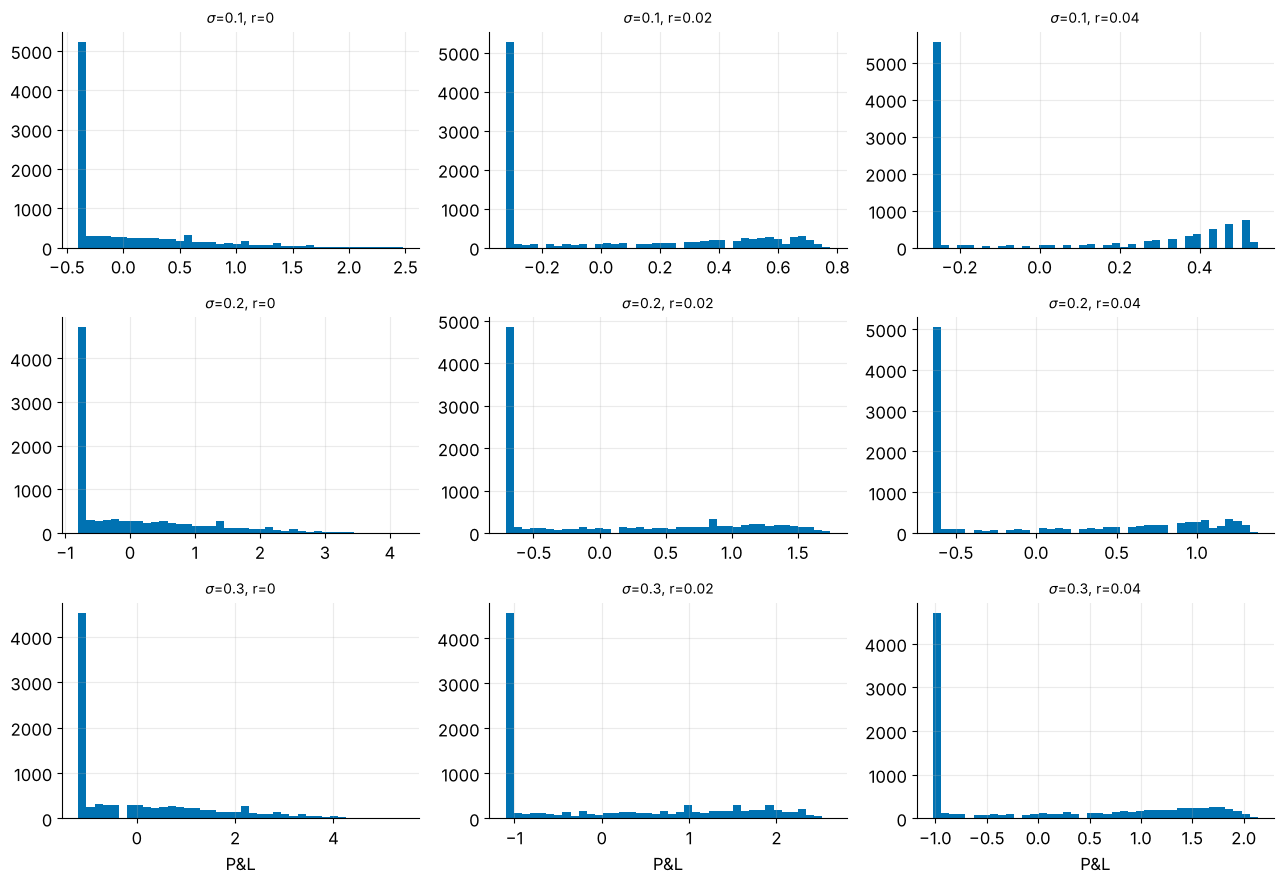

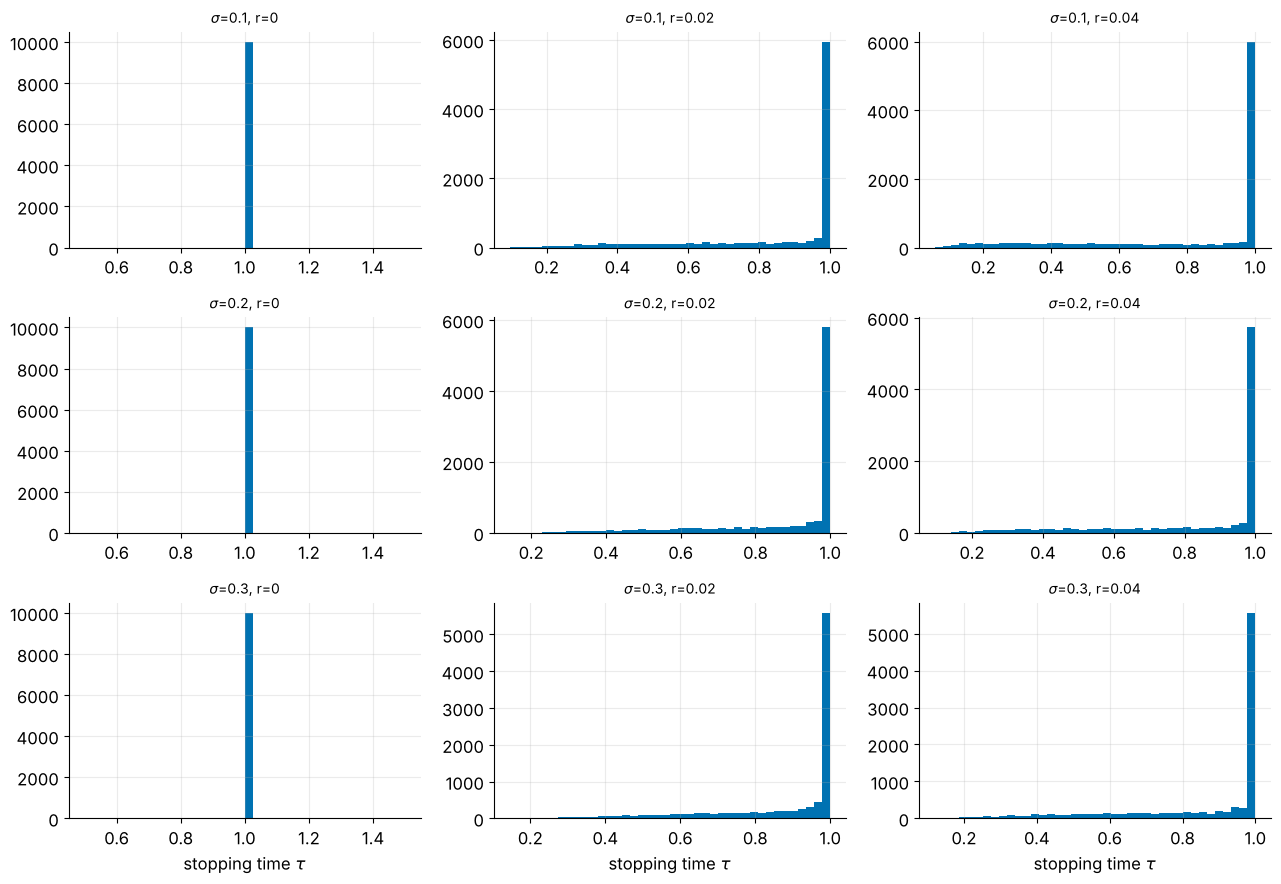

In [35]:
vols = [0.1, 0.2, 0.3]
rs = [0, 0.02, 0.04]

res3b = {}
for vol_ in vols:
    for r_ in rs:
        pnls, stopping_times, early_exercise_probas = simulate_10000_paths(vol=vol_, r=r_)
        res3b[(vol_, r_)] = (pnls, stopping_times, early_exercise_probas)
        plotsmart(None, [pnls, stopping_times, early_exercise_probas],
                  labels=["P&L", "stopping time $\\tau$", "early exercise (1 = yes)"], kind="hist",
                  title=f"vol={vol_}, r={r_}", fname=f"scenarios/3b_vol{vol_}_r{r_}")

pnl_table = pd.DataFrame([{"sigma": v_, "r": r_, "mean P&L": a.mean(), "std P&L": a.std(), "mean tau": b.mean(),
                     "p_ex": c.mean()} for (v_, r_), (a, b, c) in res3b.items()])
print(pnl_table.round(4).to_string(index=False))
write_table("am_pnl_grid", [r"$\sigma$", "$r$", "mean P\\&L (sd)", r"mean $\tau$", r"$p_{ex}$"],
            [[f"{a:g}", f"{b:g}", f"{c:.3f} ({d:.3f})", f"{e:.3f}", f"{f:.3f}"] for a, b, c, d, e, f in pnl_table.values], "ccccc")

fig, axs = plt.subplots(3, 3, figsize=(13, 9))
for a_, v_ in enumerate(vols):
    for b_, r_ in enumerate(rs):
        axs[a_, b_].hist(res3b[(v_, r_)][0], bins=40); axs[a_, b_].set_title(f"$\\sigma$={v_}, r={r_}", fontsize=10)
for ax in axs[-1]: ax.set_xlabel("P&L")
fig.tight_layout(); fig.savefig("figures/3b_pnl_grid.png", dpi=200); plt.show()
fig, axs = plt.subplots(3, 3, figsize=(13, 9))
for a_, v_ in enumerate(vols):
    for b_, r_ in enumerate(rs):
        axs[a_, b_].hist(res3b[(v_, r_)][1], bins=40); axs[a_, b_].set_title(f"$\\sigma$={v_}, r={r_}", fontsize=10)
for ax in axs[-1]: ax.set_xlabel(r"stopping time $\tau$")
fig.tight_layout(); fig.savefig("figures/3b_tau_grid.png", dpi=200); plt.show()

### III.9 Option priced with $\sigma=20\%$ while the realised volatility differs
The buyer pays the $20\%$ price and exercises the first time $S_t\le b_{20\%}(t)$; the stock moves with the realised volatility. Because $b(t;T)$ **decreases** in $\sigma$, for $\sigma_{real}<20\%$ the $20\%$ boundary lies *below* the optimal one (exercise too *late*), and for $\sigma_{real}>20\%$ it lies *above* it (exercise too *early*). The comparison with the optimal rule for the realised volatility is made on the same paths.

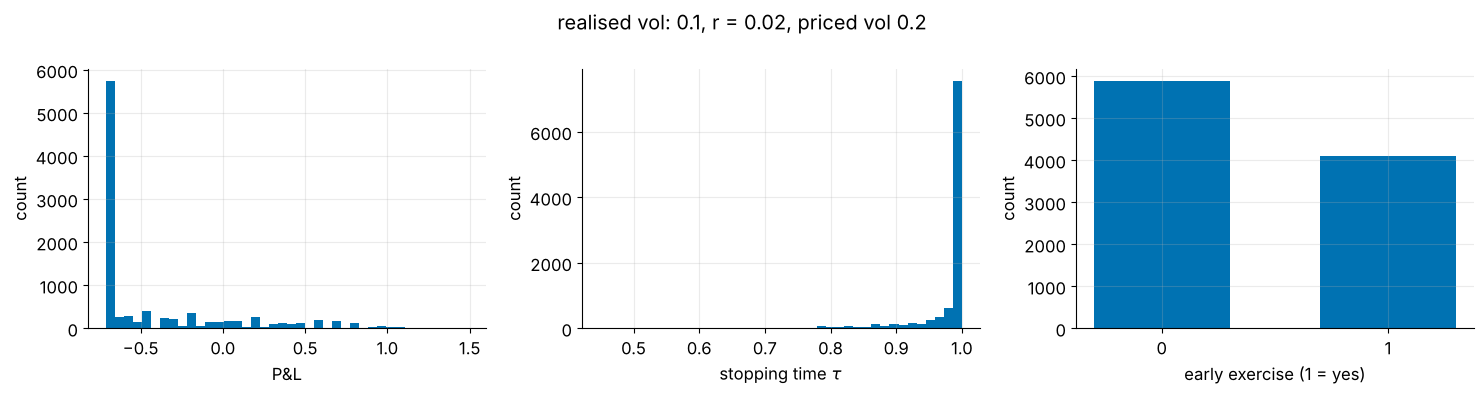

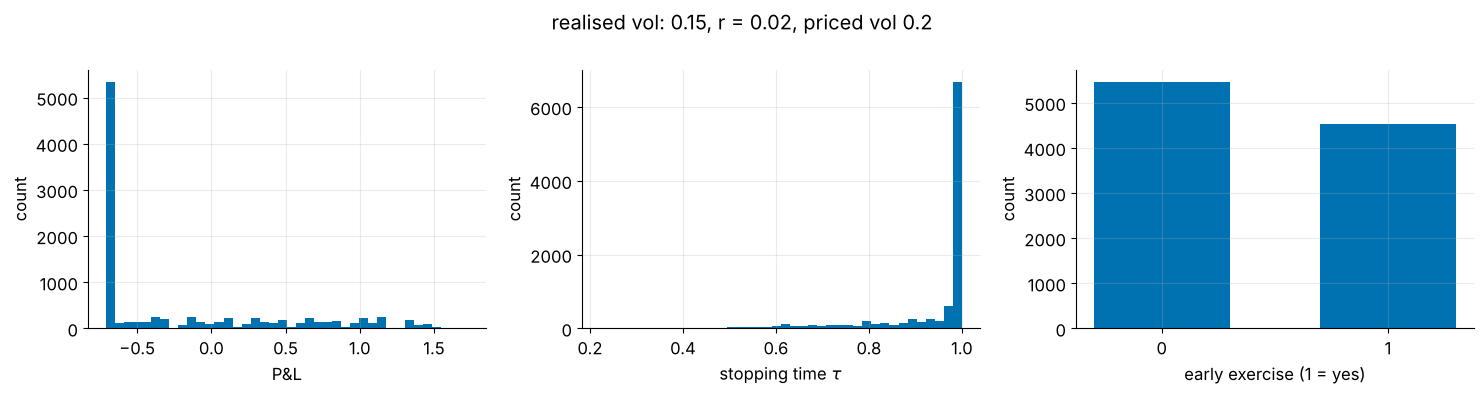

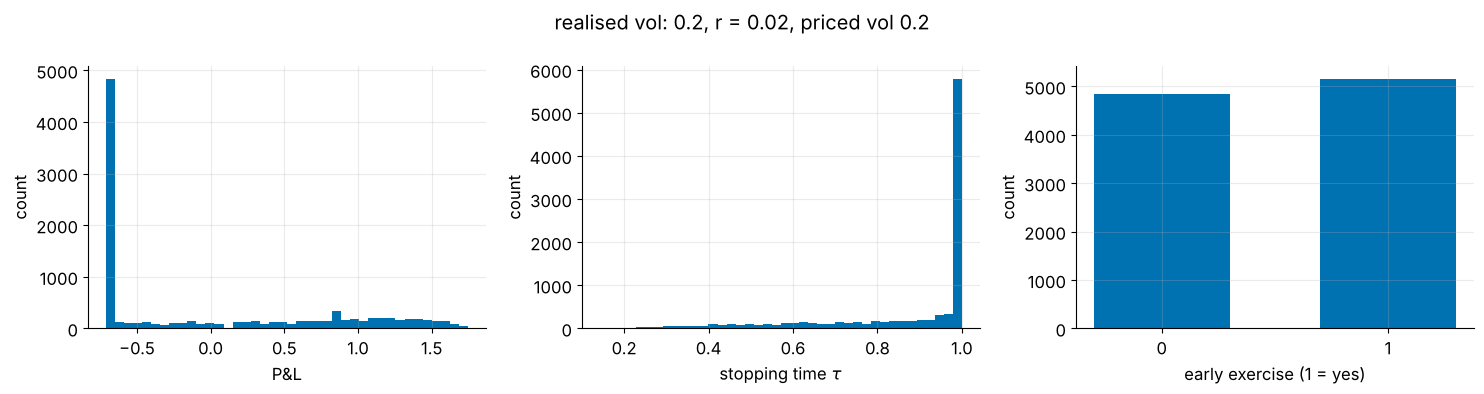

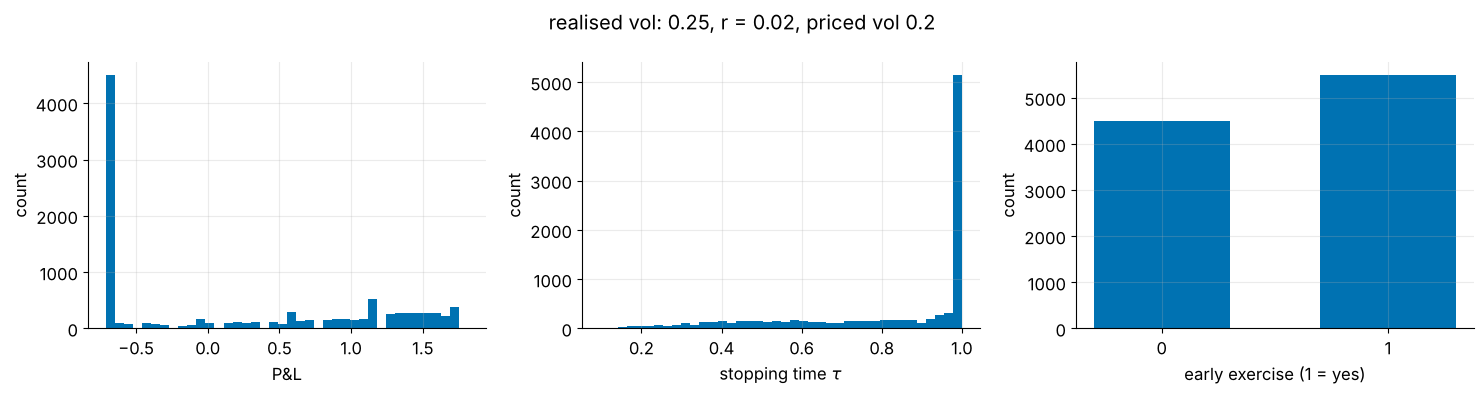

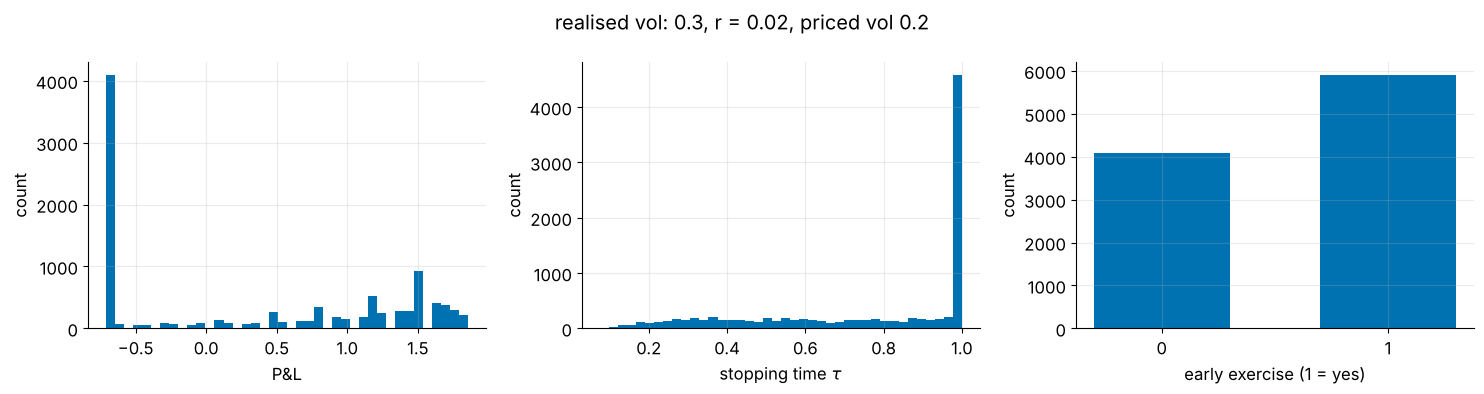

 realised sigma  mean P&L  std P&L  mean tau   p_ex  mean P&L (own optimal)  mean tau (own optimal)  diff P&L (priced - optimal)  diff tau (priced - optimal)
           0.10   -0.4071   0.4707    0.9770 0.4112                 -0.3908                  0.8538                      -0.0163                       0.1232
           0.15   -0.2013   0.6861    0.9364 0.4537                 -0.1974                  0.8693                      -0.0039                       0.0670
           0.20   -0.0043   0.8306    0.8770 0.5160                 -0.0043                  0.8770                       0.0000                       0.0000
           0.25    0.1842   0.9418    0.8252 0.5495                  0.1906                  0.8813                      -0.0064                      -0.0560
           0.30    0.3533   1.0019    0.7656 0.5904                  0.3892                  0.8835                      -0.0359                      -0.1178


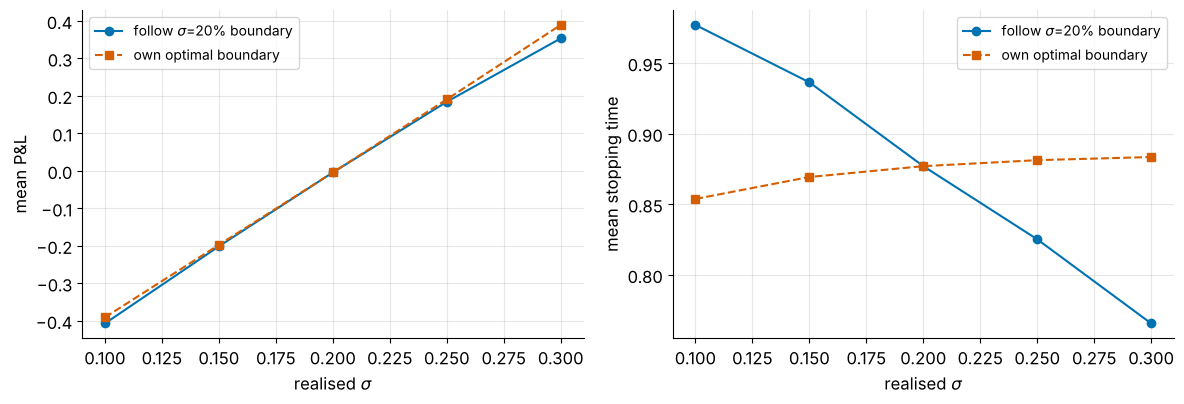

In [36]:
vols = [0.1, 0.15, 0.2, 0.25, 0.3]
priced = CRRTree(vol=0.2, r=r, steps=Mbin_sim).build_option_tree()
fair_value_voldot2 = priced.option_tree[0][0]
exercise_boundary_voldot2 = priced.decision_bound          # b(t_j) from the sigma=20% tree (nan = no exercise)

def simulate_with_priced_boundary(real_vol, n=10000):
    model = CRRTree(vol=real_vol, r=r, steps=Mbin_sim).build_option_tree()   # realised-vol world (same dt grid)
    out = {k: [] for k in ["pnl", "tau", "ex", "pnl_opt", "tau_opt"]}
    for i in range(n):
        prices, ups = model.simulate()
        hit = prices <= exercise_boundary_voldot2 * (1 + 1e-9)   # follow the priced (sigma=20%) boundary (tolerance: float noise in the tree nodes)
        tau = int(np.argmax(hit)) if hit.any() else model.steps
        tau_opt = model.stopping_index(ups)                # truly optimal rule under the realised vol (same path)
        out["pnl"].append(math.exp(-r * tau * model.dt) * max(K - prices[tau], 0) - fair_value_voldot2)
        out["pnl_opt"].append(math.exp(-r * tau_opt * model.dt) * max(K - prices[tau_opt], 0) - fair_value_voldot2)
        out["tau"].append(tau * model.dt); out["tau_opt"].append(tau_opt * model.dt)
        out["ex"].append(int(tau < model.steps))
    return {k: np.array(v) for k, v in out.items()}

res3c = {}
for vol_ in vols:
    res3c[vol_] = d = simulate_with_priced_boundary(vol_)
    plotsmart(None, [d["pnl"], d["tau"], d["ex"]], labels=["P&L", "stopping time $\\tau$", "early exercise (1 = yes)"],
              kind="hist", title=f"realised vol: {vol_}, r = {r}, priced vol 0.2", fname=f"scenarios/3c_vol{vol_}")

summary = pd.DataFrame([{"realised sigma": v_, "mean P&L": d["pnl"].mean(), "std P&L": d["pnl"].std(),
                         "mean tau": d["tau"].mean(), "p_ex": d["ex"].mean(),
                         "mean P&L (own optimal)": d["pnl_opt"].mean(), "mean tau (own optimal)": d["tau_opt"].mean(),
                         "diff P&L (priced - optimal)": (d["pnl"] - d["pnl_opt"]).mean(),
                         "diff tau (priced - optimal)": (d["tau"] - d["tau_opt"]).mean()} for v_, d in res3c.items()])
print(summary.round(4).to_string(index=False))
se_reg = {v_: (d["pnl"] - d["pnl_opt"]).std() / math.sqrt(len(d["pnl"])) for v_, d in res3c.items()}
write_table("am_misspec", [r"$\sigma_{real}$", "mean P\\&L", "sd", r"mean $\tau$", r"$p_{ex}$", r"$\Delta$P\&L vs optimal (s.e.)", r"$\Delta\tau$ vs optimal"],
            [[f"{a:.2f}", f"{b:+.3f}", f"{c:.3f}", f"{e:.3f}", f"{f:.3f}", f"{h:+.3f} ({se_reg[a]:.3f})", f"{i:+.3f}"]
             for a, b, c, e, f, g_, k_, h, i in summary.values], "ccccccc")
macro("RegretSE", f"{max(se_reg.values()):.3f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
axs[0].plot(vols, summary["mean P&L"], "o-", label="follow $\\sigma$=20% boundary")
axs[0].plot(vols, summary["mean P&L (own optimal)"], "s--", label="own optimal boundary")
axs[0].set_xlabel("realised $\\sigma$"); axs[0].set_ylabel("mean P&L"); axs[0].legend(); axs[0].grid(alpha=0.3)
axs[1].plot(vols, summary["mean tau"], "o-", label="follow $\\sigma$=20% boundary")
axs[1].plot(vols, summary["mean tau (own optimal)"], "s--", label="own optimal boundary")
axs[1].set_xlabel("realised $\\sigma$"); axs[1].set_ylabel("mean stopping time"); axs[1].legend(); axs[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/3c_summary.png", dpi=200); plt.show()
s_ = summary.set_index("realised sigma")
macro("MisLowTau", f"{s_.loc[0.1,'mean tau']:.3f}"); macro("MisLowTauOpt", f"{s_.loc[0.1,'mean tau (own optimal)']:.3f}"); macro("MisLowLoss", f"{abs(s_.loc[0.1,'diff P&L (priced - optimal)']):.3f}")
macro("MisHighTau", f"{s_.loc[0.3,'mean tau']:.3f}"); macro("MisHighTauOpt", f"{s_.loc[0.3,'mean tau (own optimal)']:.3f}"); macro("MisHighLoss", f"{abs(s_.loc[0.3,'diff P&L (priced - optimal)']):.3f}")
macro("MisLowPnL", f"{s_.loc[0.1,'mean P&L']:+.2f}"); macro("MisHighPnL", f"{s_.loc[0.3,'mean P&L']:+.2f}")

## III.10 [EXT] Replication check in the tree
Part III.1 claims that the claim exercised at $\tau^*$ is replicable. In the tree this is a finite computation: at a continuation node $(j,i)$ hold $\Delta_{j,i}$ shares and $B_{j,i}=V_{j,i}-\Delta_{j,i}S_{j,i}$ in the bond; one step later the portfolio is worth $\Delta_{j,i}S_{j+1}+B_{j,i}e^{r\Delta t}$, which must equal $V_{j+1}$ at *both* successor nodes. Inside the exercise region this fails by construction: the holder is paid $K-S>$ continuation value, and the seller keeps the difference.

In [37]:
# [EXT] replicating portfolio along simulated paths of the baseline tree
model = CRRTree(steps=800).build_option_tree(); rep_err, rep_n = 0.0, 0
for _ in range(200):
    prices, ups = model.simulate(); tau = model.stopping_index(ups)
    for j in range(tau):
        Vj, Dj = model.option_tree[j][ups[j]], model.hedgings[j][ups[j]]
        Bj = Vj - Dj * prices[j]
        wealth_next = Dj * prices[j + 1] + Bj * math.exp(r * model.dt)
        rep_err = max(rep_err, abs(wealth_next - model.option_tree[j + 1][ups[j + 1]])); rep_n += 1
print(f"replication error over {rep_n} hedge dates on 200 paths: {rep_err:.2e}")
# value left to the seller when the holder exercises at an exercise-region node: payoff - continuation value (j = first exercise node)
gaps = []
for j in range(1, 800, 40):
    idx = np.where(model.exercise[j])[0]
    if len(idx):
        i = idx.max(); cont = math.exp(-r * model.dt) * (model.p * model.option_tree[j + 1][i + 1] + model.q * model.option_tree[j + 1][i])
        gaps.append(model.option_tree[j][i] - cont)
print("payoff minus continuation value at the boundary nodes (seller's surplus if exercised there):", np.round(gaps[:6], 4))
macro("ReplError", f"{rep_err:.0e}")

replication error over 138195 hedge dates on 200 paths: 4.00e-15
payoff minus continuation value at the boundary nodes (seller's surplus if exercised there): [0.0002 0.0002 0.0001 0.0002 0.     0.0002]


## III.11 [EXT] The PDE side: Crank-Nicolson with a penalty for the obstacle
Section III.1 says the tree and the variational inequality describe the same object. We check this with an independent numerical method for the PDE. In $y=\ln x$ the operator has constant coefficients, $V_\tau=\tfrac12\sigma^2V_{yy}+(r-q-\tfrac12\sigma^2)V_y-rV$ with $\tau=T-t$ and $V(0,y)=(K-e^y)^+$. We use Crank-Nicolson time stepping started with four implicit-Euler half steps (Rannacher smoothing of the payoff kink), Dirichlet conditions $V=K-S$ at the left edge and $V=0$ at the right edge, and enforce $V\ge(K-x)^+$ with the penalty (policy-iteration) method: at each step solve $(I-\tfrac12\Delta\tau\,A+P)V^{n+1}=\mathrm{rhs}+Pg$, $P=\rho\,\mathrm{diag}(\mathbf 1_{V<g})$, $\rho=10^7$, iterating on the active set until it stops changing. The exercise boundary is read off the active set.

European put: PDE 0.693581  BS 0.693590  error -9.20e-06


tree M=800,1600,3200,6400: {800: 0.710941, 1600: 0.711011, 3200: 0.711046, 6400: 0.711064}  Richardson: 0.711081
201 50 0.7102241002575825 -0.0008568417583579846 0.02s
401 100 0.7108264620426422 -0.00025447997329830496 0.06s


801 200 0.7110012463158902 -7.969570005028626e-05 0.14s


1601 400 0.7110542390896606 -2.6702926279931205e-05 0.43s


3201 800 0.7110714383713277 -9.503644612829376e-06 1.49s


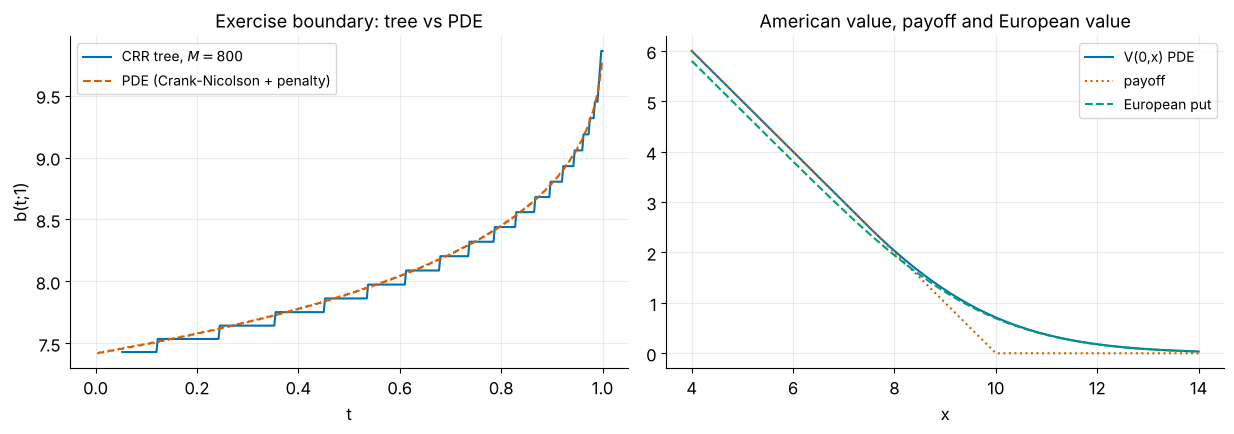

max |b_tree - b_PDE| for t < 0.97: 0.09608731780078195


In [38]:
# [EXT] finite-difference solver for the American (or European) put, log-price grid
def pde_put(S0, K, r, sigma, T, Ny=801, Nt=200, american=True, q=0.0, rho=1e7, half_width=None):
    L = (5 * sigma * math.sqrt(T) + abs(r - q) * T + 0.5) if half_width is None else half_width
    y = math.log(K) + np.linspace(-L, L, Ny); Sg = np.exp(y); dy = y[1] - y[0]; dt = T / Nt
    mu_ = r - q - 0.5 * sigma**2
    a = 0.5 * sigma**2 / dy**2 - mu_ / (2 * dy); b = -sigma**2 / dy**2 - r; c = 0.5 * sigma**2 / dy**2 + mu_ / (2 * dy)
    n = Ny - 2; A = diags([a * np.ones(n - 1), b * np.ones(n), c * np.ones(n - 1)], [-1, 0, 1], format="csc"); I = diags([np.ones(n)], [0], format="csc")
    g = np.maximum(K - Sg, 0.0); gi = g[1:-1]
    left = lambda tau: (K - Sg[0]) if american else (K * math.exp(-r * tau) - Sg[0] * math.exp(-q * tau)); right = lambda tau: 0.0
    V = g[1:-1].copy(); tau = 0.0; bnd = [np.nan]; tgrid = [0.0]
    sched = [(dt / 2, 1.0)] * 4 + [(dt, 0.5)] * (Nt - 2)         # Rannacher start, then Crank-Nicolson
    for h, th in sched:
        bc_old = np.zeros(n); bc_new = np.zeros(n); bc_old[0] = a * left(tau); bc_old[-1] = c * right(tau)
        bc_new[0] = a * left(tau + h); bc_new[-1] = c * right(tau + h)
        rhs = V + (1 - th) * h * (A @ V + bc_old) + th * h * bc_new; M0 = (I - th * h * A).tocsc()
        if american:
            act = V <= gi
            for _ in range(40):
                Vn = splu((M0 + diags([rho * act], [0], format="csc")).tocsc()).solve(rhs + rho * act * gi)
                new = Vn < gi
                if (new == act).all(): break
                act = new
            V = np.maximum(Vn, gi)
        else:
            V = splu(M0).solve(rhs)
        tau += h
        if abs(tau / dt - round(tau / dt)) < 1e-9 and round(tau / dt) >= 1:
            ex = ((V - gi) < 1e-6) & (gi > 0) if american else np.zeros(n, bool)
            bnd.append(Sg[1:-1][ex].max() if ex.any() else np.nan); tgrid.append(tau)
    Vfull = np.concatenate([[left(T)], V, [0.0]])
    value = float(np.interp(math.log(S0), y, Vfull)) if False else float(__import__("scipy.interpolate", fromlist=["CubicSpline"]).CubicSpline(y, Vfull)(math.log(S0)))
    return dict(value=value, S=Sg, V=Vfull, tau=np.array(tgrid), boundary=np.array(bnd))

# sanity: the same code without the obstacle reproduces the Black-Scholes European put
pe = pde_put(10, 10, 0.02, 0.2, 1.0, Ny=1601, Nt=400, american=False)["value"]; bs_pe = float(bs_price(10, 10, 0.02, 0.2, 1.0, "put"))
print(f"European put: PDE {pe:.6f}  BS {bs_pe:.6f}  error {pe-bs_pe:+.2e}")
macro("PdeEuErr", f"{abs(pe-bs_pe):.0e}")

# the American put: grid refinement and comparison with the tree
tree_ref = {M_: tree_price(10, 10, 0.02, 0.2, 1.0, M_, "put", american=True) for M_ in (800, 1600, 3200, 6400)}
V_ref = 2 * tree_ref[6400] - tree_ref[3200]                 # Richardson extrapolation of the tree (first-order convergence)
print("tree M=800,1600,3200,6400:", {k: round(v, 6) for k, v in tree_ref.items()}, " Richardson:", round(V_ref, 6))
rows = []
for Ny, Nt in [(201, 50), (401, 100), (801, 200), (1601, 400), (3201, 800)]:
    (o, secs) = timeit(pde_put, 10, 10, 0.02, 0.2, 1.0, Ny, Nt)
    rows.append([f"{Ny}", f"{Nt}", f"{o['value']:.6f}", f"{o['value']-V_ref:+.1e}", f"{secs:.2f}"])
    print(Ny, Nt, o["value"], o["value"] - V_ref, f"{secs:.2f}s")
write_table("pde_convergence", ["grid points", "time steps", r"$V(0,S_0)$", "error vs tree (Richardson)", "CPU (s)"], rows, "cccrr")
pde_fine = pde_put(10, 10, 0.02, 0.2, 1.0, 3201, 800)
macro("PdeV", f"{pde_fine['value']:.5f}"); macro("TreeRichV", f"{V_ref:.5f}"); macro("PdeTreeDiff", f"{abs(pde_fine['value']-V_ref):.1e}")

tree_m = CRRTree(steps=800).build_option_tree(); tb = np.linspace(0, 1, 801)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
axes[0].plot(tb[::2], tree_m.decision_bound[::2], label="CRR tree, $M=800$")
axes[0].plot(1 - pde_fine["tau"], pde_fine["boundary"], "--", label="PDE (Crank-Nicolson + penalty)")
axes[0].set(xlabel="t", ylabel="b(t;1)", title="Exercise boundary: tree vs PDE"); axes[0].legend()
xs_ = np.linspace(4, 14, 300); Vpde = np.interp(np.log(xs_), np.log(pde_fine["S"]), pde_fine["V"])
axes[1].plot(xs_, Vpde, label="V(0,x) PDE"); axes[1].plot(xs_, np.maximum(10 - xs_, 0), ":", label="payoff"); axes[1].plot(xs_, bs_price(xs_, 10, 0.02, 0.2, 1.0, "put"), "--", label="European put")
axes[1].set(xlabel="x", title="American value, payoff and European value"); axes[1].legend()
fig.tight_layout(); save_fig(fig, "pde_vs_tree")
bd = np.interp(tb[::2], 1 - pde_fine["tau"][::-1], pde_fine["boundary"][::-1]); mask = ~np.isnan(bd) & ~np.isnan(tree_m.decision_bound[::2]) & (tb[::2] < 0.97)
print("max |b_tree - b_PDE| for t < 0.97:", np.abs(bd[mask] - tree_m.decision_bound[::2][mask]).max()); macro("BoundGap", f"{np.abs(bd[mask]-tree_m.decision_bound[::2][mask]).max():.2f}")

## III.12 [EXT] Monte Carlo for American options: Longstaff-Schwartz, and the Barone-Adesi-Whaley approximation
**Least-squares Monte Carlo.** Simulate paths under $\mathbb Q$ on $n$ exercise dates (a *Bermudan* put) and work backwards: at date $t_j$ regress the discounted future cash flow on a polynomial in $S_{t_j}$ using only in-the-money paths, exercise when the payoff exceeds the fitted continuation value, otherwise keep the old cash flow. The estimate is biased low (the regression policy is suboptimal) and approaches the American value as the regression basis grows and $n\to\infty$. We compare with a Bermudan *tree* that allows exercise on the same dates (computed with the vectorised pricer, `ex_every`), so the Monte Carlo error is isolated from the Bermudan-versus-American gap.

**Barone-Adesi-Whaley (1987).** A quasi-analytic formula used for decades on desks: write $P_A=P_E+\varepsilon(S,T)$ and approximate the early-exercise premium by $A_1(S/S^{**})^{q_1}$, with $q_1=\tfrac12\big[-(N-1)-\sqrt{(N-1)^2+4M/\kappa}\big]$, $M=2r/\sigma^2$, $N=2(r-q)/\sigma^2$, $\kappa=1-e^{-rT}$. The critical price $S^{**}$ solves $K-S^{**}=P_E(S^{**})-\big[1-e^{(b-r)T}\Phi(-d_1(S^{**}))\big]S^{**}/q_1$ ($b=r-q$) and $A_1=-\frac{S^{**}}{q_1}\big[1-e^{(b-r)T}\Phi(-d_1(S^{**}))\big]$.

In [39]:
# [EXT] Longstaff-Schwartz least-squares Monte Carlo for the put (Bermudan with n_dates exercise dates)
def lsm_put(S0, K, r, sigma, T, n_dates, M, rng, deg=3, q=0.0):
    dt = T / n_dates; disc = math.exp(-r * dt)
    Z = rng.standard_normal((M, n_dates))
    S = S0 * np.exp(np.cumsum((r - q - 0.5 * sigma**2) * dt + sigma * math.sqrt(dt) * Z, axis=1))
    S = np.concatenate([np.full((M, 1), float(S0)), S], axis=1)
    cash = np.maximum(K - S[:, -1], 0.0)
    for j in range(n_dates - 1, 0, -1):
        cash *= disc; pay = np.maximum(K - S[:, j], 0.0); itm = pay > 0
        if itm.sum() > deg + 1:
            coef = np.polyfit(S[itm, j] / K, cash[itm], deg); cont = np.polyval(coef, S[itm, j] / K)
            ex = pay[itm] > cont; idx = np.where(itm)[0][ex]; cash[idx] = pay[idx]
    disc_cash = disc * cash; est = max(K - S0, disc_cash.mean())
    return est, disc_cash.std(ddof=1) / math.sqrt(M)

# [EXT] Barone-Adesi-Whaley quadratic approximation for the American put
def baw_put(S, K, r, sigma, T, q=0.0):
    b = r - q; Mm = 2 * r / sigma**2; Nn = 2 * b / sigma**2; kap = 1 - math.exp(-r * T)
    q1 = 0.5 * (-(Nn - 1) - math.sqrt((Nn - 1)**2 + 4 * Mm / kap))
    def parts(Ss):
        d1 = (math.log(Ss / K) + (b + 0.5 * sigma**2) * T) / (sigma * math.sqrt(T))
        return d1, 1 - math.exp((b - r) * T) * norm.cdf(-d1)
    def g(Ss):
        d1, f = parts(Ss); return K - Ss - float(bs_price(Ss, K, r, sigma, T, "put", q)) + f * Ss / q1
    Sc = brentq(g, 1e-6 * K, K)
    d1c, fc = parts(Sc); A1 = -(Sc / q1) * fc
    S = np.asarray(S, float)
    val = np.where(S > Sc, bs_price(S, K, r, sigma, T, "put", q) + A1 * (S / Sc) ** q1, K - S)
    return val, Sc

rows, lsm_res = [], {}
for nd in (10, 25, 50, 100):
    est, se = lsm_put(10, 10, 0.02, 0.2, 1.0, nd, 200_000, rng_for(600 + nd))
    berm = tree_price(10, 10, 0.02, 0.2, 1.0, 1600, "put", american=True, ex_every=1600 // nd) if 1600 % nd == 0 else tree_price(10, 10, 0.02, 0.2, 1.0, nd * 32, "put", american=True, ex_every=32)
    lsm_res[nd] = (est, se, berm)
    rows.append([str(nd), f"{est:.4f} ({se:.4f})", f"{berm:.4f}", f"{est-berm:+.4f}", f"{V_ref-berm:+.4f}"])
    print(nd, est, se, berm)
write_table("lsm_vs_bermudan", ["exercise dates", "LSM (s.e.)", "Bermudan tree", "LSM $-$ Bermudan", "American $-$ Bermudan"], rows, "ccccc")
baw_val, baw_Sc = baw_put(10.0, 10.0, 0.02, 0.2, 1.0); print(f"BAW: {float(baw_val):.5f}   critical price S** = {baw_Sc:.3f}   (tree Richardson {V_ref:.5f})")
macro("LSMfifty", f"{lsm_res[50][0]:.4f}"); macro("LSMfiftySE", f"{lsm_res[50][1]:.4f}"); macro("BermFifty", f"{lsm_res[50][2]:.4f}")
macro("BAWV", f"{float(baw_val):.4f}"); macro("BAWerr", f"{float(baw_val)-V_ref:+.4f}"); macro("BAWSc", f"{baw_Sc:.2f}")
# BAW against the tree over a range of spots and maturities
cases = [(S_, T_) for T_ in (0.25, 1.0, 3.0) for S_ in (8.0, 10.0, 12.0)]
rows = []
for S_, T_ in cases:
    vt = 2 * tree_price(S_, 10, 0.02, 0.2, T_, 3200, "put", american=True) - tree_price(S_, 10, 0.02, 0.2, T_, 1600, "put", american=True)
    vb = float(baw_put(S_, 10, 0.02, 0.2, T_)[0]); ve = float(bs_price(S_, 10, 0.02, 0.2, T_, "put"))
    rows.append([f"{S_:g}", f"{T_:g}", f"{ve:.4f}", f"{vt:.4f}", f"{vb:.4f}", f"{vb-vt:+.4f}"])
write_table("baw_vs_tree", ["$S_0$", "$T$", "European (BS)", "American (tree)", "BAW", "BAW $-$ tree"], rows, "ccccrc"[:6])
for rw in rows: print(rw)

10 0.7109698650499829 0.0019140381024829404 0.7085252323024479


25 0.709223246484936 0.0018708888721449086 0.7099958521738983


50 0.7094817713843274 0.0018476789623610628 0.7104896745683194


100 0.7105907369986555 0.0018306701696065779 0.7107564530283275
BAW: 0.70999   critical price S** = 7.549   (tree Richardson 0.71108)


['8', '0.25', '1.9547', '2.0000', '2.0000', '+0.0000']
['10', '0.25', '0.3733', '0.3768', '0.3761', '-0.0007']
['12', '0.25', '0.0129', '0.0130', '0.0131', '+0.0002']
['8', '1', '1.9447', '2.0323', '2.0248', '-0.0075']
['10', '1', '0.6936', '0.7111', '0.7100', '-0.0011']
['12', '1', '0.1762', '0.1791', '0.1807', '+0.0016']
['8', '3', '2.0351', '2.2123', '2.2019', '-0.0103']
['10', '3', '1.0637', '1.1277', '1.1298', '+0.0021']
['12', '3', '0.5222', '0.5458', '0.5532', '+0.0074']


## III.13 [EXT] The early-exercise premium
$\text{EEP}=V^{Am}-V^{Eur}\ge0$ measures what the right to exercise early is worth. It is zero for the call without dividends (the call is never exercised early, because $C^{Eur}\ge S-Ke^{-rT}>S-K$) and for the put when $r=0$ (the strike has no time value to earn). It is largest for deep in-the-money, high-rate, low-volatility puts, where the holder would like to collect $K$ now and earn interest on it.

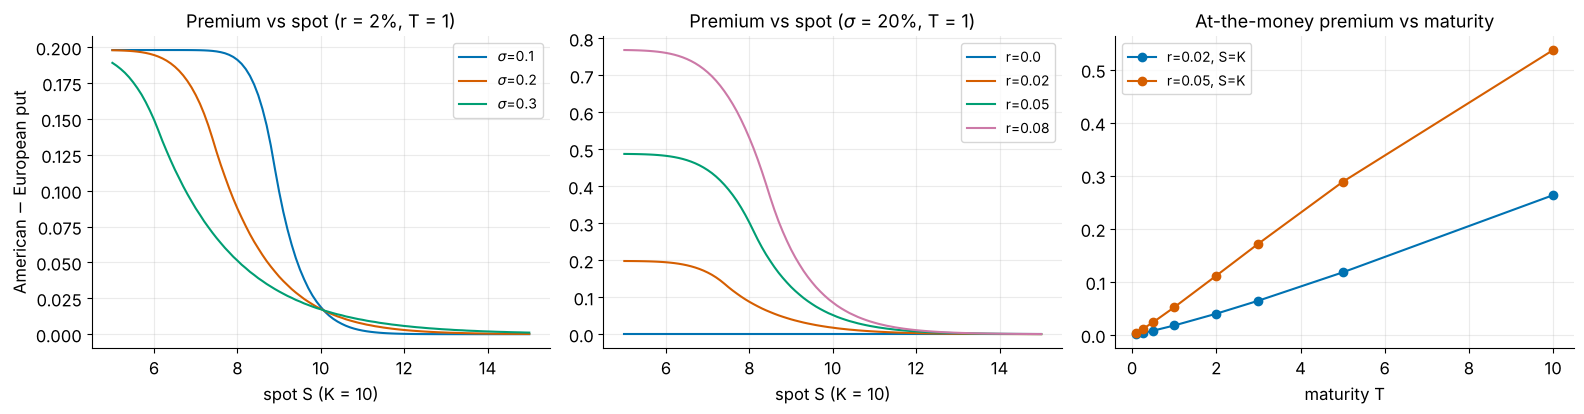

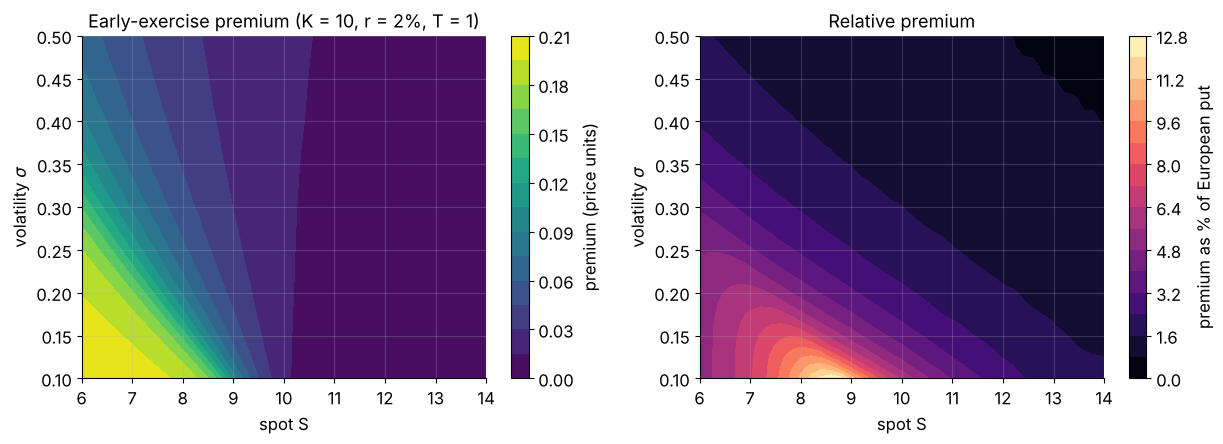

American put-call parity bounds: 0.0000 <= C - P_A = 0.1805 <= 0.1980


In [40]:
# [EXT] premium curves and maps (vectorised tree, N = 600; the lattice error is far below the plotted differences)
def eep(S_, K_, r_, sig_, T_, N=600):
    # American minus European on the SAME lattice, so the lattice error cancels and the premium is exactly 0 when there is no early exercise
    return tree_price(S_, K_, r_, sig_, T_, N, "put", american=True) - tree_price(S_, K_, r_, sig_, T_, N, "put", american=False)

Sg = np.linspace(5, 15, 101)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for sg_, c in zip([0.1, 0.2, 0.3], PALETTE):
    axes[0].plot(Sg, [eep(s_, 10, 0.02, sg_, 1.0) for s_ in Sg], color=c, label=fr"$\sigma$={sg_}")
axes[0].set(xlabel="spot S (K = 10)", ylabel="American $-$ European put", title="Premium vs spot (r = 2%, T = 1)"); axes[0].legend()
for r_, c in zip([0.0, 0.02, 0.05, 0.08], PALETTE):
    axes[1].plot(Sg, [eep(s_, 10, r_, 0.2, 1.0) for s_ in Sg], color=c, label=f"r={r_}")
axes[1].set(xlabel="spot S (K = 10)", title="Premium vs spot ($\\sigma$ = 20%, T = 1)"); axes[1].legend()
Ts_ = np.array([0.1, 0.25, 0.5, 1, 2, 3, 5, 10]); 
for r_, c in zip([0.02, 0.05], PALETTE):
    axes[2].plot(Ts_, [eep(10, 10, r_, 0.2, t_) for t_ in Ts_], "o-", color=c, label=f"r={r_}, S=K")
axes[2].set(xlabel="maturity T", title="At-the-money premium vs maturity"); axes[2].legend()
fig.tight_layout(); save_fig(fig, "eep_curves")

S_map = np.linspace(6, 14, 41); sg_map = np.linspace(0.1, 0.5, 33)
E_map = np.array([[eep(s_, 10, 0.02, v_, 1.0, N=400) for s_ in S_map] for v_ in sg_map])
P_map = np.array([[float(bs_price(s_, 10, 0.02, v_, 1.0, "put")) for s_ in S_map] for v_ in sg_map])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
cs = axes[0].contourf(S_map, sg_map, E_map, 18, cmap="viridis"); fig.colorbar(cs, ax=axes[0], label="premium (price units)")
axes[0].set(xlabel="spot S", ylabel=r"volatility $\sigma$", title="Early-exercise premium (K = 10, r = 2%, T = 1)")
cs = axes[1].contourf(S_map, sg_map, 100 * E_map / P_map, 18, cmap="magma"); fig.colorbar(cs, ax=axes[1], label="premium as % of European put")
axes[1].set(xlabel="spot S", ylabel=r"volatility $\sigma$", title="Relative premium")
fig.tight_layout(); save_fig(fig, "eep_map")
macro("EEPatm", f"{eep(10,10,0.02,0.2,1.0, 1600):.4f}"); macro("EEPatmPct", f"{100*eep(10,10,0.02,0.2,1.0,1600)/float(bs_price(10,10,0.02,0.2,1.0,'put')):.1f}")
macro("EEPmaxPct", f"{(100*E_map/P_map).max():.0f}")

# put-call parity bounds for American options (no dividends): S - K <= C - P <= S - K e^{-rT}  (equality on the right for European)
Cb = float(bs_price(10, 10, 0.02, 0.2, 1.0, "call")); Pa = V_ref
print(f"American put-call parity bounds: {10-10:.4f} <= C - P_A = {Cb-Pa:.4f} <= {10-10*math.exp(-0.02):.4f}")
macro("ParityLo", "0.0000"); macro("ParityMid", f"{Cb-Pa:.4f}"); macro("ParityHi", f"{10-10*math.exp(-0.02):.4f}")

## III.14 [EXT] Dividends: when the American call is worth more than the European call
With a continuous dividend yield $q$ the risk-neutral drift of the stock is $r-q$, so the tree uses $p=\frac{e^{(r-q)\Delta t}-d}{u-d}$ while discounting stays at $r$. The subclass below changes **only** `p` and the payoff, so every method of `CRRTree` (boundary, hedge, simulation, stopping rule) is inherited. For a call the exercise region is $\{x\ge b(t)\}$ and the boundary is the *smallest* exercised node. Early exercise of a call is attractive when the dividend yield exceeds the interest earned on the strike, $q>r(1-\dots)$: heuristically, waiting costs $qS$ per year in lost dividends and earns $rK$ on the deferred payment.

American call, q = 0: price 14.2239 | ever exercised early: False
0.0 14.231254785985819 14.227572688629264
0.02 13.020281268727345 13.016708981200127
0.04 11.883300759815029 11.92579422971068
0.06 10.818570849999702 11.043757880109325


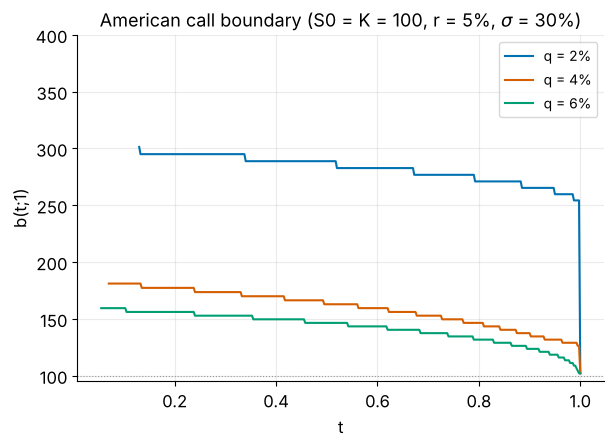

In [41]:
class CRRTreeGen(CRRTree):
    # [EXT] American/European call or put with a continuous dividend yield, built on top of CRRTree
    def __init__(self, S0=100, K=100, mu=0.05, vol=0.3, r=0.05, T=1, steps=100, kind="call", q=0.0, american=True, seed=SEED):
        super().__init__(S0=S0, K=K, mu=mu, vol=vol, r=r, T=T, steps=steps, seed=seed)
        self.kind, self.div, self.american = kind, q, american
        self.risk_neutral_p = (math.exp((r - q) * self.stepsize) - self.d) / (self.u - self.d)
        self.risk_neutral_q = 1 - self.risk_neutral_p; self.p, self.q = self.risk_neutral_p, self.risk_neutral_q

    def build_option_tree(self):
        M, disc = self.steps, math.exp(-self.rate * self.stepsize); sgn = 1.0 if self.kind == "call" else -1.0
        Sj = [np.array(layer) for layer in self.stock_tree]
        V = [None] * (M + 1); ex = [None] * (M + 1)
        V[M] = np.maximum(sgn * (Sj[M] - self.strike_price), 0); ex[M] = V[M] > 0
        for j in range(M - 1, -1, -1):
            a = np.maximum(sgn * (Sj[j] - self.strike_price), 0)
            b = disc * (self.risk_neutral_p * V[j + 1][1:] + self.risk_neutral_q * V[j + 1][:-1])
            ex[j] = (a > b + 1e-12) if self.american else np.zeros(len(a), bool)
            V[j] = np.maximum(a, b) if self.american else b
        self.option_tree, self.exercise = V, ex
        self.exercise_grid = np.zeros((M + 1, M + 1), bool)
        for j in range(M + 1): self.exercise_grid[j, :j + 1] = ex[j]
        pick = np.min if self.kind == "call" else np.max
        self.decision_bound = np.array([pick(Sj[j][ex[j]]) if ex[j].any() else np.nan for j in range(M + 1)])
        self.hedgings = hedgingformula(self.option_tree, Sj)
        return self

# consistency: the subclass with q = 0 is the original put tree; American call without dividends is never exercised early
a_ = CRRTreeGen(10, 10, 0.05, 0.2, 0.02, 1, 400, kind="put", q=0.0).build_option_tree(); b_ = CRRTree(steps=400).build_option_tree()
assert abs(a_.option_tree[0][0] - b_.option_tree[0][0]) < 1e-12
c0 = CRRTreeGen(100, 100, 0.05, 0.3, 0.05, 1, 400, kind="call", q=0.0).build_option_tree()
print("American call, q = 0: price", round(float(c0.option_tree[0][0]), 4), "| ever exercised early:", bool(np.any([e.any() for e in c0.exercise[:-1]])))
rows, calls = [], {}
for qd in (0.0, 0.02, 0.04, 0.06):
    am = CRRTreeGen(100, 100, 0.05, 0.3, 0.05, 1, 800, kind="call", q=qd).build_option_tree(); calls[qd] = am
    eu = float(bs_price(100, 100, 0.05, 0.3, 1.0, "call", qd)); va = float(am.option_tree[0][0])
    eu_tree = tree_price(100, 100, 0.05, 0.3, 1.0, 800, "call", american=False, q=qd)           # same lattice: the lattice error cancels in the premium
    rows.append([f"{100*qd:g}\\%", f"{eu:.4f}", f"{va:.4f}", f"{va-eu_tree:+.4f}", "--" if np.isnan(am.decision_bound[400]) else f"{am.decision_bound[400]:.1f}"])
    print(qd, eu, va)
write_table("dividend_call", ["dividend yield $q$", "European call (BS)", "American call (tree)", "premium", r"$b(0.5)$"], rows, "ccccc")
fig, ax = plt.subplots(figsize=(6.8, 4.5)); t8 = np.linspace(0, 1, 801)
for qd, c in zip((0.02, 0.04, 0.06), PALETTE):
    ax.plot(t8[::2], calls[qd].decision_bound[::2], color=c, label=f"q = {100*qd:g}%")
ax.axhline(100, color="0.6", lw=0.8, ls=":"); ax.set(xlabel="t", ylabel="b(t;1)", title="American call boundary (S0 = K = 100, r = 5%, $\\sigma$ = 30%)", ylim=(95, 400)); ax.legend()
save_fig(fig, "dividend_boundary")
macro("DivPremSix", f"{float(calls[0.06].option_tree[0][0]) - tree_price(100,100,0.05,0.3,1.0,800,'call',american=False,q=0.06):.3f}")

## III.15 [EXT] An American put on the NVDA inputs
The NVDA parameters of Part II are reused for the *put* with the same strike, so the two halves of the report can be read together: put-call parity pins the European put at $C-S_0+Ke^{-rT}$ and the tree adds the early-exercise premium. We also compare the exercise boundary (scaled by the strike, which makes it independent of $S_0$) across volatility and interest-rate regimes, because the boundary is what a risk manager monitors for assignment risk.

check: Richardson European tree vs Black-Scholes put: -2.157537757341288e-07
NVDA put: European 31.9207 (parity 31.9207), American 32.5674, premium 0.6467 (2.03%), implied vol of the American price 38.43% vs 37.73%
['price', '31.9207', '32.5674']
['$\\Delta$', '-0.39531', '-0.40708']
['$\\Gamma$', '0.0042732', '0.0044968']
['vega', '92.007', '92.069']
['$\\Theta$ (per year)', '-13.69', '-14.5']
['$\\rho$', '-126.36', '-99.365']


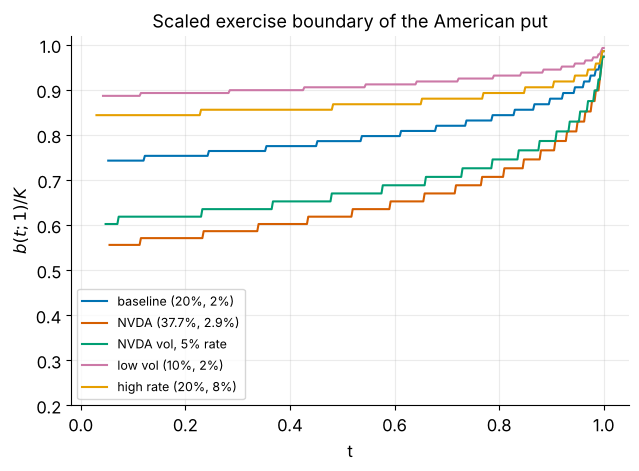

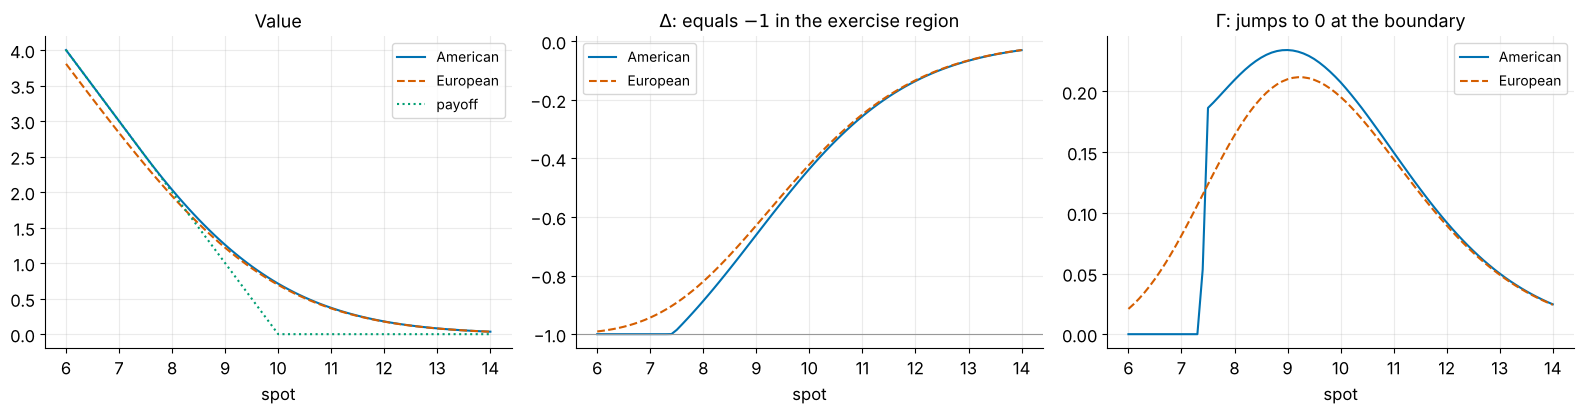

In [42]:
NVS, NVK, NVr, NVsig, NVT = price, price, risk_free_CAD_rate, annualized_252_volatility, 1.0
put_eu = float(bs_price(NVS, NVK, NVr, NVsig, NVT, "put")); parity_put = BS - NVS + NVK * math.exp(-NVr * NVT)
tp = {M_: tree_price(NVS, NVK, NVr, NVsig, NVT, M_, "put", american=True) for M_ in (1600, 3200)}; put_am = 2 * tp[3200] - tp[1600]
te = {M_: tree_price(NVS, NVK, NVr, NVsig, NVT, M_, "put", american=False) for M_ in (1600, 3200)}; put_eu_tree = 2 * te[3200] - te[1600]
print("check: Richardson European tree vs Black-Scholes put:", put_eu_tree - put_eu)
iv_am = implied_vol(put_am, NVS, NVK, NVr, NVT, "put")
print(f"NVDA put: European {put_eu:.4f} (parity {parity_put:.4f}), American {put_am:.4f}, premium {put_am-put_eu_tree:.4f} ({100*(put_am/put_eu_tree-1):.2f}%), implied vol of the American price {100*iv_am:.2f}% vs {100*NVsig:.2f}%")
gA = tree_greeks(NVS, NVK, NVr, NVsig, NVT, 1000, "put", american=True); gE = bs_greeks(NVS, NVK, NVr, NVsig, NVT, "put")
rows = [["price", f"{put_eu:.4f}", f"{put_am:.4f}"]] + [[nm, f"{float(gE[k]):.5g}", f"{gA[k]:.5g}"] for nm, k in [(r"$\Delta$", "delta"), (r"$\Gamma$", "gamma"), ("vega", "vega"), (r"$\Theta$ (per year)", "theta"), (r"$\rho$", "rho")]]
write_table("nvda_put", ["", "European put (BS)", "American put (tree)"], rows, "lcc")
for rw in rows: print(rw)
nvm = CRRTree(S0=NVS, K=NVK, vol=NVsig, r=NVr, T=1, steps=800).build_option_tree()
macro("NvdaPutEu", f"{put_eu:.4f}"); macro("NvdaPutAm", f"{put_am:.4f}"); macro("NvdaPutEEP", f"{put_am-put_eu_tree:.4f}"); macro("NvdaPutEEPpct", f"{100*(put_am/put_eu_tree-1):.2f}")
macro("NvdaPutIV", f"{100*iv_am:.2f}"); macro("NvdaPutIVup", f"{100*(iv_am-NVsig):.2f}"); macro("NvdaBhalf", f"{nvm.decision_bound[400]:.1f}"); macro("NvdaBhalfPct", f"{100*nvm.decision_bound[400]/NVK:.1f}")
macro("NvdaPutDelta", f"{gA['delta']:.3f}"); macro("NvdaPutDeltaEu", f"{float(gE['delta']):.3f}")
macro("ParityNvda", f"{abs(put_eu-parity_put):.0e}")

regimes = {"baseline (20%, 2%)": (0.2, 0.02), "NVDA (37.7%, 2.9%)": (NVsig, NVr), "NVDA vol, 5% rate": (NVsig, 0.05), "low vol (10%, 2%)": (0.1, 0.02), "high rate (20%, 8%)": (0.2, 0.08)}
fig, ax = plt.subplots(figsize=(7.2, 4.8))
for (nm, (v_, r_)), c in zip(regimes.items(), PALETTE):
    mm = CRRTree(S0=10, K=10, vol=v_, r=r_, T=1, steps=800).build_option_tree(); ax.plot(t8[::2], mm.decision_bound[::2] / 10, color=c, label=nm)
ax.set(xlabel="t", ylabel="$b(t;1)/K$", title="Scaled exercise boundary of the American put"); ax.legend(fontsize=9); ax.set_ylim(0.2, 1.02)
save_fig(fig, "boundary_regimes")

# delta and gamma of the American vs European put at t = 0 as functions of spot
xg = np.linspace(6, 14, 81); gAm = [tree_greeks(x_, 10, 0.02, 0.2, 1.0, 1000, "put", american=True) for x_ in xg]; gEu = bs_greeks(xg, 10, 0.02, 0.2, 1.0, "put")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(xg, [g_["price"] for g_ in gAm], label="American"); axes[0].plot(xg, bs_price(xg, 10, 0.02, 0.2, 1.0, "put"), "--", label="European"); axes[0].plot(xg, np.maximum(10 - xg, 0), ":", label="payoff"); axes[0].set(xlabel="spot", title="Value"); axes[0].legend()
axes[1].plot(xg, [g_["delta"] for g_ in gAm], label="American"); axes[1].plot(xg, gEu["delta"], "--", label="European"); axes[1].axhline(-1, color="0.6", lw=0.8); axes[1].set(xlabel="spot", title=r"$\Delta$: equals $-1$ in the exercise region"); axes[1].legend()
axes[2].plot(xg, [g_["gamma"] for g_ in gAm], label="American"); axes[2].plot(xg, gEu["gamma"], "--", label="European"); axes[2].set(xlabel="spot", title=r"$\Gamma$: jumps to 0 at the boundary"); axes[2].legend()
fig.tight_layout(); save_fig(fig, "am_greeks")

## III.16 [EXT] Profit and loss under the real-world measure, and tail risk
Part III.8 simulated under $\mathbb Q$, where the buyer's mean P&L is zero by construction. A risk report should show what happens under the real-world measure $\mathbb P$ with drift $\mu$: the tree is simulated with up-probability $p^{\mathbb P}=\frac{e^{\mu\Delta t}-d}{u-d}$ while the buyer still pays the $\mathbb Q$-fair price and exercises on the $\mathbb Q$-optimal boundary. A drift above $r$ makes the put less valuable than its price (negative mean P&L); the dispersion and the tail (5% quantile, expected shortfall) are the quantities a limit system would use. The simulation is vectorised over paths; the cell first checks that it reproduces the loop of III.8 at $\mu=r$.

Q (vectorised, 1e5 paths): mean P&L -0.0041 +- 0.0026, sd 0.8329, tau 0.8765, p_ex 0.5122
Q (handwritten loop, 1e4 paths): mean P&L -0.0043 +- 0.0083, sd 0.8306, tau 0.8770, p_ex 0.5160


risk-neutral, $\mu=r=2\%$ {'mean': -0.0029, 'sd': 0.8341, 'ptot': 0.4882, 'q95': 1.463, 'q99': 1.6323, 'es95': 1.5607} tau 0.876 p_ex 0.512


real world, $\mu=5\%$ {'mean': -0.0939, 'sd': 0.8072, 'ptot': 0.5439, 'q95': 1.4068, 'q99': 1.6317, 'es95': 1.5422} tau 0.894 p_ex 0.456


real world, $\mu=10\%$ {'mean': -0.2461, 'sd': 0.7387, 'ptot': 0.6407, 'q95': 1.3492, 'q99': 1.5767, 'es95': 1.4977} tau 0.922 p_ex 0.359


real world, $\mu=-5\%$ {'mean': 0.2407, 'sd': 0.8686, 'ptot': 0.353, 'q95': 1.5199, 'q99': 1.6335, 'es95': 1.6012} tau 0.825 p_ex 0.647


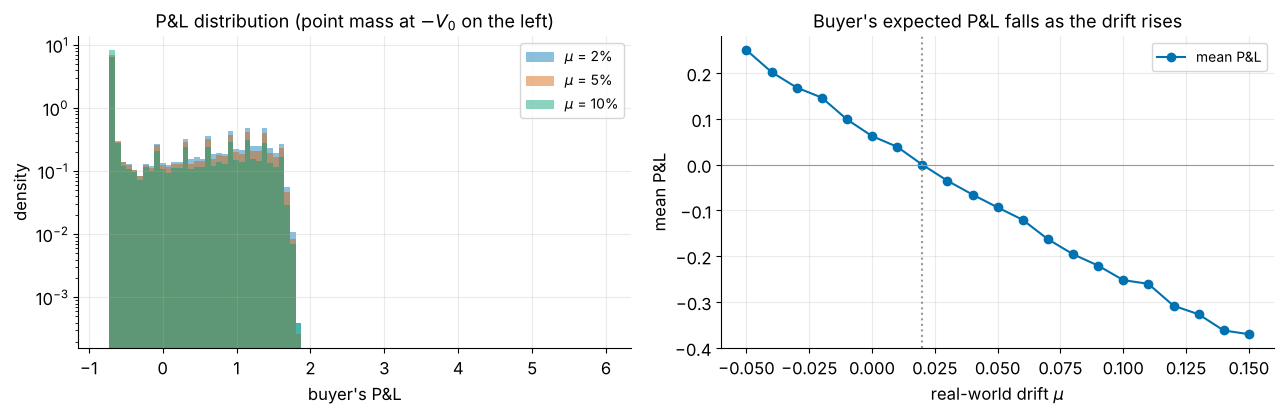

In [43]:
# [EXT] vectorised P&L simulation under an arbitrary up-probability
def pnl_paths(model, n, p_up, rng, V0=None, r_=None):
    Mm = model.steps; r_ = model.r if r_ is None else r_; V0 = model.option_tree[0][0] if V0 is None else V0
    ups = np.concatenate([np.zeros((n, 1), np.int32), np.cumsum(rng.random((n, Mm)) < p_up, axis=1, dtype=np.int32)], axis=1)
    flags = model.exercise_grid[np.arange(Mm + 1)[None, :], ups]
    any_ = flags.any(axis=1); tau = np.where(any_, flags.argmax(axis=1), Mm)
    Stau = model.S0 * model.u ** (2 * ups[np.arange(n), tau] - tau)
    return np.exp(-r_ * tau * model.dt) * np.maximum(model.K - Stau, 0) - V0, tau * model.dt, tau < Mm

base = CRRTree(steps=800).build_option_tree(); dt_ = base.dt; V0b = base.option_tree[0][0]
pq = base.risk_neutral_p; pnl_q, tau_q, ex_q = pnl_paths(base, 100_000, pq, rng_for(700))
print(f"Q (vectorised, 1e5 paths): mean P&L {pnl_q.mean():+.4f} +- {pnl_q.std()/math.sqrt(1e5):.4f}, sd {pnl_q.std():.4f}, tau {tau_q.mean():.4f}, p_ex {ex_q.mean():.4f}")
print(f"Q (handwritten loop, 1e4 paths): mean P&L {base_pnl['mean']:+.4f} +- {base_pnl['se']:.4f}, sd {base_pnl['sd']:.4f}, tau {base_pnl['tau']:.4f}, p_ex {base_pnl['pex']:.4f}")
macro("PnLQmean", f"{pnl_q.mean():+.4f}"); macro("PnLQse", f"{pnl_q.std()/math.sqrt(1e5):.4f}")

def risk_metrics(x, V0):
    # the buyer's loss is capped at the premium, so the left tail is uninformative (more than half the paths lose all of it);
    # the tail that matters is the SELLER's: seller loss = buyer P&L. Report P(total loss), sd and the right tail of the buyer's P&L.
    q95, q99 = np.quantile(x, 0.95), np.quantile(x, 0.99)
    return dict(mean=x.mean(), sd=x.std(), ptot=(x < -V0 + 1e-9).mean(), q95=q95, q99=q99, es95=x[x >= q95].mean())
rows, rm = [], {}
for nm, mu_ in [("risk-neutral, $\\mu=r=2\\%$", r), ("real world, $\\mu=5\\%$", 0.05), ("real world, $\\mu=10\\%$", 0.10), ("real world, $\\mu=-5\\%$", -0.05)]:
    pp = (math.exp(mu_ * dt_) - base.d) / (base.u - base.d)
    x, ta, ex_ = pnl_paths(base, 100_000, pp, rng_for(710 + int(100 * mu_))); m_ = risk_metrics(x, V0b); rm[mu_] = (x, m_, ta.mean(), ex_.mean())
    rows.append([nm, f"{m_['mean']:+.3f}", f"{m_['sd']:.3f}", f"{100*m_['ptot']:.1f}\\%", f"{m_['q95']:.3f}", f"{m_['q99']:.3f}", f"{m_['es95']:.3f}", f"{ta.mean():.3f}", f"{ex_.mean():.3f}"])
    print(nm, {k: round(float(v), 4) for k, v in m_.items()}, "tau", ta.mean().round(3), "p_ex", ex_.mean().round(3))
write_table("am_pnl_real_world", ["Measure", "mean", "sd", r"P(lose premium)", r"95\% quantile", r"99\% quantile", r"ES$_{95\%}$", r"mean $\tau$", r"$p_{ex}$"], rows, "lcccccccc")
macro("PnLPmean", f"{rm[0.05][1]['mean']:+.3f}"); macro("PnLPmeanTen", f"{rm[0.10][1]['mean']:+.3f}"); macro("PnLPtot", f"{100*rm[0.05][1]['ptot']:.1f}"); macro("PnLQtot", f"{100*rm[r][1]['ptot']:.1f}")
macro("PnLPqNinetyNine", f"{rm[0.05][1]['q99']:.2f}"); macro("PnLQqNinetyNine", f"{rm[r][1]['q99']:.2f}"); macro("PnLPes", f"{rm[0.05][1]['es95']:.2f}"); macro("PnLQes", f"{rm[r][1]['es95']:.2f}")
macro("PnLPtau", f"{rm[0.05][2]:.3f}"); macro("PnLPpex", f"{rm[0.05][3]:.2f}"); macro("PnLPsd", f"{rm[0.05][1]['sd']:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for (mu_, (x, m_, _t, _e)), c in zip(rm.items(), PALETTE):
    if mu_ in (r, 0.05, 0.10): axes[0].hist(x, bins=np.linspace(-0.8, 6, 90), alpha=0.45, color=c, density=True, label=f"$\\mu$ = {100*mu_:g}%")
axes[0].set(xlabel="buyer's P&L", ylabel="density", title="P&L distribution (point mass at $-V_0$ on the left)", yscale="log"); axes[0].legend()
mus = np.linspace(-0.05, 0.15, 21); means = []; q05s = []
for k_, m__ in enumerate(mus):
    x, _, _ = pnl_paths(base, 20_000, (math.exp(m__ * dt_) - base.d) / (base.u - base.d), rng_for(800 + k_)); means.append(x.mean()); q05s.append(np.quantile(x, 0.05))
axes[1].plot(mus, means, "o-", label="mean P&L"); axes[1].axhline(0, color="0.6", lw=0.8); axes[1].axvline(r, color="0.6", ls=":"); axes[1].set(xlabel=r"real-world drift $\mu$", ylabel="mean P&L", title="Buyer's expected P&L falls as the drift rises"); axes[1].legend()
fig.tight_layout(); save_fig(fig, "pnl_real_world")

## III.17 [EXT] Mis-specified volatility: the full (priced $\times$ realised) map
III.9 fixed the priced volatility at $20\%$. Here both are varied. For each pair the buyer pays the price $V_{\sigma_p}(0,S_0)$ and exercises on the $\sigma_p$ boundary while the stock has volatility $\sigma_r$. Two effects are separated: (i) the **premium mismatch** $V_{\sigma_r}(0,S_0)-V_{\sigma_p}(0,S_0)$, which is what the buyer earns even with the optimal rule (it is the mean P&L of the optimal policy up to simulation error); (ii) the **policy regret**, the loss from using the wrong boundary instead of the optimal one on the same paths. The first is first-order in $\sigma_r-\sigma_p$ (it is $\approx\mathcal V\,(\sigma_r-\sigma_p)$ with vega $\mathcal V$), the second is second-order.

policy regret: 100,000 paths per cell, standard error up to 0.0034


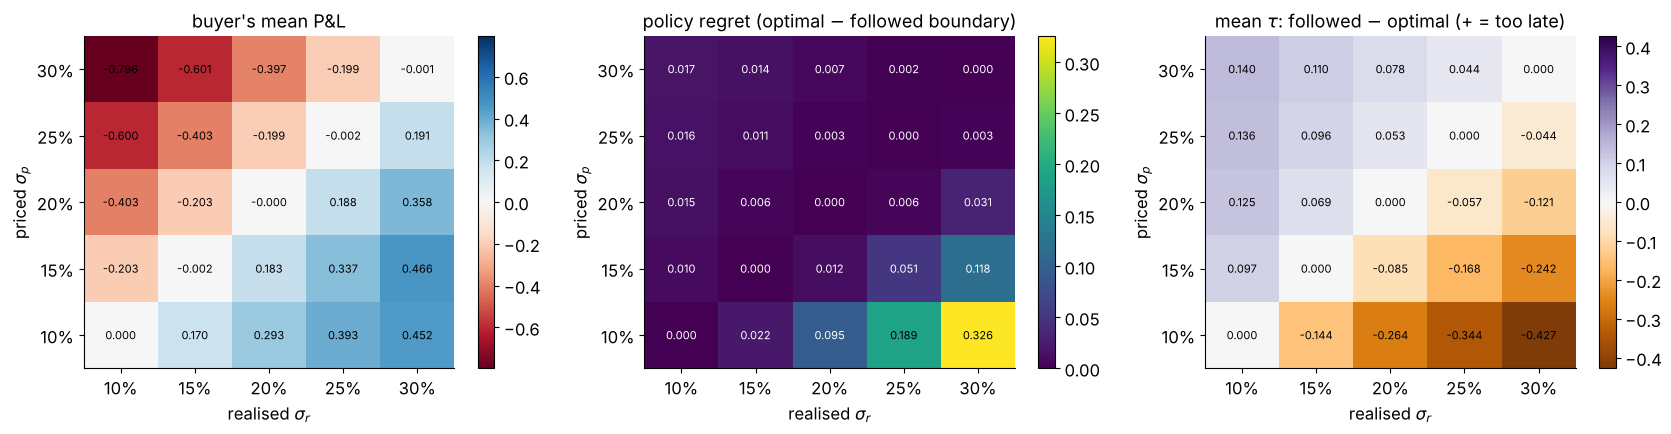

regret matrix:
 [[0.     0.0219 0.0952 0.1892 0.3261]
 [0.0096 0.     0.0116 0.0515 0.1179]
 [0.0146 0.0062 0.     0.0055 0.0307]
 [0.0163 0.0113 0.0033 0.     0.0027]
 [0.0174 0.0143 0.0071 0.0016 0.    ]]
price vega (tree, per unit sigma): 3.900710767362273


In [44]:
sig_list = [0.10, 0.15, 0.20, 0.25, 0.30]; n_chunk, n_chunks = 25_000, 4; n_sim = n_chunk * n_chunks
trees = {s_: CRRTree(vol=s_, r=0.02, steps=800).build_option_tree() for s_ in sig_list}
V_by = {s_: trees[s_].option_tree[0][0] for s_ in sig_list}
mean_pnl = np.zeros((5, 5)); regret = np.zeros((5, 5)); dtau = np.zeros((5, 5)); reg_sq = np.zeros((5, 5))
for jr, sr in enumerate(sig_list):
    mr = trees[sr]; pr = (math.exp(0.02 * mr.dt) - mr.d) / (mr.u - mr.d)
    for ch in range(n_chunks):                       # common random numbers across the priced volatilities
        rng = rng_for(900 + 10 * jr + ch)
        ups = np.concatenate([np.zeros((n_chunk, 1), np.int32), np.cumsum(rng.random((n_chunk, 800)) < pr, axis=1, dtype=np.int32)], axis=1)
        prices = mr.S0 * mr.u ** (2 * ups - np.arange(801)[None, :])
        flags = mr.exercise_grid[np.arange(801)[None, :], ups]; tau_o = np.where(flags.any(1), flags.argmax(1), 800)
        pay_o = np.exp(-0.02 * tau_o * mr.dt) * np.maximum(10 - prices[np.arange(n_chunk), tau_o], 0)
        for ip, sp in enumerate(sig_list):
            hit = prices <= trees[sp].decision_bound[None, :] * (1 + 1e-9)       # NaN compares False
            tau_p = np.where(hit.any(1), hit.argmax(1), 800)
            pay_p = np.exp(-0.02 * tau_p * mr.dt) * np.maximum(10 - prices[np.arange(n_chunk), tau_p], 0)
            mean_pnl[ip, jr] += (pay_p - V_by[sp]).mean() / n_chunks; regret[ip, jr] += (pay_o - pay_p).mean() / n_chunks
            dtau[ip, jr] += ((tau_p - tau_o) * mr.dt).mean() / n_chunks; reg_sq[ip, jr] += ((pay_o - pay_p) ** 2).mean() / n_chunks
reg_se = np.sqrt(np.maximum(reg_sq - regret**2, 0) / n_sim); print(f"policy regret: {n_sim:,} paths per cell, standard error up to {reg_se.max():.4f}")
macro("MapSE", f"{reg_se.max():.4f}"); macro("MapPaths", f"{n_sim:,}".replace(",", r"\,"))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, M_, ttl, cm in [(axes[0], mean_pnl, "buyer's mean P&L", "RdBu"), (axes[1], regret, "policy regret (optimal $-$ followed boundary)", "viridis"), (axes[2], dtau, r"mean $\tau$: followed $-$ optimal (+ = too late)", "PuOr")]:
    vmax = np.abs(M_).max(); im = ax.imshow(M_, origin="lower", cmap=cm, vmin=-vmax if cm != "viridis" else 0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(5)); ax.set_xticklabels([f"{100*s:.0f}%" for s in sig_list]); ax.set_yticks(range(5)); ax.set_yticklabels([f"{100*s:.0f}%" for s in sig_list])
    ax.set(xlabel=r"realised $\sigma_r$", ylabel=r"priced $\sigma_p$", title=ttl); ax.grid(False); fig.colorbar(im, ax=ax)
    for i in range(5):
        for j in range(5): ax.text(j, i, f"{M_[i, j]:.3f}" if abs(M_[i, j]) < 10 else f"{M_[i, j]:.1f}", ha="center", va="center", fontsize=8, color="w" if cm == "viridis" and M_[i, j] < 0.5 * M_.max() else "k")
fig.tight_layout(); save_fig(fig, "misspec_map")
write_table("misspec_map", [r"priced $\sigma_p$"] + [f"real. {100*s:.0f}\\%" for s in sig_list],
            [[f"{100*sp:.0f}\\%"] + [f"{mean_pnl[i, j]:+.3f} / {regret[i, j]:.3f}" for j in range(5)] for i, sp in enumerate(sig_list)], "l" + "c" * 5)
vega_fd = (V_by[0.25] - V_by[0.15]) / 0.10
print("regret matrix:\n", np.round(regret, 4)); print("price vega (tree, per unit sigma):", vega_fd)
macro("MapRegretMax", f"{regret.max():.3f}"); macro("MapRegretLowHigh", f"{regret[0, 4]:.3f}"); macro("MapRegretHighLow", f"{regret[4, 0]:.3f}"); macro("AmVegaTree", f"{vega_fd:.2f}")
macro("MapPnLmismatch", f"{mean_pnl[0, 4]:+.2f}")

## III.18 [EXT] Long maturities revisited (finer lattice) and the speed of convergence to the perpetual limit
In the table of III.7 the row $T=1000$ used $M_{bin}=800$ steps, i.e. $\Delta t=1.25$ and $u=1.25$: a very coarse lattice, which made $V(0,S_0)$ and $b(0;T)$ non-monotone (for example $b(0;1000)=5.5$ although $b(0;100)=5.1$). Here the lattice is refined so that $\Delta t\le0.125$ ($M_{bin}=\max(800,8T)$), the date-0 boundary is found by bisection on the root decision (an exact threshold, instead of a grid in $x$ with step $0.1$), and the distance to the perpetual value is reported on a log scale.

2 800 0.9569 6.933 1.54307


5 800 1.3676 6.262 1.13235


10 800 1.7207 5.812 0.77928


20 800 2.0601 5.466 0.43993


50 800 2.3766 5.223 0.12338


100 800 2.4746 5.196 0.02539


... (3 outputs left out)

lattice T=500: ['2000', '0.2500', '2.49697', '0.00303', '5.255', '0.255']


lattice T=500: ['4000', '0.1250', '2.49805', '0.00195', '5.179', '0.179']


lattice T=500: ['8000', '0.0625', '2.49915', '0.00085', '5.126', '0.126']


lattice T=500: ['16000', '0.0312', '2.49915', '0.00085', '5.089', '0.089']


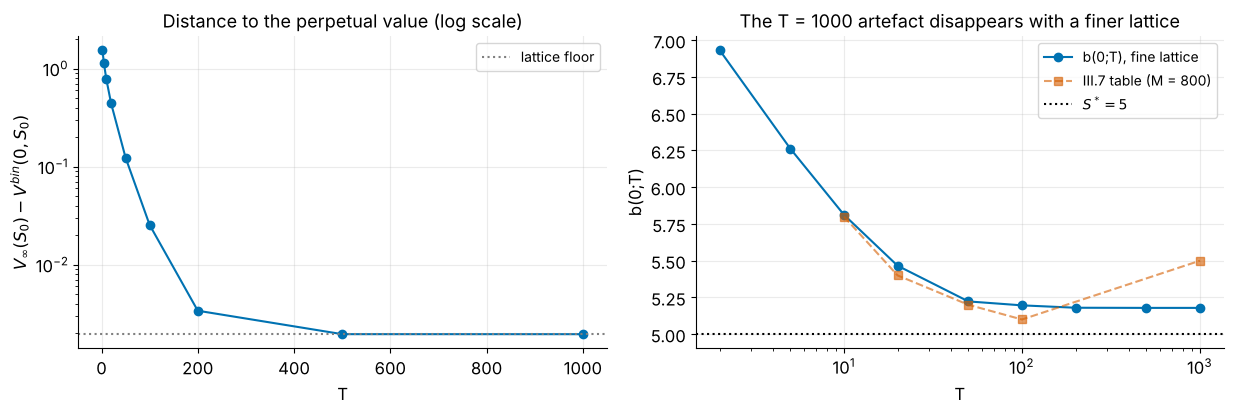

In [45]:
def b0_bisect(T_, M_, lo=3.0, hi=10.0, tol=1e-4):
    # largest spot at which exercise is optimal at date 0 (exercise region = {x <= b}); the root decision is monotone in x
    while hi - lo > tol:
        mid = 0.5 * (lo + hi)
        if tree_price(mid, 10, 0.02, 0.2, T_, M_, "put", american=True, root_flag=True)[1]: lo = mid
        else: hi = mid
    return 0.5 * (lo + hi)

rows, T_fine = [], [2, 5, 10, 20, 50, 100, 200, 500, 1000]
Vd, bd0 = [], []
for T_ in T_fine:
    M_ = max(800, 8 * T_); v_ = tree_price(10, 10, 0.02, 0.2, T_, M_, "put", american=True); b_ = b0_bisect(T_, M_)
    Vd.append(v_); bd0.append(b_)
    rows.append([f"{T_}", f"{M_}", f"{T_/M_:.3f}", f"{v_:.4f}", f"{b_:.3f}", f"{2.5-v_:.4f}", f"{b_-5:.3f}"])
    print(T_, M_, round(v_, 4), round(b_, 3), round(2.5 - v_, 5))
write_table("long_T_refined", ["$T$", "$M_{bin}$", r"$\Delta t$", r"$V^{bin}(0,S_0)$", r"$b(0;T)$", r"$V_\infty-V$", r"$b-S^*$"], rows, "rrrcccc")
gaps_ = np.array([2.5 - v for v in Vd]); floor_ = gaps_[-1]                                 # T = 1000: maturity effect is e^{-28}, what remains is lattice error
k_ = [i for i, T_ in enumerate(T_fine) if 5 <= T_ <= 100]
lam = -np.polyfit(np.array(T_fine)[k_], np.log(gaps_[k_] - floor_), 1)[0]; print("decay rate of V_inf - V(0,S0) - lattice floor in T (5..100):", lam)

# the floor is a lattice effect: refine the lattice at T = 500
rows_l, lat = [], []
for M_ in (2000, 4000, 8000, 16000):
    v_ = tree_price(10, 10, 0.02, 0.2, 500, M_, "put", american=True); b_ = b0_bisect(500, M_, tol=1e-3); lat.append((M_, 500 / M_, v_, b_))
    rows_l.append([f"{M_}", f"{500/M_:.4f}", f"{v_:.5f}", f"{2.5-v_:.5f}", f"{b_:.3f}", f"{b_-5:.3f}"]); print("lattice T=500:", rows_l[-1])
write_table("long_T_lattice", [r"$M_{bin}$", r"$\Delta t$", r"$V^{bin}(0,S_0)$", r"$V_\infty-V$", r"$b(0;T)$", r"$b-S^*$"], rows_l, "rcccc" + "c")
macro("LatBfine", f"{lat[-1][3]:.2f}"); macro("LatVgap", f"{2.5-lat[-1][2]:.5f}"); macro("LatVgapCoarse", f"{2.5-lat[0][2]:.5f}"); macro("LatBcoarse", f"{lat[0][3]:.2f}")
macro("LongDecay", f"{lam:.3f}"); macro("LongFloor", f"{floor_:.4f}"); macro("LongVthousand", f"{Vd[-1]:.4f}"); macro("LongBthousand", f"{bd0[-1]:.2f}"); macro("LongBhundred", f"{bd0[T_fine.index(100)]:.2f}"); macro("LongGapThousand", f"{gaps_[-1]:.1e}")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
axes[0].semilogy(T_fine, gaps_, "o-"); axes[0].axhline(floor_, color="0.5", ls=":", label="lattice floor"); axes[0].legend(); axes[0].set(xlabel="T", ylabel=r"$V_\infty(S_0)-V^{bin}(0,S_0)$", title="Distance to the perpetual value (log scale)")
axes[1].semilogx(T_fine, bd0, "o-", label="b(0;T), fine lattice"); axes[1].semilogx(long_T_table[0], long_T_table[2], "s--", alpha=0.6, label="III.7 table (M = 800)"); axes[1].axhline(5, color="k", ls=":", label="$S^*=5$")
axes[1].set(xlabel="T", ylabel="b(0;T)", title="The T = 1000 artefact disappears with a finer lattice"); axes[1].legend()
fig.tight_layout(); save_fig(fig, "long_T_refined")

# Part IV. Synthesis: which method for which job?
Every method of Parts II and III is run on the same two benchmark problems and ranked by accuracy and CPU time (single core, wall clock). The *work-precision* plot is the honest way to compare a deterministic method (error shrinks with $N$) and a stochastic one (standard error shrinks with $\sqrt{M}$): what matters in practice is the error you get for the time you can spend.

['Black-Scholes closed form', '38.7493', '+0.0000', '--', '0.2']
['CRR tree, $N=252$ (class, lists)', '38.7142', '-0.0350', '--', '11.8']
['CRR tree, $N=252$ (vectorised)', '38.7142', '-0.0350', '--', '0.6']
['CRR tree, $N=1000$ (vectorised)', '38.7404', '-0.0088', '--', '3.4']
['CRR + smoothing + Richardson, $N=252$', '38.7493', '+0.0000', '--', '2.5']
['Leisen-Reimer tree, $N=101$', '38.7491', '-0.0002', '--', '0.2']
['Monte Carlo plain, $M=10^5$ (exact sampler)', '38.5401', '-0.2092', '0.2155', '3.5']
['Monte Carlo control variate, $M=10^5$', '38.6810', '-0.0682', '0.0821', '3.4']
['Monte Carlo Euler $N=252$, $M=10^5$', '38.6841', '-0.0652', '0.2156', '398.1']
['Scrambled Sobol QMC, $2^{16}$ points', '38.7479', '-0.0013', '--', '2.6']


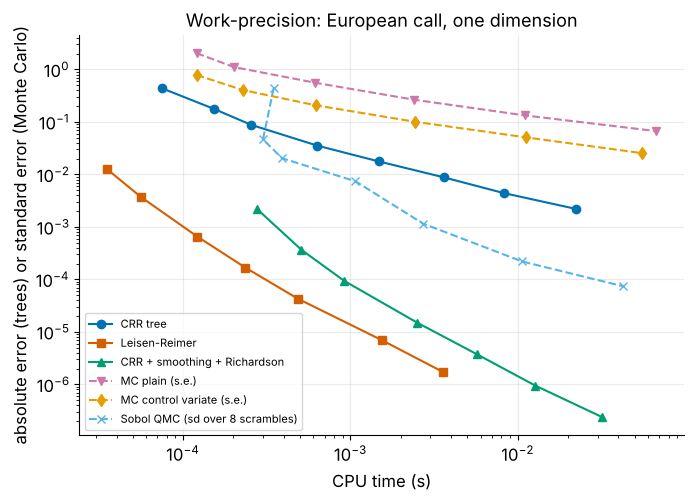

to reach |error| <= 0.001: CRR N=10000 in 93.7 ms; smoothing+Richardson N=201 in 2.1 ms; Leisen-Reimer N=41 in 0.10 ms; plain MC M=4.64e+09 (about 162 s); control variate M=6.00e+08 (about 21 s); Sobol M=131072


In [46]:
# [EXT] desk table 1: NVDA European call (benchmark: Black-Scholes)
S0, K, r, sigma, T = NV_S, NV_K, NV_r, NV_sigma, NV_T = price, price, risk_free_CAD_rate, annualized_252_volatility, 1.0
rows, wp = [], {}
dc = {}
def add_row(name, fn, key=None):
    (val, secs) = timeit(fn); val, se = (val if isinstance(val, tuple) else (val, None))
    rows.append([name, f"{val:.4f}", f"{val-BS:+.4f}", "--" if se is None else f"{se:.4f}", f"{1000*secs:.1f}"])
    if key: dc[key] = (val, se, secs)
    return val, secs
add_row("Black-Scholes closed form", lambda: float(bs_price(S0, K, r, sigma, T)), "bs")
add_row("CRR tree, $N=252$ (class, lists)", lambda: (lambda m: (m.generate_stock_tree(), m.generate_option_tree(), m.pricing())[-1])(CRRBinomialModel(initial_stock_value=S0, strike_price=K, steps=252, days=252)), "class252")
add_row("CRR tree, $N=252$ (vectorised)", lambda: tree_price(S0, K, r, sigma, T, 252), "vec252")
add_row("CRR tree, $N=1000$ (vectorised)", lambda: tree_price(S0, K, r, sigma, T, 1000), "vec1000")
add_row("CRR + smoothing + Richardson, $N=252$", lambda: 2 * tree_price(S0, K, r, sigma, T, 504, smooth=True) - tree_price(S0, K, r, sigma, T, 252, smooth=True), "smoothrich")
add_row("Leisen-Reimer tree, $N=101$", lambda: tree_price(S0, K, r, sigma, T, 101, method="lr"), "lr101")
add_row("Monte Carlo plain, $M=10^5$ (exact sampler)", lambda: mc_estimators(100_000, rng_for(1100))["plain"], "mcplain")
add_row("Monte Carlo control variate, $M=10^5$", lambda: mc_estimators(100_000, rng_for(1101))["control variate"], "mccv")
add_row("Monte Carlo Euler $N=252$, $M=10^5$", lambda: (lambda ST: (math.exp(-r*T)*np.maximum(ST-K, 0).mean(), math.exp(-r*T)*np.maximum(ST-K, 0).std(ddof=1)/math.sqrt(len(ST))))(gbm_euler_terminal(S0, r, sigma, T, 252, 100_000, rng_for(1102))), "mceuler")
add_row("Scrambled Sobol QMC, $2^{16}$ points", lambda: float((math.exp(-r*T)*np.maximum(terminal_exact(norm.ppf(qmc.Sobol(1, scramble=True, seed=11).random_base2(16)[:, 0])) - K, 0)).mean()), "sobol")
write_table("desk_call", ["Method", "price", "error vs BS", "s.e.", "CPU (ms)"], rows, "lcccr")
for rw in rows: print(rw)
ms = lambda k: f"{1000*dc[k][2]:.1f}"
macro("DeskCrrClassMs", f"{1000*dc['class252'][2]:.0f}"); macro("DeskCrrVecMs", ms("vec252")); macro("DeskCrrVecErr", f"{dc['vec252'][0]-BS:+.3f}")
macro("DeskLrErr", f"{abs(dc['lr101'][0]-BS):.4f}"); macro("DeskLrMs", ms("lr101")); macro("DeskSmoothMs", ms("smoothrich")); macro("DeskSmoothErr", f"{abs(dc['smoothrich'][0]-BS):.4f}")
macro("DeskMcPlainErr", f"{abs(dc['mcplain'][0]-BS):.3f}"); macro("DeskMcPlainSE", f"{dc['mcplain'][1]:.3f}"); macro("DeskMcPlainMs", ms("mcplain"))
macro("DeskMcCvSE", f"{dc['mccv'][1]:.3f}"); macro("DeskMcCvErr", f"{abs(dc['mccv'][0]-BS):.3f}"); macro("DeskMcEulerMs", ms("mceuler"))
macro("DeskSobolErr", f"{abs(dc['sobol'][0]-BS):.4f}"); macro("DeskSobolMs", ms("sobol")); macro("DeskCrrThousandMs", ms("vec1000"))

# work-precision for the call: error (or standard error) against CPU time
fig, ax = plt.subplots(figsize=(7.8, 5.2))
for nm, fn, Ns_, mk in [("CRR tree", lambda N: tree_price(S0, K, r, sigma, T, N), [20, 50, 100, 250, 500, 1000, 2000, 4000], "o"),
                        ("Leisen-Reimer", lambda N: tree_price(S0, K, r, sigma, T, N, method="lr"), [11, 21, 51, 101, 201, 501, 1001], "s"),
                        ("CRR + smoothing + Richardson", lambda N: 2 * tree_price(S0, K, r, sigma, T, 2 * N, smooth=True) - tree_price(S0, K, r, sigma, T, N, smooth=True), [20, 50, 100, 250, 500, 1000, 2000], "^")]:
    ts, es = [], []
    for N in Ns_:
        v, secs = timeit(fn, N); ts.append(secs); es.append(max(abs(v - BS), 1e-13))
    ax.loglog(ts, es, mk + "-", label=nm)
for nm, key, mk in [("MC plain (s.e.)", "plain", "v"), ("MC control variate (s.e.)", "control variate", "d")]:
    ts, es = [], []
    for M in [2**k for k in range(10, 21, 2)]:
        o, secs = timeit(mc_estimators, M, rng_for(1200 + M % 97)); ts.append(secs); es.append(o[key][1])
    ax.loglog(ts, es, mk + "--", label=nm)
ts, es = [], []
for m_ in range(8, 21, 2):
    vals = []; t0 = time.perf_counter()
    for k in range(8): vals.append((math.exp(-r*T)*np.maximum(terminal_exact(norm.ppf(qmc.Sobol(1, scramble=True, seed=k).random_base2(m_)[:, 0])) - K, 0)).mean())
    ts.append((time.perf_counter() - t0) / 8); es.append(max(np.std(vals, ddof=1), 1e-9))
ax.loglog(ts, es, "x--", label="Sobol QMC (sd over 8 scrambles)")
ax.set(xlabel="CPU time (s)", ylabel="absolute error (trees) or standard error (Monte Carlo)", title="Work-precision: European call, one dimension"); ax.legend(fontsize=8)
save_fig(fig, "work_precision")

# [EXT] cost of reaching a given accuracy: smallest N (trees) or M (Monte Carlo) with error <= tol, and the time it takes
tol = 1e-3
def first_hit(fn, Ns_list):
    for N in Ns_list:
        v, secs = timeit(fn, N)
        if abs(v - BS) <= tol: return N, secs
    return None, float("nan")
wp_crr = first_hit(lambda N: tree_price(S0, K, r, sigma, T, N), [1000, 2000, 4000, 5000, 8000, 10_000, 12_000, 16_000, 20_000, 40_000])
wp_lr = first_hit(lambda N: tree_price(S0, K, r, sigma, T, N, method="lr"), [11, 21, 31, 41, 51, 71, 101, 201])
wp_sm = first_hit(lambda N: 2 * tree_price(S0, K, r, sigma, T, 2 * N, smooth=True) - tree_price(S0, K, r, sigma, T, N, smooth=True), [21, 51, 101, 201, 401, 801])
sd_pay = dc["mcplain"][1] * math.sqrt(100_000)                          # sd of one discounted payoff
per_sample = dc["mcplain"][2] / 100_000                                 # seconds per plain sample
M_plain = (sd_pay / tol) ** 2; M_cv = M_plain * (vr_res[vr_Ms[-1]]["control variate"][1] / vr_res[vr_Ms[-1]]["plain"][1]) ** 2
sob = None
for m_ in range(8, 23):
    vals = [(math.exp(-r*T)*np.maximum(terminal_exact(norm.ppf(qmc.Sobol(1, scramble=True, seed=k).random_base2(m_)[:, 0])) - K, 0)).mean() for k in range(8)]
    if np.std(vals, ddof=1) <= tol: sob = (2**m_, per_sample * 2**m_); break
print(f"to reach |error| <= {tol}: CRR N={wp_crr[0]} in {1000*wp_crr[1]:.1f} ms; smoothing+Richardson N={wp_sm[0]} in {1000*wp_sm[1]:.1f} ms; Leisen-Reimer N={wp_lr[0]} in {1000*wp_lr[1]:.2f} ms;"
      f" plain MC M={M_plain:.2e} (about {per_sample*M_plain:.0f} s); control variate M={M_cv:.2e} (about {per_sample*M_cv:.0f} s); Sobol M={sob[0] if sob else None}")
macro("WPtol", f"{tol:g}"); macro("WPcrrN", f"{wp_crr[0]:,}".replace(",", r"\,")); macro("WPcrrMs", f"{1000*wp_crr[1]:.0f}")
macro("WPlrN", f"{wp_lr[0]}"); macro("WPlrMs", f"{1000*wp_lr[1]:.2f}"); macro("WPsmN", f"{wp_sm[0]}"); macro("WPsmMs", f"{1000*wp_sm[1]:.0f}")
macro("WPmcM", f"{M_plain:.1e}".replace("e+0", r"\times10^{").replace("e+", r"\times10^{") + "}"); macro("WPmcSec", f"{per_sample*M_plain:.0f}"); macro("WPcvSec", f"{per_sample*M_cv:.0f}")
macro("WPsobolM", f"{sob[0]:,}".replace(",", r"\,") if sob else "n/a")

In [47]:
# [EXT] desk table 2: American put baseline (reference: Richardson-extrapolated tree)
rows = []
def add_am(name, fn, key=None):
    (val, secs) = timeit(fn); val, se = (val if isinstance(val, tuple) else (val, None))
    rows.append([name, f"{val:.5f}", f"{val-V_ref:+.5f}", "--" if se is None else f"{se:.4f}", f"{1000*secs:.0f}"])
    if key: da[key] = (val, se, secs)
    return val
da = {}
add_am("European put (Black-Scholes), for reference", lambda: float(bs_price(10, 10, 0.02, 0.2, 1.0, "put")), "eu")
add_am("CRR tree, $M=800$ (class, lists)", lambda: CRRTree(steps=800).build_option_tree().option_tree[0][0], "class800")
add_am("CRR tree, $M=800$ (vectorised)", lambda: tree_price(10, 10, 0.02, 0.2, 1.0, 800, "put", american=True), "vec800")
add_am("CRR tree, $M=1600$ (vectorised)", lambda: tree_price(10, 10, 0.02, 0.2, 1.0, 1600, "put", american=True), "vec1600")
add_am("CRR tree + Richardson ($M=3200,6400$): reference", lambda: 2 * tree_price(10, 10, 0.02, 0.2, 1.0, 6400, "put", american=True) - tree_price(10, 10, 0.02, 0.2, 1.0, 3200, "put", american=True), "ref")
add_am("PDE, Crank-Nicolson + penalty, $801\\times200$", lambda: pde_put(10, 10, 0.02, 0.2, 1.0, 801, 200)["value"], "pde801")
add_am("PDE, Crank-Nicolson + penalty, $3201\\times800$", lambda: pde_put(10, 10, 0.02, 0.2, 1.0, 3201, 800)["value"], "pde3201")
add_am("Longstaff-Schwartz, 50 dates, $2\\cdot10^5$ paths", lambda: lsm_put(10, 10, 0.02, 0.2, 1.0, 50, 200_000, rng_for(1300)), "lsm")
add_am("Barone-Adesi-Whaley approximation", lambda: float(baw_put(10.0, 10, 0.02, 0.2, 1.0)[0]), "baw")
write_table("desk_put", ["Method", "price", "error vs reference", "s.e.", "CPU (ms)"], rows, "lccrr")
for rw in rows: print(rw)
msa = lambda k: f"{1000*da[k][2]:.0f}"
macro("DeskPutClassMs", msa("class800")); macro("DeskPutVecMs", msa("vec800")); macro("DeskPutTreeMs", msa("vec1600")); macro("DeskPutTreeErr", f"{abs(da['vec1600'][0]-V_ref):.5f}")
macro("DeskPutRefMs", msa("ref")); macro("DeskPdeCoarseErr", f"{abs(da['pde801'][0]-V_ref):.5f}"); macro("DeskPdeCoarseMs", msa("pde801"))
macro("DeskPdeFineErr", f"{abs(da['pde3201'][0]-V_ref):.5f}"); macro("DeskPdeFineMs", msa("pde3201"))
macro("DeskLsmErr", f"{abs(da['lsm'][0]-V_ref):.4f}"); macro("DeskLsmSE", f"{da['lsm'][1]:.4f}"); macro("DeskLsmMs", msa("lsm")); macro("DeskBawErr", f"{abs(da['baw'][0]-V_ref):.4f}"); macro("DeskBawMs", msa("baw"))

['European put (Black-Scholes), for reference', '0.69359', '-0.01749', '--', '0']
['CRR tree, $M=800$ (class, lists)', '0.71094', '-0.00014', '--', '24']
['CRR tree, $M=800$ (vectorised)', '0.71094', '-0.00014', '--', '15']
['CRR tree, $M=1600$ (vectorised)', '0.71101', '-0.00007', '--', '51']
['CRR tree + Richardson ($M=3200,6400$): reference', '0.71108', '+0.00000', '--', '533']
['PDE, Crank-Nicolson + penalty, $801\\times200$', '0.71100', '-0.00008', '--', '132']
['PDE, Crank-Nicolson + penalty, $3201\\times800$', '0.71107', '-0.00001', '--', '1361']
['Longstaff-Schwartz, 50 dates, $2\\cdot10^5$ paths', '0.71267', '+0.00159', '0.0019', '1402']
['Barone-Adesi-Whaley approximation', '0.70999', '-0.00109', '--', '1']


## Export: numbers for the report and the code listing
`macros.tex` defines one `\newcommand` per number quoted in the text, so the report cannot drift from the notebook. A leading sign is wrapped in `\ensuremath{}` so it prints correctly in text and in math mode. The code listing for the appendix is cut out of this notebook with the `ast` module: the hand-written classes and functions in `handwritten.py`, the extensions in `extensions.py`.

In [48]:
import ast, nbformat
import re
def fix_sign(v):
    v = str(v)
    m_ = re.fullmatch(r"([-+]?)(\d+(?:\.\d+)?)e([-+])0*(\d+)", v)          # 8.4e-02 -> 8.4\times10^{-2}
    if m_:
        sgn, mant, es, ex = m_.groups(); return (("\\ensuremath{-}" if sgn == "-" else "") + r"\ensuremath{" + mant + r"\times10^{" + ("-" if es == "-" else "") + ex + "}}")
    return ("\\ensuremath{-}" + v[1:]) if v.startswith("-") else (("\\ensuremath{+}" + v[1:]) if v.startswith("+") else v)
lines = ["% AUTO-GENERATED by notebooks/option_pricing.ipynb: do not edit by hand"] + [rf"\newcommand{{\{k}}}{{{fix_sign(v)}}}" for k, v in sorted(MACROS.items())]
Path("macros.tex").write_text("\n".join(lines) + "\n"); print(len(MACROS), "macros written")

nb_path = Path("../notebooks/option_pricing.ipynb")
HAND = ["BrownianMotion", "symmetric_random_walk", "CRRBinomialModel", "black_scholes_call", "gbm_euler_maruyama", "gbm_exact",
        "plotsmart", "perp_params", "Vinf", "CRRTree", "hedgingformula", "try_paths", "simulate_10000_paths", "simulate_with_priced_boundary", "CRRDiscretize_run"]
if nb_path.exists():
    src = "\n\n".join("".join(c["source"]) for c in nbformat.read(nb_path, as_version=4).cells if c["cell_type"] == "code")
    src = "\n".join(l for l in src.splitlines() if not l.startswith("%"))
    tree_ast = ast.parse(src); hand, ext = [], []
    for node in tree_ast.body:
        if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
            seg = ast.get_source_segment(src, node); (hand if node.name in HAND else ext).append(seg)
    Path("code").mkdir(exist_ok=True)
    Path("code/handwritten.py").write_text("# Hand-written classes and functions, exactly as used in the notebook\nimport math, random\nimport numpy as np\nimport matplotlib.pyplot as plt\n\n" + "\n\n".join(hand) + "\n")
    Path("code/extensions.py").write_text("# Extensions that build on the hand-written code (fast trees, Greeks, PDE solver, LSM, BAW, hedging experiments, ...)\n\n" + "\n\n".join(ext) + "\n")
    print("code listing:", len(hand), "hand-written definitions,", len(ext), "extension definitions")
else:
    print("notebook not on disk yet (run through nbconvert to write the code listing)")

195 macros written
code listing: 15 hand-written definitions, 35 extension definitions
